# Hybrid weak/strong interpolation with Bayesian model averaging

Each operator and flow time is fitted separately after the shared chiral and infinite-volume limits. The default weak choices are a one-loop-anchored, monotonically decreasing polynomial and the same polynomial with a free constant. The strong choices retain the pole-safe Eq. (7) rational form. A $C^1$ connection lies entirely in the unmeasured gap after $\beta_b=8$. Original Fit 4/Fit 11 branches remain selectable; the standard fit-specific notebooks are unchanged.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import copy, gc, json, sys
import time as time_module

REPO_ROOT = Path.cwd().resolve()
while REPO_ROOT != REPO_ROOT.parent and not (REPO_ROOT / 'pyproject.toml').is_file():
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / 'pyproject.toml').is_file():
    raise RuntimeError('Run this notebook from inside the ContinuousBetaFunction repository')
sys.path.insert(0, str(REPO_ROOT / 'src'))

import betafn
import gvar as gv
import lsqfit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from IPython.display import display

print('betafn package:', Path(betafn.__file__).resolve())
print('repository:', REPO_ROOT)

_PROGRESS_START_TIMES = {}
def progress_start(label):
    _PROGRESS_START_TIMES[label] = time_module.monotonic()
    print(f'[START] {label}', flush=True)

def progress_done(label):
    started = _PROGRESS_START_TIMES.pop(label, None)
    elapsed = time_module.monotonic() - started if started is not None else 0.0
    print(f'[DONE] {label} ({elapsed / 60.0:.1f} min)', flush=True)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern'], 'font.size': 15,
    'figure.dpi': 300, 'savefig.dpi': 300,
    'axes.labelsize': 20, 'axes.titlesize': 18,
    'legend.fontsize': 11, 'xtick.labelsize': 18, 'ytick.labelsize': 18,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'grid.alpha': .35, 'grid.linestyle': '-', 'axes.axisbelow': True,
})

betafn package: /Users/yaman/Downloads/ContinuousBetaFunction/src/betafn/__init__.py
repository: /Users/yaman/Downloads/ContinuousBetaFunction


## Configuration and complete window catalogue

Change physics/statistical choices only here. Every downstream cell reads these values.

In [52]:
# Stable output identifier only; active models are selected below.
ANALYSIS_ID = 'hybrid_fit4_fit11_eq7_linear_bma_independent_flow_times'
ANALYSIS_FOOTER = 'hybridBMA'
CORRECTION = 'tln'
DATA_DIR = Path('/Users/yaman/Contbetafn/data/New Four')
HYBRID_OUTPUT_ROOT = REPO_ROOT / 'src/betafn/hybrid_fit4_fit11_eq7_linear_bma_independent_flow_times'
OUTPUT_ROOT = HYBRID_OUTPUT_ROOT
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Strong-coupling ensembles use three finite masses on each of L/a=20, 24, 32.
# This includes the newly available beta_b=7.125 ensembles.
STRONG_COUPLINGS = ('7p00', '7p125', '7p25', '7p50')
WEAK_COUPLINGS = (
    '8p00', '8p50', '9p00', '9p50', '10p0', '11p0',
    '12p0', '14p0', '16p0', '18p0', '20p0',
)
COUPLINGS = STRONG_COUPLINGS + WEAK_COUPLINGS
STRONG_VOLUMES = ('l20l20l20t40', 'l24l24l24t48', 'l32l32l32t64')
EXPECTED_CHIRAL_MASSES = ('0p001', '0p0025', '0p005')
VOLUMES = {
    **{coupling: STRONG_VOLUMES for coupling in STRONG_COUPLINGS},
    '8p00': (
        'l32l32l32t64', 'l40l40l40t80', 'l48l48l48t96',
    ),
    **{
        coupling: ('l32l32l32t64', 'l40l40l40t80', 'l48l48l48t96')
        for coupling in WEAK_COUPLINGS if coupling != '8p00'
    },
}
FLOW = 'wilson'
OBSERVABLES = ('p', 'c', 's')
OP_LABELS = {'p': 'Wilson', 'c': 'clover', 's': 'Symanzik'}
# Match the operator convention used in the reference scan notebook.
OP_COLORS = {
    'p': plt.cm.YlOrRd(0.75),
    'c': plt.cm.YlGn(0.75),
    's': plt.cm.Greys(0.75),
}

# Flow-time windows remain an explicit analysis choice. Every selected
# window is analyzed independently; CENTRAL_WINDOW is the primary result.
TMIN_VALUES = tuple(range(5, 6))
TMAX_LIMIT = 6
WINDOWS = tuple(
    (float(tmin), float(tmax))
    for tmin in TMIN_VALUES
    for tmax in range(tmin + 1, TMAX_LIMIT + 1)
)
CENTRAL_WINDOW = (5.0, 6.0)
FIT_TIME_WINDOW = (
    min(window[0] for window in WINDOWS),
    max(window[1] for window in WINDOWS),
)
# Extend through the t0-defining coupling, g_GF^2(t0) ~= 15.79.
# Domain checks in cnt_xtrp still prevent unsupported extrapolation.
G2_GRID = (0.9, 16.0, 0.1)
TARGET_G2 = (1.0, 1.5, 3.0, 5.0, 8.0, 10.0, 12.0, 15.8)
# t0^2 <E(t0)> = 0.3 and g_GF^2 = (16 pi^2 / 3) t^2 <E>.
G2_T0 = (8.0 / 5.0) * np.pi**2

# -------------------------------------------------------------------------
# BMA MODEL SELECTION -- edit only this block to choose included models.
# -------------------------------------------------------------------------
# Each weak family can have its own selected correction orders. Delete a
# family or an order here to exclude it from the BMA.
# These are new weak models, not relabelled Fit4/Fit11. Order N is the
# degree of the positive slope factor (beta itself has degree N+2).
# Explicit implemented ansatz, with x=g_GF^2 and L=4*pi:
#   beta_mon(x) = -2*b0 * integral_0^x ds s * sum_{k=0}^N
#                 w_k B_{k,N}(s/L),
#   beta_mon_const(x) = a0 + beta_mon(x).
# Here B_{k,N} is the Bernstein basis, w_0=1, and
# w_k=exp(q_k)>0 for k>=1 with q_k~Normal(0,weak_width^2).
# 'monotone' fixes a0=0; 'monotone_constant' fits
# a0~Normal(0,constant_width^2). Thus beta'(x)<0 for 0<x<=L,
# and beta_mon(x)=-b0*x^2+O(x^3) at weak coupling.
# For the original models select 'fit4'/'fit11' instead and restore their
# previous weak_width=5.0 if reproducing that prior specification.
HYBRID_WEAK_ORDERS_BY_FAMILY = {
    'monotone': (6,7,8),
    'monotone_constant': (6,7,8),
    # Optional established weak-coupling families. Uncomment only the
    # families to include in the BMA; evidence requires the proper
    # Gaussian coefficient priors in HYBRID_PRIOR_WIDTHS below.
    # 'fit4': (4, 5),
    # 'fit5': (1, 2),       # fixed PT3 + 1 or 2 terms u^3, u^4
    # 'fit6': (2, 3),       # free two-loop coefficient + higher terms
    # 'fit7': (1, 2),       # free three-loop coefficient + higher terms
    # 'fit8': (3, 4),       # multiplicative PT3, c1=0
    # 'fit9': (4, 5),       # multiplicative PT3, c2=0
    # 'fit10': (4, 5),      # free c0, c1=c2=0
    # 'fit11': (4, 5),
}

# Eq. (7) orders are (N, N+1): beta(x) has an x^2 prefactor, so the
# extra denominator power enforces the observed beta(x) ~ x behavior.
HYBRID_STRONG_FORM = 'eq7_linear'
HYBRID_PADE_ORDERS = (
    (1, 2),
    (2, 3),
    (3, 4),
)
# C1 rational Hermite connection entirely inside the unmeasured gap.
# The weak branch is unchanged through beta_b=8 plus 5% of the gap.
# The legacy internal form name is retained for coefficient-checkpoint reuse.
HYBRID_MATCH_FRACTIONS = (None,)
HYBRID_MATCH_BOUNDS = (0.20, 0.80)
HYBRID_CONTINUITIES = (1,)  # gap-only C1 connection, no measured-region shoulders

# Leave this as None to use the Cartesian selection above. Alternatively,
# provide an exact list of models, for example:
# HYBRID_EXPLICIT_MODELS = (
#     dict(weak_family='fit4', weak_order=4,
#          numerator_order=1, denominator_order=2,
#          match_fraction=None, continuity=1, strong_form='eq7_linear'),
#     dict(weak_family='fit11', weak_order=5,
#          numerator_order=2, denominator_order=3,
#          match_fraction=None, continuity=1, strong_form='eq7_linear'),
# )
HYBRID_EXPLICIT_MODELS = None

# Independent operator/flow-time/candidate fits run in separate processes.
# Interpolation workers hold larger fit state; continuum workers receive
# only small numeric GLS tasks and can therefore use more CPUs safely.
HYBRID_MAX_WORKERS = 2
HYBRID_CONTINUUM_WORKERS = 4
HYBRID_CHECKPOINT_ROOT = HYBRID_OUTPUT_ROOT / 'interpolation_checkpoints'

RUN_HYBRID_THINNING = False
HYBRID_THINNING_SPACINGS = (0.10, 0.20, 0.30)
HYBRID_PRIOR_WIDTHS = {
    'weak_width': 1.5,  # logw_k ~ N(0,1.5^2); w_k=exp(logw_k)>0
    'constant_width': 0.25,
    'strong_width': 2.0,
    'pole_log_width': 1.0,
}

def window_tag(window):
    return f't_{window[0]:g}_{window[1]:g}'.replace('.', 'p')

def case_dir(window, mode=None):
    path = OUTPUT_ROOT / window_tag(window)
    if mode is not None:
        path = path / mode
    path.mkdir(parents=True, exist_ok=True)
    return path

def add_fit_footer(fig):
    fig.text(0.995, 0.005, ANALYSIS_FOOTER, ha='right', va='bottom',
             fontsize=8, color='gray', alpha=.75)

def save_figure(fig, window, name, mode=None):
    base = case_dir(window, mode) / name
    add_fit_footer(fig)
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def beta_value(coupling):
    return float(coupling.replace('p', '.'))

def volume_value(volume):
    return np.prod([float(x) for x in volume.replace('t', 'l').split('l')[1:] if x])


def coupling_figure(couplings, ncols=5):
    nrows = max(1, int(np.ceil(len(couplings) / ncols)))
    return plt.subplots(
        nrows, ncols,
        figsize=(4.4 * ncols, 4.2 * nrows),
        squeeze=False,
    )

def validate_dataset_layout(data_dir):
    """Fail before processing unless every configured ensemble is present."""
    if not data_dir.is_dir():
        raise FileNotFoundError(data_dir)
    discovered = betafn.SetupBetaFunction.discover_dataset(
        data_dir, flows=[FLOW]
    )
    rows = []
    missing = []
    for coupling in COUPLINGS:
        expected_masses = (
            EXPECTED_CHIRAL_MASSES
            if coupling in STRONG_COUPLINGS else ('0p00',)
        )
        for volume in VOLUMES[coupling]:
            for mass in expected_masses:
                flows = (
                    discovered.get(coupling, {})
                    .get(volume, {})
                    .get(mass, ())
                )
                available = FLOW in flows
                rows.append({
                    'coupling': coupling,
                    'beta_b': beta_value(coupling),
                    'volume': volume,
                    'mass': mass,
                    'flow': FLOW,
                    'available': available,
                })
                if not available:
                    missing.append(
                        f'{coupling}_{volume}_{mass}_{FLOW}.bin'
                    )
    inventory = pd.DataFrame(rows)
    if missing:
        preview = ', '.join(missing[:12])
        suffix = (
            '' if len(missing) <= 12
            else f', ... ({len(missing)} missing)'
        )
        raise FileNotFoundError(
            f'dataset is missing required ensembles: {preview}{suffix}'
        )
    summary = {
        'discovered_couplings': len(discovered),
        'required_ensemble_mass_points': len(inventory),
        'beta_7p125_ensemble_mass_points': int(
            (inventory.coupling == '7p125').sum()
        ),
    }
    return inventory, summary

def pt_over_g4(x, loops):
    x = np.asarray(x, dtype=float)
    pt = bf.perturbative_beta_function
    return sum(-coefficient * x**power / pt.nrm**(power + 1)
               for power, coefficient in enumerate(pt.b[:loops]))

print(f'{len(WINDOWS)} flow-time windows:', WINDOWS)
print('output root:', OUTPUT_ROOT)


1 flow-time windows: ((5.0, 6.0),)
output root: /Users/yaman/Downloads/ContinuousBetaFunction/src/betafn/hybrid_fit4_fit11_eq7_linear_bma_independent_flow_times


## Analysis construction

The pulled upstream package computes TLN on demand. No external `.tln` path is supplied. The raw `Es` history is the rectangle measurement and is replaced by `(5/3)Ep-(2/3)Es` before averaging and TLN. Before any processing, the notebook checks the same 69 required ensemble--mass combinations as the batch runner, including all nine $\beta_b=7.125$ volume--mass combinations.

In [3]:
DATASET_INVENTORY, DATASET_VALIDATION = validate_dataset_layout(DATA_DIR)
display(pd.DataFrame([DATASET_VALIDATION]))
display(DATASET_INVENTORY.query("coupling == '7p125'"))

# Validate the repository-external blinding secret without displaying it.
from betafn.blinding import load_lambda_blinding_factor
load_lambda_blinding_factor()

bf = betafn.BetaFunction(nf=4)

# AnalysisConfig requires an interpolation field for shared stages 1--3.
# The hybrid candidate fits below bypass this placeholder completely.
def _unused_interpolation(x, parameters):
    return np.zeros_like(np.asarray(x, dtype=float))

interpolation = betafn.InterpolationSpec(
    fcn=_unused_interpolation, prior=None, p0={}, xerrors=False,
)

config = betafn.AnalysisConfig(
    data_path=str(DATA_DIR),
    interpolation=interpolation,
    continuum_window=CENTRAL_WINDOW,
    g2_grid=G2_GRID,
    flows=(FLOW,),
    observables=OBSERVABLES,
    combine={'s': {'p': 5.0 / 3.0, 's': -2.0 / 3.0}},
    couplings=COUPLINGS,
    volumes=VOLUMES,
    correction=CORRECTION,
    binsize=1,  # spectral estimator uses the ordered, unbinned history
    covariance_estimator='lugsail',
    bartlett_bandwidth_method='plugin',
    bartlett_window_factor=5.0,
    bartlett_max_fraction=0.25,
    lugsail_r=2.0, lugsail_c=0.5, spectral_psd_adjust=True,
    process_window=(1.5, 10.5),
    fit_window=FIT_TIME_WINDOW,
    error_mode='fit',
    cov_mode='empirical',
    correlated=True,
    verbosity=1,  # progress only; does not alter any fit
)
config_summary = config.describe()
config_summary.pop('interpolation_xerrors')
config_summary.pop('interpolation_parameters')
display(pd.DataFrame([config_summary]).T.rename(columns={0: 'hybrid analysis setting'}))

,discovered_couplings,required_ensemble_mass_points,beta_7p125_ensemble_mass_points
0,20,69,9


,coupling,beta_b,volume,mass,flow,available
9,7p125,7.125,l20l20l20t40,0p001,wilson,True
10,7p125,7.125,l20l20l20t40,0p0025,wilson,True
11,7p125,7.125,l20l20l20t40,0p005,wilson,True
12,7p125,7.125,l24l24l24t48,0p001,wilson,True
13,7p125,7.125,l24l24l24t48,0p0025,wilson,True
14,7p125,7.125,l24l24l24t48,0p005,wilson,True
15,7p125,7.125,l32l32l32t64,0p001,wilson,True
16,7p125,7.125,l32l32l32t64,0p0025,wilson,True
17,7p125,7.125,l32l32l32t64,0p005,wilson,True


,hybrid analysis setting
data_path,/Users/yaman/Contbetafn/data/New Four
flows,[wilson]
observables,"[p, c, s]"
couplings,"[7p00, 7p125, 7p25, 7p50, 8p00, 8p50, 9p00, 9p..."
volumes,"{'7p00': ['l20l20l20t40', 'l24l24l24t48', 'l32..."
correction,tln
binsize,1
use_gamma_method,False
gamma_window_factor,3.0
covariance_estimator,lugsail


## Stage 1 — processing with TLN

For each ensemble, $\mathbf z_n$ contains every retained flow time and operator measured on configuration $n$. The covariance of the ensemble mean uses the zero-lugsail Bartlett spectral estimator
$$\widehat{\mathrm{Cov}}(\bar{\mathbf z})=\frac{1}{N}\left[\widehat\Gamma(0)+\sum_{k=1}^{M}\left(1-\frac{k}{M+1}\right)\left(\widehat\Gamma(k)+\widehat\Gamma(k)^T\right)\right],$$
and $\widehat\Sigma_L(M)=2\widehat\Sigma_B(M)-\widehat\Sigma_B(\lfloor M/2\rfloor)$. The Liu--Vats--Flegal marginal-AR plug-in rule selects one common $M$ for the complete vector. This preserves correlations across flow times and operators. The table records the bandwidth scan, overlapping-batch-means comparison, and any explicit positive-semidefinite adjustment.

In [4]:
progress_start('processing and covariance estimation')
bf.run_processing(config)
bartlett_rows = [
    {'coupling': ensemble.coupling, 'volume': ensemble.volume,
     'mass': ensemble.mass, **diagnostics}
    for ensemble, diagnostics in sorted(
        bf.covariance_estimator_diagnostics.items(),
        key=lambda item: item[0].sort_key,
    )
]
BARTLETT_DIAGNOSTICS = pd.DataFrame(bartlett_rows)
progress_done('processing and covariance estimation')
print('correction:', CORRECTION)
print('processed couplings:', sorted(bf.avg_data, key=beta_value))
print('pre-binning: not applied; lugsail Bartlett uses the ordered raw history')
BARTLETT_DIAGNOSTICS.to_csv(
    OUTPUT_ROOT / 'bartlett_covariance_diagnostics.csv', index=False
)
display(BARTLETT_DIAGNOSTICS)

[START] processing and covariance estimation
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
beta_b = 7.00, vol = l20l20l20t40, mass = 0p001
dt = 9.5 (secs)
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
beta_b = 7.00, vol = l20l20l20t40, mass = 0p0025
dt = 9.13 (secs)
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
beta_b = 7.00, vol = l20l20l20t40, mass = 0p005
dt = 8.95 (secs)
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
beta_b = 7.00, vol = l24l24l24t48, mass = 0p001
dt = 9.03 (secs)
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
beta_b = 7.00, vol = l24l24l24t48, mass = 0p0025
dt = 8.84 (secs)
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
beta_b = 7.00, vol = l24l24l24t48, mass = 0p005
dt = 8.82 (secs)
-.-

,coupling,volume,mass,n_configurations,n_observables,estimator,bandwidth_method,bandwidth,bandwidth_fraction,plugin_unbounded_bandwidth,...,fallback_reason,vanilla_median_se_ratio,obm_batch_size,obm_median_se_ratio,obm_max_abs_log_se_ratio,scan_lower_bandwidth,scan_upper_bandwidth,scan_lower_median_se_ratio,scan_upper_median_se_ratio,scan_max_abs_log_se_ratio
0,7p00,l20l20l20t40,0p001,277,3604,lugsail-bartlett,plugin,19,0.068592,19.495939,...,,0.947536,20,0.960283,0.419177,9,38,1.008561,0.890940,0.406140
1,7p00,l20l20l20t40,0p0025,200,3604,lugsail-bartlett,plugin,20,0.100000,22.881018,...,,0.911135,21,0.953670,0.143568,10,40,0.932130,1.044453,0.626481
2,7p00,l20l20l20t40,0p005,180,3604,lugsail-bartlett,plugin,18,0.100000,18.439756,...,,0.874139,19,0.962201,0.097042,9,36,0.844792,1.120250,0.531095
3,7p00,l24l24l24t48,0p001,77,3604,lugsail-bartlett,plugin,7,0.090909,8.543878,...,,0.873773,8,0.913854,0.176590,3,14,0.830065,1.141801,0.344536
4,7p00,l24l24l24t48,0p0025,71,3604,lugsail-bartlett,plugin,7,0.098592,9.144081,...,,0.888012,8,0.988296,0.189612,3,14,0.890705,1.065981,0.187586
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,18p0,l40l40l40t80,0p00,770,3604,lugsail-bartlett,plugin,9,0.011688,9.396411,...,,0.947028,10,0.956214,0.096913,4,18,0.932277,1.012775,0.188834
65,18p0,l48l48l48t96,0p00,496,3604,lugsail-bartlett,plugin,9,0.018145,9.880161,...,,0.953979,10,0.950220,0.100174,4,18,0.952518,1.101984,0.167598
66,20p0,l32l32l32t64,0p00,484,3604,lugsail-bartlett,plugin,8,0.016529,8.449335,...,,0.922447,9,0.926290,0.079448,4,16,0.901541,1.064363,0.106966
67,20p0,l40l40l40t80,0p00,859,3604,lugsail-bartlett,plugin,12,0.013970,12.727984,...,,0.972088,13,0.977422,0.059988,6,24,0.971257,1.025785,0.157871


## Plot 1 — processed largest-volume data

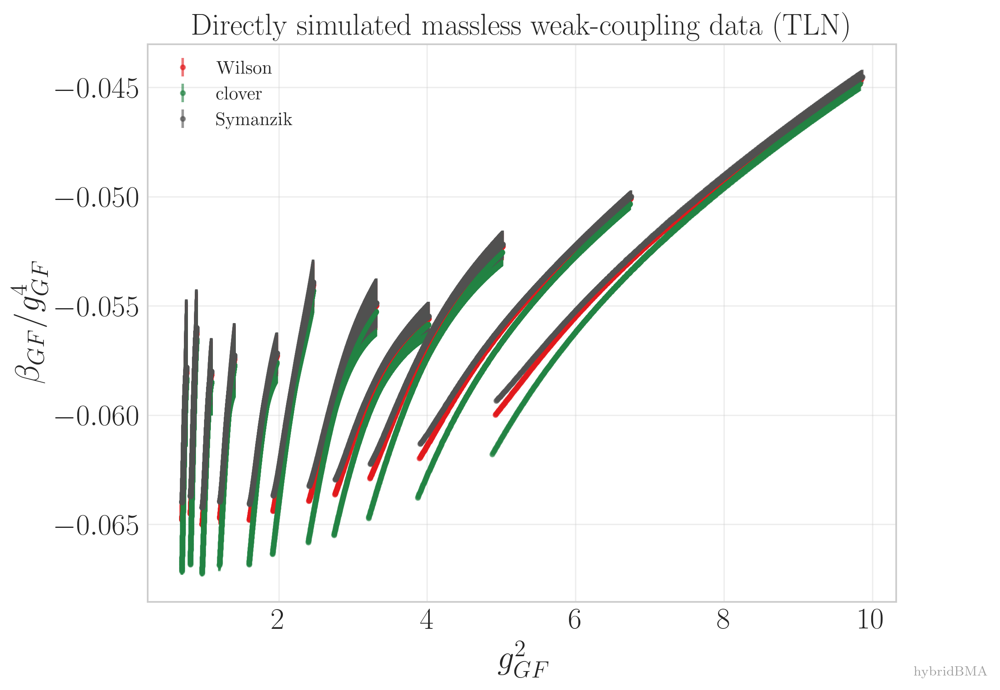

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for operator in OBSERVABLES:
    first = True
    for coupling in sorted(bf.avg_data, key=beta_value):
        if coupling not in WEAK_COUPLINGS:
            continue
        massless_volumes = [
            volume for volume in bf.avg_data[coupling]
            if '0p00' in bf.avg_data[coupling][volume]
        ]
        if not massless_volumes:
            continue
        volume = max(massless_volumes, key=volume_value)
        _, g2 = bf.processed_series(coupling, volume, '0p00', FLOW, operator, 'g2')
        _, beta = bf.processed_series(coupling, volume, '0p00', FLOW, operator, 'beta')
        ratio = np.asarray([b / x**2 for x, b in zip(g2, beta)], dtype=object)
        ax.errorbar(gv.mean(g2), gv.mean(ratio), yerr=gv.sdev(ratio), fmt='o', ms=2.5,
                    alpha=.6, color=OP_COLORS[operator],
                    label=OP_LABELS[operator] if first else None)
        first = False
ax.set(xlabel=r'$g^2_{GF}$', ylabel=r'$\beta_{GF}/g_{GF}^4$', title='Directly simulated massless weak-coupling data (TLN)')
ax.legend(frameon=False)
base = OUTPUT_ROOT / f'processed_largest_volume_{ANALYSIS_ID}'
add_fit_footer(fig)
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)

## Stage 2 — chiral extrapolation

This stage is completed and inspected before the infinite-volume extrapolation.


In [ ]:
CHIRAL_FIT_WINDOW = FIT_TIME_WINDOW
print('chiral flow-time range:', CHIRAL_FIT_WINDOW)

progress_start('chiral extrapolation')
bf.ch_xtrp(
    mnt=CHIRAL_FIT_WINDOW[0],
    mxt=CHIRAL_FIT_WINDOW[1],
    v=config.verbosity,
)
progress_done('chiral extrapolation')
print(bf.stage_summary('chiral'))

chiral flow-time range: (5.0, 6.0)
[START] chiral extrapolation
Chiral extrapolation
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


100%|██████████████████████████████████████████████████████████| 606/606 [00:00<00:00, 1614.07it/s]


Finished beta_b = 7.00, L^{Nd-1}xT = 20x20x20x40 in 0.41 secs


100%|██████████████████████████████████████████████████████████| 606/606 [00:00<00:00, 1657.92it/s]


Finished beta_b = 7.00, L^{Nd-1}xT = 24x24x24x48 in 0.37 secs


...

Finished beta_b = 7.50, L^{Nd-1}xT = 20x20x20x40 in 0.37 secs


100%|██████████████████████████████████████████████████████████| 606/606 [00:00<00:00, 2020.84it/s]


Finished beta_b = 7.50, L^{Nd-1}xT = 24x24x24x48 in 0.3 secs


100%|██████████████████████████████████████████████████████████| 606/606 [00:00<00:00, 2566.06it/s]

Finished beta_b = 7.50, L^{Nd-1}xT = 32x32x32x64 in 0.24 secs
[DONE] chiral extrapolation (0.1 min)
{'stage': 'chiral', 'n_fits': 7272, 'mean_chi2_per_dof': 0.6675955716478902, 'mean_pvalue': 0.5409631491957807}


## Chiral extrapolation diagnostics

For each strong-coupling ensemble, the existing chiral stage fits $g_{\mathrm{GF}}^2$ and $\beta_{\mathrm{GF}}$ separately at fixed $(\beta_b,L/a,t/a^2)$ with the linear form

$$
X(m)=X(0)+k_m m,\qquad X\in\{g_{\mathrm{GF}}^2,\beta_{\mathrm{GF}}\}.
$$

The three simulated masses are used without coefficient priors. The fitted intercept $X(0)$ is inserted as the `0p00` datum before the infinite-volume and interpolation stages. The plots below show the input masses, fitted curves, and massless intercepts for representative flow times; the CSV records every chiral fit. The configured $\beta_b=7.125$ ensembles are picked up automatically when their files are added.


active couplings: ('7p00', '7p125', '7p25', '7p50', '8p00', '8p50', '9p00', '9p50', '10p0', '11p0', '12p0', '14p0', '16p0', '18p0', '20p0')
configured strong couplings without usable data: none


,coupling,beta_b,volume,finite_masses,massless_limit_available,status
0,7p00,7.000,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready
1,7p00,7.000,l24l24l24t48,"0p001, 0p0025, 0p005",True,ready
2,7p00,7.000,l32l32l32t64,"0p001, 0p0025, 0p005",True,ready
3,7p125,7.125,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready
4,7p125,7.125,l24l24l24t48,"0p001, 0p0025, 0p005",True,ready
5,7p125,7.125,l32l32l32t64,"0p001, 0p0025, 0p005",True,ready
6,7p25,7.250,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready
7,7p25,7.250,l24l24l24t48,"0p001, 0p0025, 0p005",True,ready
8,7p25,7.250,l32l32l32t64,"0p001, 0p0025, 0p005",True,ready
9,7p50,7.500,l20l20l20t40,"0p001, 0p0025, 0p005",True,ready


,coupling,beta_b,volume,quantity,operator,flow_time,intercept_mean,intercept_sdev,chi2,dof,p_value
0,7p00,7.0,l20l20l20t40,g2,p,5.00,18.446960,0.146630,0.480962,1,0.487987
1,7p00,7.0,l20l20l20t40,g2,p,5.01,18.469522,0.147143,0.481443,1,0.487769
2,7p00,7.0,l20l20l20t40,g2,p,5.02,18.492078,0.147658,0.481920,1,0.487554
3,7p00,7.0,l20l20l20t40,g2,p,5.03,18.514627,0.148174,0.482393,1,0.487340
4,7p00,7.0,l20l20l20t40,g2,p,5.04,18.537170,0.148690,0.482862,1,0.487129
...,...,...,...,...,...,...,...,...,...,...,...
7267,7p50,7.5,l32l32l32t64,beta,s,5.96,-6.297567,0.126754,4.290738,1,0.038321
7268,7p50,7.5,l32l32l32t64,beta,s,5.97,-6.305897,0.127074,4.297575,1,0.038167
7269,7p50,7.5,l32l32l32t64,beta,s,5.98,-6.314230,0.127394,4.304400,1,0.038014
7270,7p50,7.5,l32l32l32t64,beta,s,5.99,-6.322560,0.127714,4.311211,1,0.037862


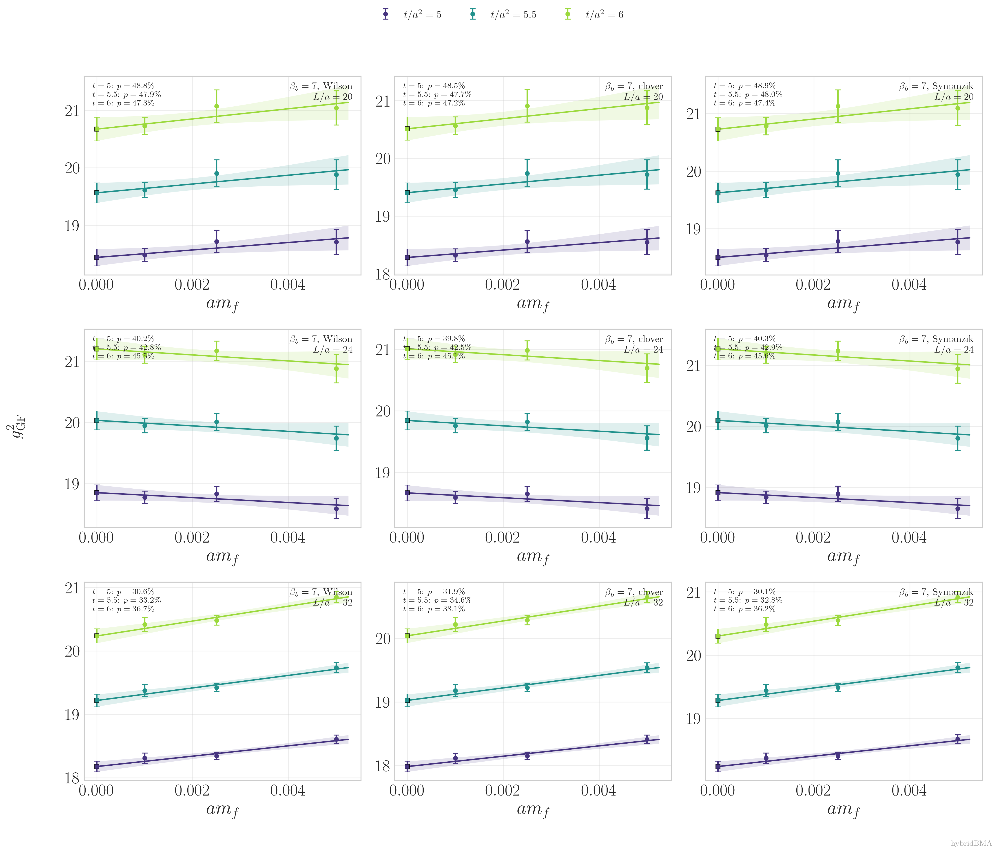

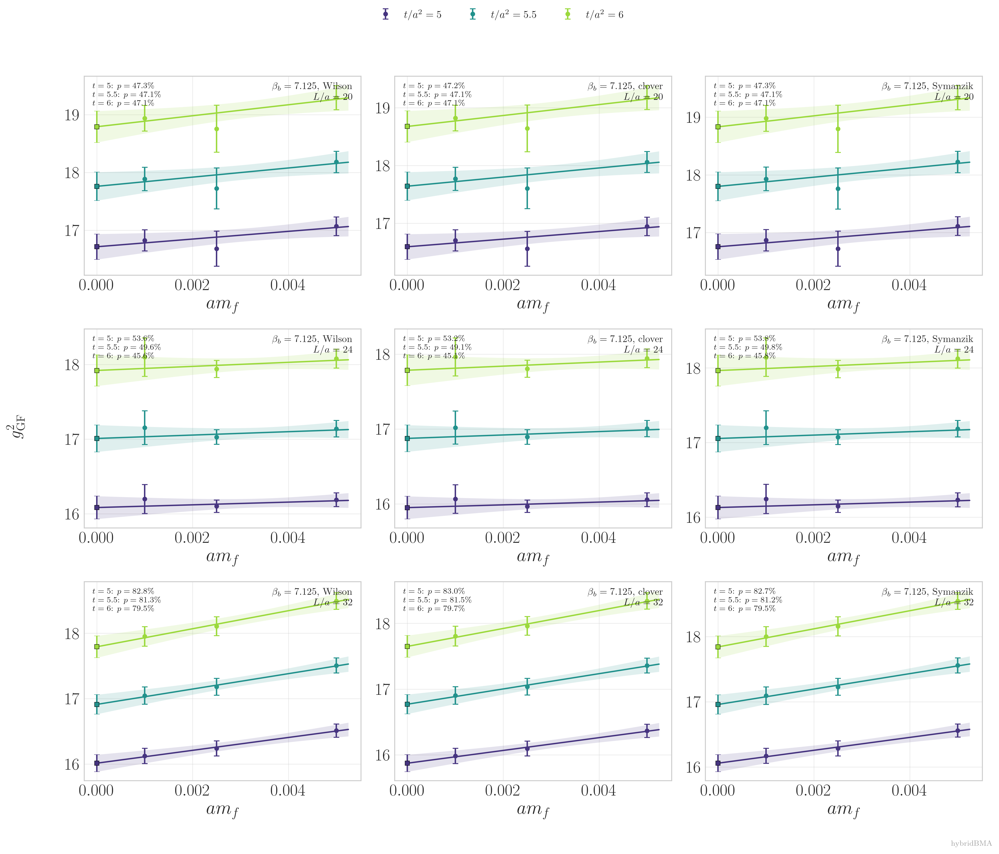

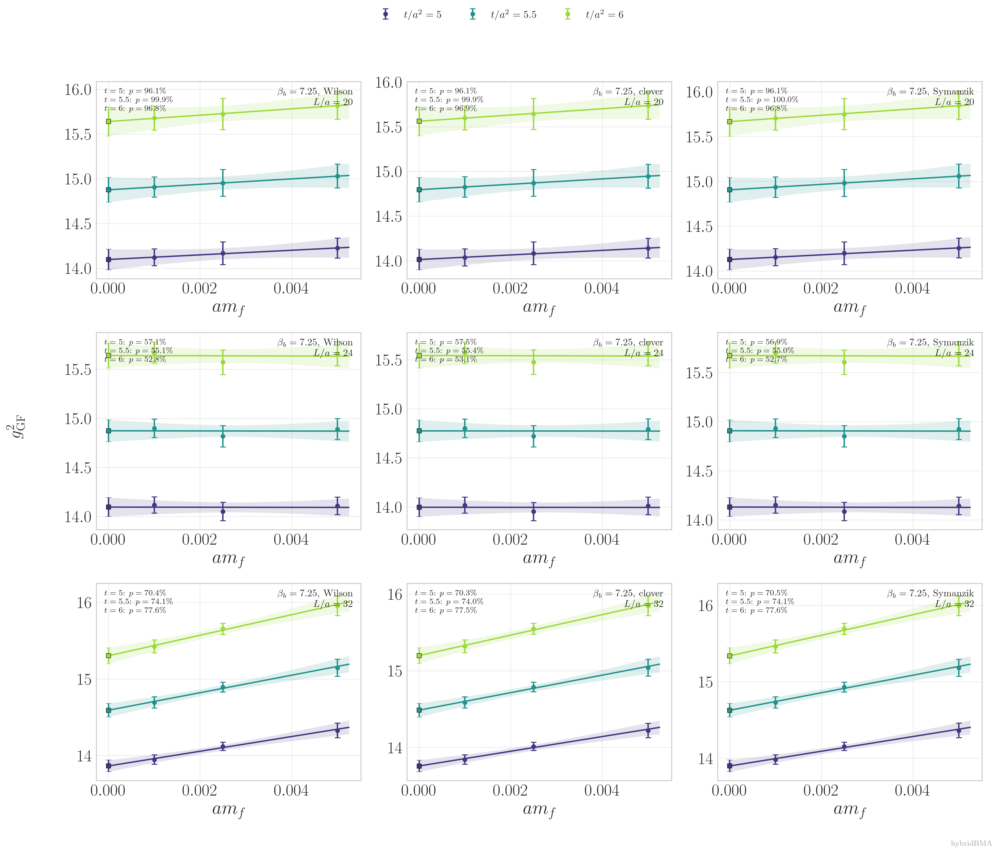

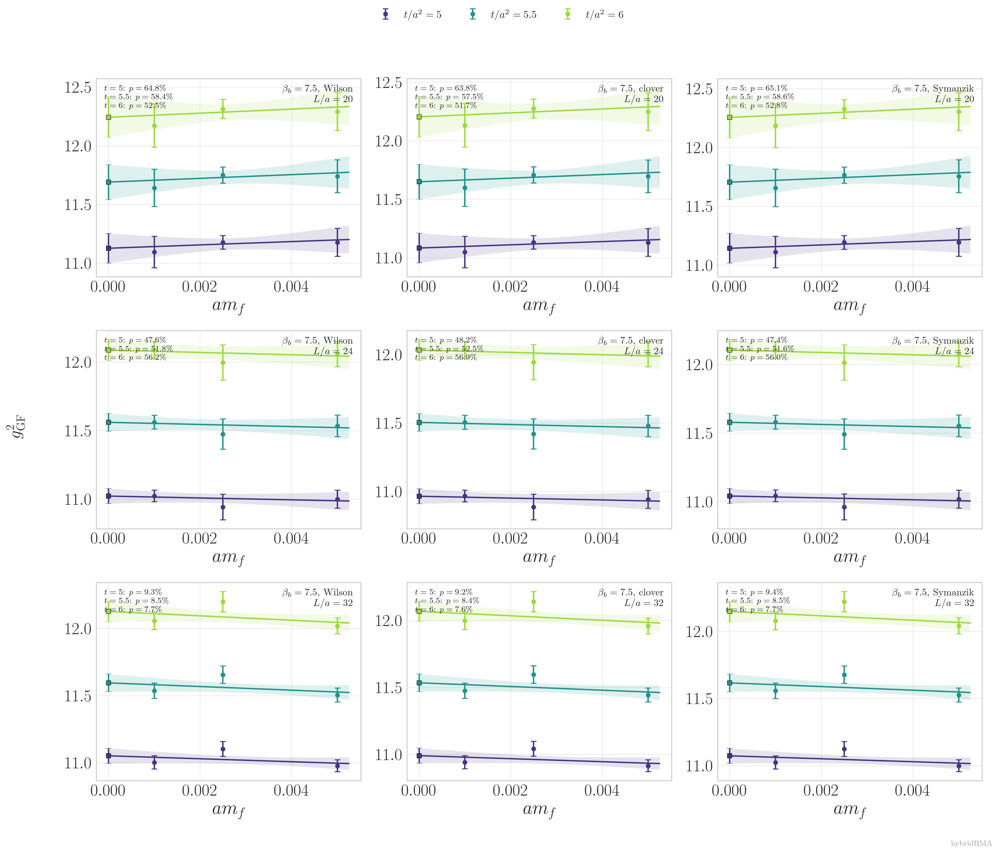

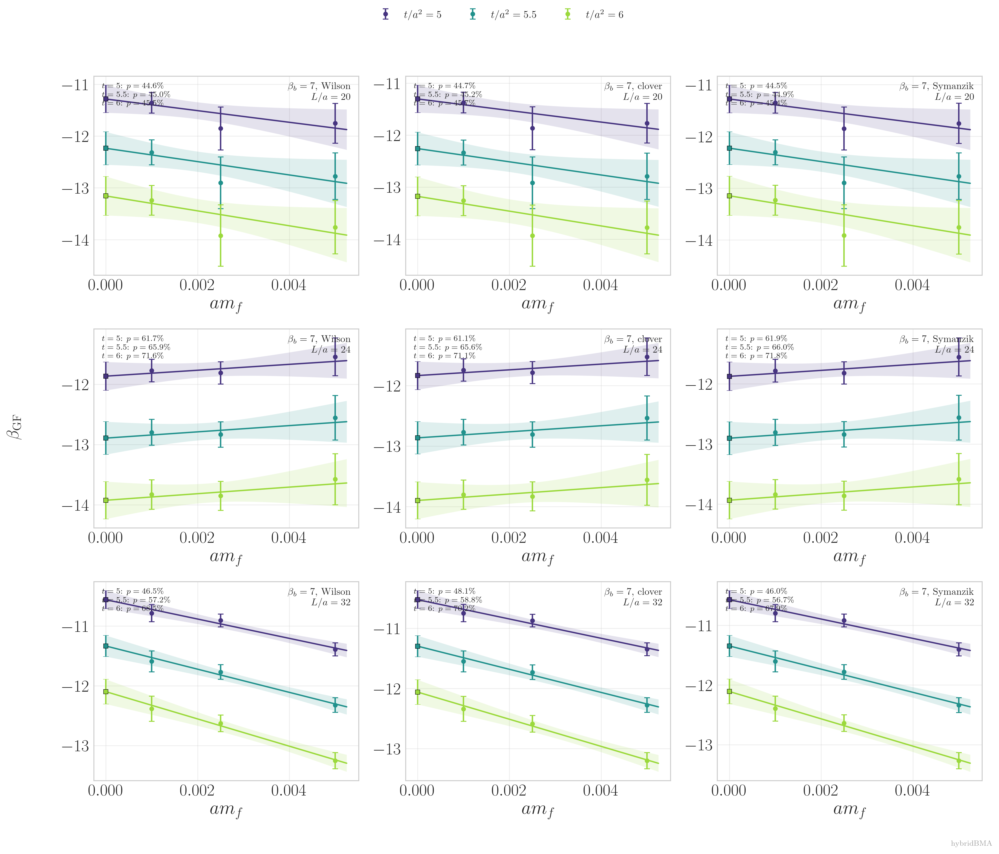

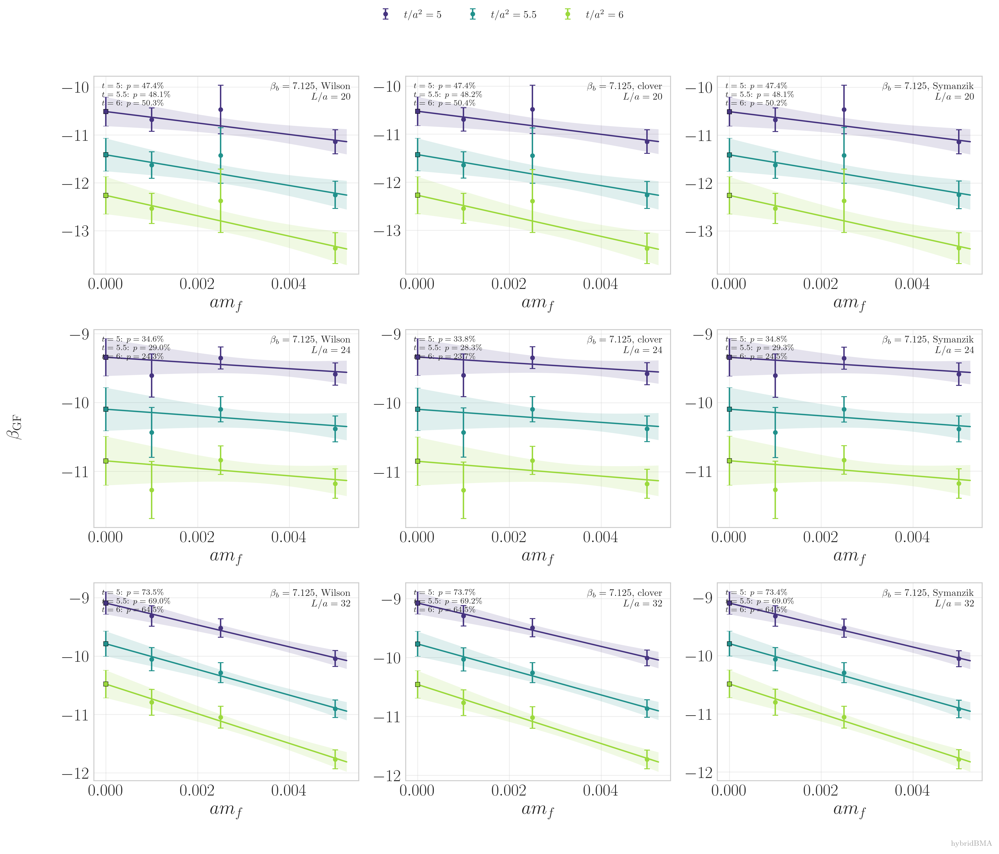

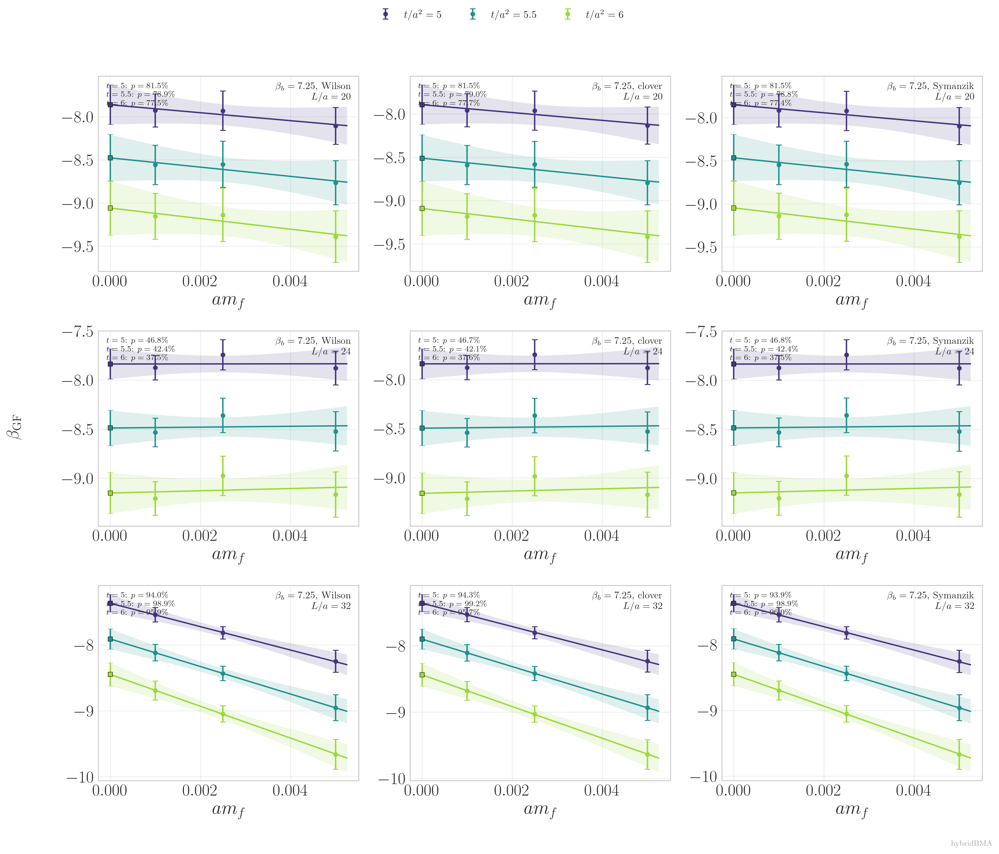

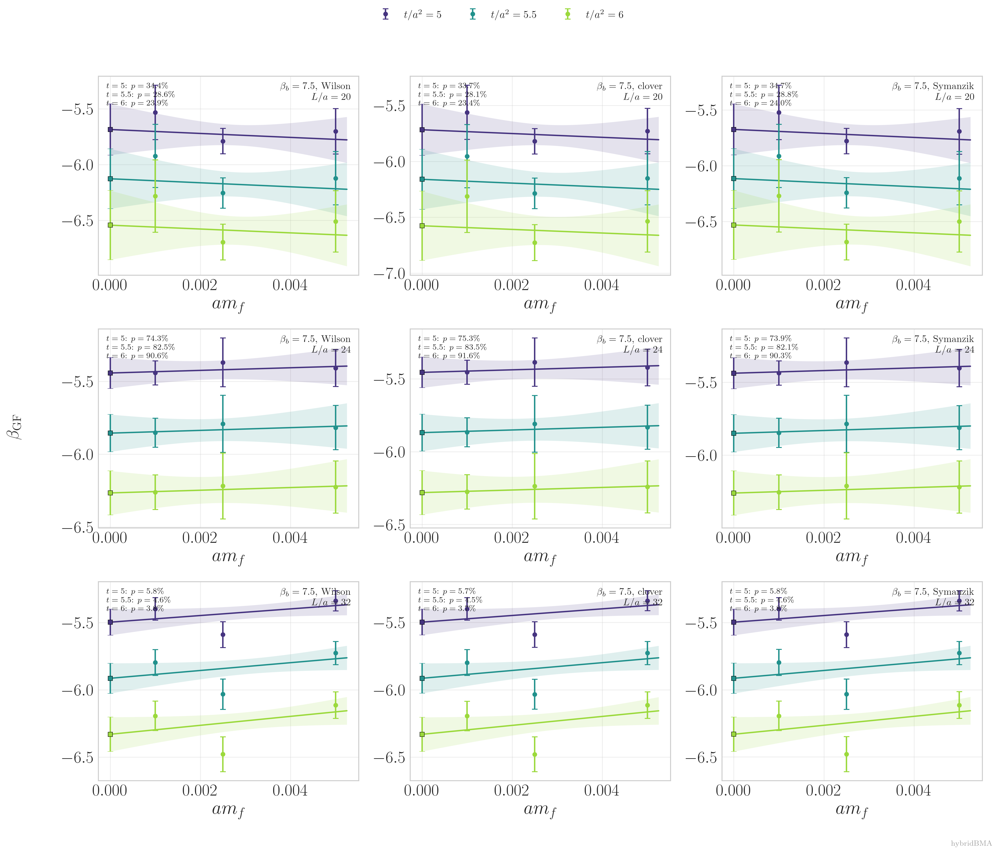

In [ ]:
ACTIVE_COUPLINGS = tuple(sorted(bf.avg_data, key=beta_value))
ACTIVE_STRONG_COUPLINGS = tuple(
    coupling for coupling in STRONG_COUPLINGS if coupling in bf.avg_data
)
MISSING_STRONG_COUPLINGS = tuple(
    coupling for coupling in STRONG_COUPLINGS if coupling not in bf.avg_data
)
print('active couplings:', ACTIVE_COUPLINGS)
print('configured strong couplings without usable data:', MISSING_STRONG_COUPLINGS or 'none')

inventory_rows = []
for coupling in STRONG_COUPLINGS:
    if coupling not in bf.avg_data:
        inventory_rows.append({
            'coupling': coupling,
            'beta_b': beta_value(coupling),
            'volume': 'all configured volumes',
            'finite_masses': '',
            'massless_limit_available': False,
            'status': 'awaiting files',
        })
        continue
    for volume in VOLUMES[coupling]:
        volume_data = bf.avg_data[coupling].get(volume, {})
        finite_masses = sorted(
            (mass for mass in volume_data if mass != '0p00'),
            key=lambda mass: float(mass.replace('p', '.')),
        )
        inventory_rows.append({
            'coupling': coupling,
            'beta_b': beta_value(coupling),
            'volume': volume,
            'finite_masses': ', '.join(finite_masses),
            'massless_limit_available': '0p00' in volume_data,
            'status': (
                'ready'
                if tuple(finite_masses) == EXPECTED_CHIRAL_MASSES
                else 'incomplete mass set'
            ),
        })

chiral_inventory = pd.DataFrame(inventory_rows)
chiral_inventory.to_csv(OUTPUT_ROOT / 'chiral_ensemble_inventory.csv', index=False)
display(chiral_inventory)

chiral_quality_rows = []
for coupling in ACTIVE_STRONG_COUPLINGS:
    for volume in VOLUMES[coupling]:
        if volume not in bf.ch_fits.get(coupling, {}):
            continue
        for quantity in ('g2', 'beta'):
            for operator in OBSERVABLES:
                fits = bf.ch_fits[coupling][volume][quantity][FLOW][operator]
                qualities = bf.ch_qof[coupling][volume][quantity][FLOW][operator]
                for time, params in fits.items():
                    qof = qualities[time]
                    intercept = bf.chiral.model.evaluate(0.0, params)
                    chiral_quality_rows.append({
                        'coupling': coupling,
                        'beta_b': beta_value(coupling),
                        'volume': volume,
                        'quantity': quantity,
                        'operator': operator,
                        'flow_time': float(time),
                        'intercept_mean': float(gv.mean(intercept)),
                        'intercept_sdev': float(gv.sdev(intercept)),
                        'chi2': float(qof['chi2']),
                        'dof': int(qof['dof']),
                        'p_value': float(qof['p-value']),
                    })

chiral_fit_quality = pd.DataFrame(chiral_quality_rows)
chiral_fit_quality.to_csv(
    OUTPUT_ROOT / 'chiral_fit_quality_summary.csv', index=False
)
display(chiral_fit_quality)

CHIRAL_PLOT_TIMES = (5.0, 5.5, 6.0)
CHIRAL_TIME_COLORS = dict(zip(
    CHIRAL_PLOT_TIMES,
    plt.cm.viridis(np.linspace(0.15, 0.85, len(CHIRAL_PLOT_TIMES))),
))

def plot_chiral_extrapolations(quantity):
    ylabel = (
        r'$g^2_{\mathrm{GF}}$'
        if quantity == 'g2'
        else r'$\beta_{\mathrm{GF}}$'
    )
    for coupling in ACTIVE_STRONG_COUPLINGS:
        volumes = [
            volume for volume in VOLUMES[coupling]
            if volume in bf.ch_fits.get(coupling, {})
            and any(
                bf.ch_fits[coupling][volume]['g2'][FLOW][operator]
                for operator in OBSERVABLES
            )
        ]
        if not volumes:
            continue
        fig, axes = plt.subplots(
            len(volumes), len(OBSERVABLES),
            figsize=(15, 4.2 * len(volumes)),
            squeeze=False,
        )
        for row, volume in enumerate(volumes):
            for column, operator in enumerate(OBSERVABLES):
                ax = axes[row, column]
                available = sorted(
                    bf.ch_fits[coupling][volume][quantity][FLOW][operator],
                    key=float,
                )
                selected = []
                selected_times = set()
                for target in CHIRAL_PLOT_TIMES:
                    if not available:
                        continue
                    time = min(available, key=lambda value: abs(float(value) - target))
                    if time not in selected_times:
                        selected.append((target, time))
                        selected_times.add(time)

                pvalue_lines = []
                for target, time in selected:
                    data = bf.chiral.fetch(
                        'inputs', (coupling, volume, quantity, FLOW, operator, time)
                    )
                    params = bf.chiral.fetch(
                        'fits', (coupling, volume, quantity, FLOW, operator, time)
                    )
                    qof = bf.chiral.fetch(
                        'quality', (coupling, volume, quantity, FLOW, operator, time)
                    )
                    masses = np.asarray(data.x, dtype=float)
                    values = np.asarray(data.y, dtype=object)
                    mass_grid = np.linspace(0.0, 1.05 * masses.max(), 160)
                    curve = np.asarray([
                        bf.chiral.model.evaluate(mass, params)
                        for mass in mass_grid
                    ], dtype=object)
                    intercept = bf.chiral.model.evaluate(0.0, params)
                    color = CHIRAL_TIME_COLORS[target]
                    label = rf'$t/a^2={float(time):g}$'
                    ax.errorbar(
                        masses, gv.mean(values), yerr=gv.sdev(values),
                        fmt='o', ms=4, capsize=3, color=color, label=label,
                    )
                    ax.plot(mass_grid, gv.mean(curve), color=color, lw=1.5)
                    ax.fill_between(
                        mass_grid,
                        gv.mean(curve) - gv.sdev(curve),
                        gv.mean(curve) + gv.sdev(curve),
                        color=color, alpha=.14, linewidth=0,
                    )
                    ax.errorbar(
                        [0.0], [gv.mean(intercept)], yerr=[gv.sdev(intercept)],
                        fmt='s', ms=5, capsize=3, color=color,
                        markeredgecolor='black', markeredgewidth=.4,
                    )
                    pvalue_lines.append(
                        rf'$t={float(time):g}$: $p={100.0 * float(qof["p-value"]):.1f}\%$'
                    )

                spatial_extent = int(volume.split('l')[1])
                ax.set_xlabel(r'$am_f$')
                ax.text(
                    .97, .97,
                    rf'$\beta_b={beta_value(coupling):g}$, ' + OP_LABELS[operator]
                    + '\n' + rf'$L/a={spatial_extent}$',
                    transform=ax.transAxes, ha='right', va='top', fontsize=10.5,
                )
                ax.text(
                    .03, .97, '\n'.join(pvalue_lines), transform=ax.transAxes,
                    ha='left', va='top', fontsize=8.5,
                )

        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=max(1, len(handles)), loc='upper center', frameon=False)
        fig.supylabel(ylabel)
        fig.tight_layout(rect=(.03, .02, 1, .93))
        base = OUTPUT_ROOT / f'chiral_extrapolation_{quantity}_{coupling}_{ANALYSIS_ID}'
        add_fit_footer(fig)
        fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
        fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
        plt.show()
        plt.close(fig)

plot_chiral_extrapolations('g2')
plot_chiral_extrapolations('beta')

## Stage 3 — infinite-volume extrapolation

Only after the chiral fits and their plots have been inspected is the massless data extrapolated to infinite volume.

In [ ]:
progress_start('infinite-volume extrapolation')
bf.run_infinite_volume(config)
progress_done('infinite-volume extrapolation')
print(bf.stage_summary('infinite_volume'))
IV_COUPLINGS = tuple(
    coupling for coupling in ACTIVE_COUPLINGS
    if coupling in bf.iv_fits
    and any(bf.iv_fits[coupling]['g2'][FLOW][operator]
            for operator in OBSERVABLES)
)
print('couplings with infinite-volume fits:', IV_COUPLINGS)

[START] infinite-volume extrapolation
Infinite volume extrapolation
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~


100%|███████████████████████████████████████████████████████████| 606/606 [00:01<00:00, 372.45it/s]


Finished beta_b = 7.00 in 1.63 secs


100%|███████████████████████████████████████████████████████████| 606/606 [00:01<00:00, 373.97it/s]


Finished beta_b = 7.125 in 1.62 secs


...

Finished beta_b = 16.0 in 1.32 secs


100%|███████████████████████████████████████████████████████████| 606/606 [00:01<00:00, 456.89it/s]


Finished beta_b = 18.0 in 1.33 secs


100%|███████████████████████████████████████████████████████████| 606/606 [00:01<00:00, 455.11it/s]


Finished beta_b = 20.0 in 1.33 secs
[DONE] infinite-volume extrapolation (0.4 min)
{'stage': 'infinite_volume', 'n_fits': 9090, 'mean_chi2_per_dof': 2.4471918940700568, 'mean_pvalue': 0.37568654810150076}
couplings with infinite-volume fits: ('7p00', '7p125', '7p25', '7p50', '8p00', '8p50', '9p00', '9p50', '10p0', '11p0', '12p0', '14p0', '16p0', '18p0', '20p0')


## Infinite-volume diagnostics

These plots inspect the completed Stage 3 outputs before interpolation begins.

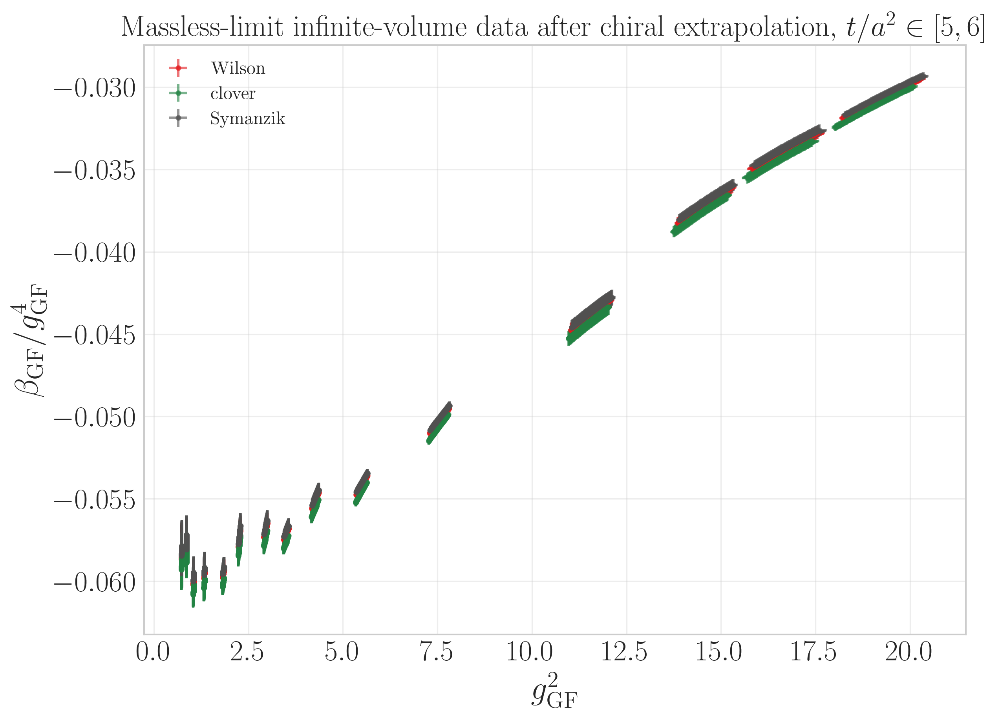

/Users/yaman/jupyter-env/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


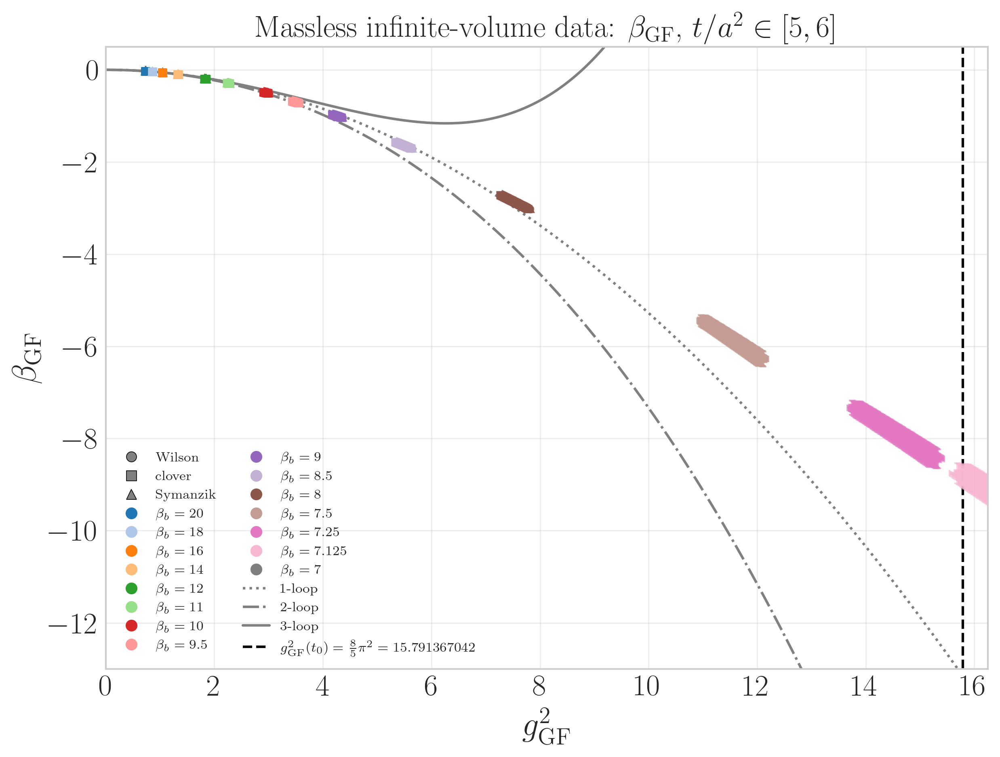

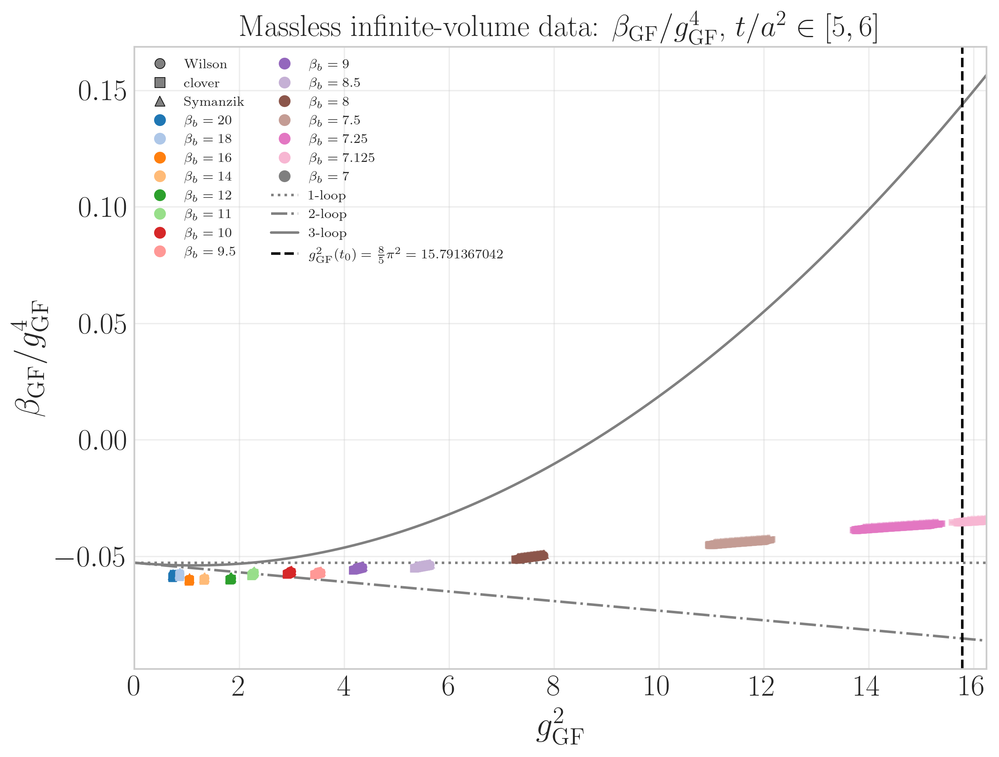

In [ ]:
# Confirm that the massless data used downstream are mutually consistent
# after the infinite-volume extrapolation. Keep each flow-time window
# separate so the plotted sample matches that window.
def plot_processed_massless_infinite_volume(window):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for operator in OBSERVABLES:
        first = True
        for coupling in sorted(IV_COUPLINGS, key=beta_value, reverse=True):
            g2_fits = bf.iv_fits[coupling]['g2'][FLOW][operator]
            beta_fits = bf.iv_fits[coupling]['beta'][FLOW][operator]
            common_times = [
                flow_time
                for flow_time in sorted(set(g2_fits) & set(beta_fits), key=float)
                if window[0] <= float(flow_time) <= window[1]
            ]
            for flow_time in common_times:
                g2_iv = bf.infinite_volume.model.evaluate(
                    0.0, g2_fits[flow_time]
                )
                beta_iv = bf.infinite_volume.model.evaluate(
                    0.0, beta_fits[flow_time]
                )
                ratio_iv = beta_iv / g2_iv**2
                ax.errorbar(
                    gv.mean(g2_iv), gv.mean(ratio_iv),
                    xerr=gv.sdev(g2_iv), yerr=gv.sdev(ratio_iv),
                    fmt='o', ms=2.5, alpha=.6,
                    color=OP_COLORS[operator],
                    label=OP_LABELS[operator] if first else None,
                )
                first = False
    ax.set(
        xlabel=r'$g^2_{\mathrm{GF}}$',
        ylabel=r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$',
        title=(
            'Massless-limit infinite-volume data after chiral extrapolation, '
            rf'$t/a^2\in[{window[0]:g},{window[1]:g}]$'
        ),
    )
    ax.legend(frameon=False)
    plt.show()
    save_figure(
        fig, window,
        f'processed_massless_limit_infinite_volume_{ANALYSIS_ID}',
    )


for window in WINDOWS:
    plot_processed_massless_infinite_volume(window)


# Raw massless infinite-volume intercepts before interpolation.
ordered_iv_couplings = tuple(
    sorted(IV_COUPLINGS, key=beta_value, reverse=True)
)
qualitative_colors = tuple(plt.get_cmap('tab20').colors)
beta_colors = {
    coupling: qualitative_colors[index % len(qualitative_colors)]
    for index, coupling in enumerate(ordered_iv_couplings)
}
operator_markers = {'p': 'o', 'c': 's', 's': '^'}
plot_xmax = max(G2_GRID[1], G2_T0) + 0.25
xp_pt = np.linspace(0.001, plot_xmax, 900)
pt_styles = (
    (1, ':', '1-loop'),
    (2, '-.', '2-loop'),
    (3, '-', '3-loop'),
)
operator_handles = [
    Line2D(
        [0], [0], marker=operator_markers[operator], linestyle='none',
        color='gray', markeredgecolor='black', markeredgewidth=.4,
        label=OP_LABELS[operator],
    )
    for operator in OBSERVABLES
]
coupling_handles = [
    Line2D(
        [0], [0], marker='o', linestyle='none',
        color=beta_colors[coupling], markersize=6,
        label=rf'$\beta_b={beta_value(coupling):g}$',
    )
    for coupling in ordered_iv_couplings
]
pt_handles = [
    Line2D(
        [0], [0], color='gray', linestyle=linestyle,
        lw=1.5, label=label,
    )
    for _, linestyle, label in pt_styles
]
t0_handle = Line2D(
    [0], [0], color='black', linestyle='--', lw=1.5,
    label=rf'$g^2_{{\mathrm{{GF}}}}(t_0)=\frac{{8}}{{5}}\pi^2={G2_T0:.9f}$',
)


def plot_massless_infinite_volume(window, divide_by_g4=False):
    """Plot massless IV data using only flow times inside one window."""
    fig, ax = plt.subplots(figsize=(8.5, 6.5))

    for coupling in ordered_iv_couplings:
        color = beta_colors[coupling]
        for operator in OBSERVABLES:
            g2_fits = bf.iv_fits[coupling]['g2'][FLOW][operator]
            beta_fits = bf.iv_fits[coupling]['beta'][FLOW][operator]
            common_times = [
                flow_time
                for flow_time in sorted(set(g2_fits) & set(beta_fits), key=float)
                if window[0] <= float(flow_time) <= window[1]
            ]
            for flow_time in common_times:
                g2_iv = bf.infinite_volume.model.evaluate(
                    0.0, g2_fits[flow_time]
                )
                beta_iv = bf.infinite_volume.model.evaluate(
                    0.0, beta_fits[flow_time]
                )
                value = beta_iv / g2_iv**2 if divide_by_g4 else beta_iv
                ax.errorbar(
                    gv.mean(g2_iv), gv.mean(value),
                    xerr=gv.sdev(g2_iv), yerr=gv.sdev(value),
                    fmt=operator_markers[operator], ms=3.8, capsize=2,
                    color=color, alpha=.58, linestyle='none',
                )

    for loops, linestyle, _ in pt_styles:
        ratio_pt = pt_over_g4(xp_pt, loops)
        perturbative_value = ratio_pt if divide_by_g4 else xp_pt**2 * ratio_pt
        ax.plot(
            xp_pt, perturbative_value,
            color='gray', ls=linestyle, lw=1.5, zorder=1,
        )

    quantity = (
        r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$'
        if divide_by_g4 else r'$\beta_{\mathrm{GF}}$'
    )
    ax.set(
        xlim=(0.0, plot_xmax),
        xlabel=r'$g^2_{\mathrm{GF}}$',
        ylabel=quantity,
        title=(
            rf'Massless infinite-volume data: {quantity}, '
            rf'$t/a^2\in[{window[0]:g},{window[1]:g}]$'
        ),
    )
    if not divide_by_g4:
        ax.set_ylim(-13.0, 0.5)
    ax.axvline(G2_T0, color='black', linestyle='--', lw=1.5, zorder=1)
    ax.legend(
        handles=(
            operator_handles + coupling_handles + pt_handles + [t0_handle]
        ),
        frameon=False, fontsize=8, ncol=2,
    )
    fig.tight_layout()
    name = (
        f'massless_infinite_volume_beta_over_g4_vs_g2_{ANALYSIS_ID}'
        if divide_by_g4
        else f'massless_infinite_volume_beta_vs_g2_{ANALYSIS_ID}'
    )
    plt.show()
    save_figure(fig, window, name)


for window in WINDOWS:
    plot_massless_infinite_volume(window, divide_by_g4=False)
    plot_massless_infinite_volume(window, divide_by_g4=True)


## Plot 2 — infinite-volume extrapolations for every bare coupling

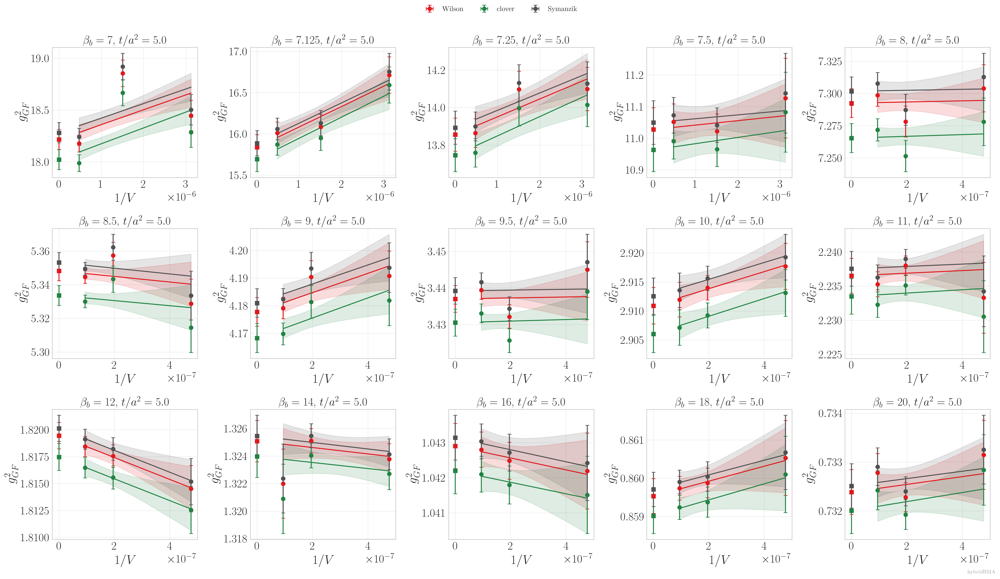

In [ ]:
fig, axes = coupling_figure(IV_COUPLINGS)
for ax, coupling in zip(axes.ravel(), IV_COUPLINGS):
    times = sorted(bf.iv_fits[coupling]['g2'][FLOW][OBSERVABLES[0]], key=float)
    time = min(times, key=lambda t: abs(float(t) - CENTRAL_WINDOW[0]))
    for operator in OBSERVABLES:
        xfit, yfit, data = bf.infinite_volume_curve(coupling, FLOW, operator, time, x='g2')
        intercept = bf.infinite_volume.model.evaluate(0.0, bf.iv_fits[coupling]['g2'][FLOW][operator][time])
        color = OP_COLORS[operator]
        ax.errorbar(gv.mean(data.x), gv.mean(data.y), xerr=gv.sdev(data.x), yerr=gv.sdev(data.y),
                    fmt='o', capsize=3, color=color, label=OP_LABELS[operator])
        ax.plot(xfit, gv.mean(yfit), color=color)
        ax.fill_between(xfit, gv.mean(yfit)-gv.sdev(yfit), gv.mean(yfit)+gv.sdev(yfit), color=color, alpha=.15)
        ax.errorbar([0], [gv.mean(intercept)], yerr=[gv.sdev(intercept)], fmt='s', capsize=3, color=color)
    ax.set(title=rf'$\beta_b={beta_value(coupling):g}$, $t/a^2={time}$', xlabel=r'$1/V$', ylabel=r'$g^2_{GF}$')
for ax in axes.ravel()[len(IV_COUPLINGS):]:
    ax.set_visible(False)

handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc='upper center', frameon=False)
fig.tight_layout(rect=(0, 0, 1, .96))
base = OUTPUT_ROOT / f'infinite_volume_all_beta_{ANALYSIS_ID}'
add_fit_footer(fig)
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(base.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)

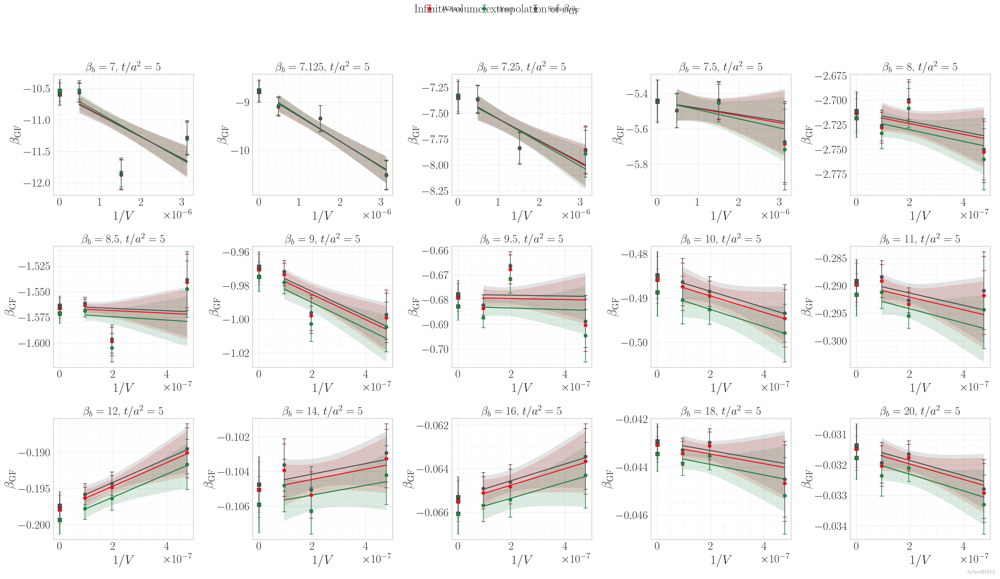

In [ ]:
# Infinite-volume extrapolation: beta_GF versus 1/V

fig, axes = coupling_figure(IV_COUPLINGS)

for ax, coupling in zip(axes.ravel(), IV_COUPLINGS):
  available_times = sorted(
      bf.iv_fits[coupling]['beta'][FLOW][OBSERVABLES[0]],
      key=float,
  )
  time = min(
      available_times,
      key=lambda value: abs(float(value) - CENTRAL_WINDOW[0]),
  )

  for operator in OBSERVABLES:
      x_fit, beta_fit, beta_data = bf.infinite_volume_curve(
          coupling,
          FLOW,
          operator,
          time,
          x='beta',
      )

      x_fit = np.asarray(x_fit, dtype=float)
      beta_fit = np.asarray(beta_fit, dtype=object)
      beta_data_y = np.asarray(beta_data.y, dtype=object)

      color = OP_COLORS[operator]

      # Finite-volume beta_GF data.
      ax.errorbar(
          beta_data.x,
          gv.mean(beta_data_y),
          yerr=gv.sdev(beta_data_y),
          fmt='o',
          ms=5,
          capsize=3,
          elinewidth=1.0,
          color=color,
          label=OP_LABELS[operator],
          zorder=3,
      )

      # Infinite-volume extrapolation curve.
      ax.plot(
          x_fit,
          gv.mean(beta_fit),
          color=color,
          lw=1.6,
          zorder=2,
      )

      ax.fill_between(
          x_fit,
          gv.mean(beta_fit) - gv.sdev(beta_fit),
          gv.mean(beta_fit) + gv.sdev(beta_fit),
          color=color,
          alpha=0.16,
          linewidth=0,
          zorder=1,
      )

      # Infinite-volume intercept at 1/V = 0.
      beta_params = bf.iv_fits[coupling]['beta'][FLOW][operator][time]
      beta_infinite = bf.infinite_volume.model.evaluate(
          0.0,
          beta_params,
      )

      ax.errorbar(
          [0.0],
          [gv.mean(beta_infinite)],
          yerr=[gv.sdev(beta_infinite)],
          fmt='s',
          ms=6,
          capsize=3,
          color=color,
          markeredgecolor='black',
          markeredgewidth=0.4,
          zorder=4,
      )

  ax.set_title(
      rf'$\beta_b={beta_value(coupling):g}$, '
      rf'$t/a^2={float(time):g}$'
  )
  ax.set_xlabel(r'$1/V$')
  ax.set_ylabel(r'$\beta_{\mathrm{GF}}$')
  ax.minorticks_on()
  ax.grid(which='major', linestyle='-', alpha=0.35)
  ax.grid(which='minor', linestyle='--', alpha=0.20)

for ax in axes.ravel()[len(IV_COUPLINGS):]:
    ax.set_visible(False)

# Shared legend without duplicate entries.
handles, labels = axes.ravel()[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))

fig.legend(
  unique.values(),
  unique.keys(),
  ncol=len(OBSERVABLES),
  loc='upper center',
  frameon=False,
)

fig.suptitle(
  r'Infinite-volume extrapolation of $\beta_{\mathrm{GF}}$',
  y=0.995,
)

fig.tight_layout(rect=(0, 0, 1, 0.95))

output_base = OUTPUT_ROOT / f'infinite_volume_beta_vs_invV_{ANALYSIS_ID}'
add_fit_footer(fig)
fig.savefig(
  output_base.with_suffix('.png'),
  dpi=300,
  bbox_inches='tight',
)
fig.savefig(
  output_base.with_suffix('.pdf'),
  dpi=300,
  bbox_inches='tight',
)

plt.show()
plt.close(fig)


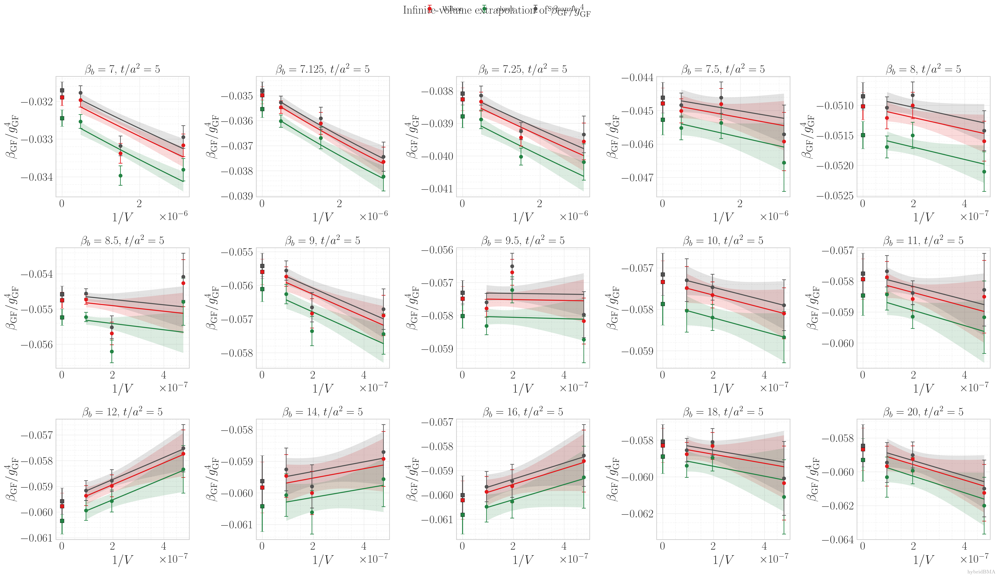

In [ ]:
# Infinite-volume extrapolation:
# beta_GF / g_GF^4 versus 1/V

fig, axes = coupling_figure(IV_COUPLINGS)

for ax, coupling in zip(axes.ravel(), IV_COUPLINGS):
  available_times = sorted(
      bf.iv_fits[coupling]['beta'][FLOW][OBSERVABLES[0]],
      key=float,
  )
  time = min(
      available_times,
      key=lambda value: abs(float(value) - CENTRAL_WINDOW[0]),
  )

  for operator in OBSERVABLES:
      # Retrieve the beta_GF and g_GF^2 data used in the IV fits.
      _, _, beta_data = bf.infinite_volume_curve(
          coupling,
          FLOW,
          operator,
          time,
          x='beta',
      )
      _, _, g2_data = bf.infinite_volume_curve(
          coupling,
          FLOW,
          operator,
          time,
          x='g2',
      )

      # Confirm that beta and g^2 use the same volumes in the same order.
      if beta_data.labels != g2_data.labels:
          raise RuntimeError(
              f'Volume ordering mismatch for {coupling}, '
              f'{operator}, t/a^2={time}'
          )

      inv_volume = np.asarray(beta_data.x, dtype=float)
      beta_values = np.asarray(beta_data.y, dtype=object)
      g2_values = np.asarray(g2_data.y, dtype=object)

      # Since g2_values = g_GF^2, g_GF^4 = g2_values**2.
      ratio_data = beta_values / g2_values**2

      beta_params = bf.iv_fits[coupling]['beta'][FLOW][operator][time]
      g2_params = bf.iv_fits[coupling]['g2'][FLOW][operator][time]

      x_fit = np.linspace(
          float(np.min(inv_volume)),
          float(np.max(inv_volume)),
          300,
      )

      beta_fit = np.asarray(
          [
              bf.infinite_volume.model.evaluate(x, beta_params)
              for x in x_fit
          ],
          dtype=object,
      )
      g2_fit = np.asarray(
          [
              bf.infinite_volume.model.evaluate(x, g2_params)
              for x in x_fit
          ],
          dtype=object,
      )

      ratio_fit = beta_fit / g2_fit**2
      color = OP_COLORS[operator]

      # Finite-volume beta_GF/g_GF^4 data.
      ax.errorbar(
          inv_volume,
          gv.mean(ratio_data),
          yerr=gv.sdev(ratio_data),
          fmt='o',
          ms=5,
          capsize=3,
          elinewidth=1.0,
          color=color,
          label=OP_LABELS[operator],
          zorder=3,
      )

      # Ratio of the fitted beta_GF and g_GF^2 IV curves.
      ax.plot(
          x_fit,
          gv.mean(ratio_fit),
          color=color,
          lw=1.6,
          zorder=2,
      )

      ax.fill_between(
          x_fit,
          gv.mean(ratio_fit) - gv.sdev(ratio_fit),
          gv.mean(ratio_fit) + gv.sdev(ratio_fit),
          color=color,
          alpha=0.16,
          linewidth=0,
          zorder=1,
      )

      # Infinite-volume ratio at 1/V = 0.
      beta_infinite = bf.infinite_volume.model.evaluate(
          0.0,
          beta_params,
      )
      g2_infinite = bf.infinite_volume.model.evaluate(
          0.0,
          g2_params,
      )
      ratio_infinite = beta_infinite / g2_infinite**2

      ax.errorbar(
          [0.0],
          [gv.mean(ratio_infinite)],
          yerr=[gv.sdev(ratio_infinite)],
          fmt='s',
          ms=6,
          capsize=3,
          color=color,
          markeredgecolor='black',
          markeredgewidth=0.4,
          zorder=4,
      )

  ax.set_title(
      rf'$\beta_b={beta_value(coupling):g}$, '
      rf'$t/a^2={float(time):g}$'
  )
  ax.set_xlabel(r'$1/V$')
  ax.set_ylabel(r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$')
  ax.minorticks_on()
  ax.grid(which='major', linestyle='-', alpha=0.35)
  ax.grid(which='minor', linestyle='--', alpha=0.20)

for ax in axes.ravel()[len(IV_COUPLINGS):]:
    ax.set_visible(False)

# Shared legend without duplicate entries.
handles, labels = axes.ravel()[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))

fig.legend(
  unique.values(),
  unique.keys(),
  ncol=len(OBSERVABLES),
  loc='upper center',
  frameon=False,
)

fig.suptitle(
  r'Infinite-volume extrapolation of '
  r'$\beta_{\mathrm{GF}}/g_{\mathrm{GF}}^4$',
  y=0.995,
)

fig.tight_layout(rect=(0, 0, 1, 0.95))

output_base = (
  OUTPUT_ROOT
  / f'infinite_volume_beta_over_g4_vs_invV_{ANALYSIS_ID}'
)

add_fit_footer(fig)
fig.savefig(
  output_base.with_suffix('.png'),
  dpi=300,
  bbox_inches='tight',
)
fig.savefig(
  output_base.with_suffix('.pdf'),
  dpi=300,
  bbox_inches='tight',
)

plt.show()
plt.close(fig)


## Independent weak/strong interpolation and Bayesian model averaging

Each interpolation is fitted independently for one operator and one flow time. Bare couplings $\beta_b=20,\ldots,8$ determine the weak branch; the chirally extrapolated $\beta_b=7.5,7.25,7.125,7$ ensembles determine the strong branch. The existing errors-in-variables likelihood, covariance and local evidence calculation are retained. Cross-region statistical correlations in the data remain; the gap connection adds no pseudo-data or matching penalty.

### Revised weak ansatz: shape-constrained polynomial

The old three-loop multiplicative prefactor forced a zero near $g^2=8.7786$, producing a weak-endpoint turn that no smooth bridge could remove. The default replacements are `monotone` and `monotone_constant`. Write $x=g^2_{\rm GF}$, $L=4\pi$, $u=x/L$, and $b_0=0.0527714498\ldots$ in $\beta(x)=-b_0x^2+\cdots$. With Bernstein basis $B_{k,N}(u)={N\choose k}u^k(1-u)^{N-k}$,

$$
W_N(x)=a_0-2b_0\int_0^x s\left[\sum_{k=0}^N w_k B_{k,N}(s/L)\right]ds,
\qquad w_0=1,\qquad w_k=\exp(q_k)>0.
$$

`monotone` fixes $a_0=0$; `monotone_constant` fits it. Therefore $W_N'(x)<0$ for $0<x\le L$, and $W_N(x)=a_0-b_0x^2+O(x^3)$. No three-loop zero is imposed. The higher perturbative coefficients are not fixed, consistent with the freedom previously supplied by the multiplicative correction. The parameter keys in the coefficient ledger are `logw_0_k` for $q_k$ and, where present, `a0_0_0` for $a_0$. Degree $N=4$ supplies four free slope-shape coefficients; the integrated polynomial has degree six. Increasing $N$ remains a notebook choice.

The defaults are proper independent priors $q_k\sim\mathcal N(0,1.5^2)$ and $a_0\sim\mathcal N(0,0.25^2)$ when free. They are explicit modelling choices for evidence comparison, not a claim that all prior widths are equivalent. At $q_k=0$ the curve is one-loop running. The integral and its derivatives are finite polynomial sums, so fitting introduces no numerical quadrature. The basis scale $L=4\pi$ is fixed; this implementation rejects a matching point outside its monotonicity domain. This construction uses [shape-restricted Bernstein-polynomial regression](https://www.sciencedirect.com/science/article/pii/S0167947312001004), with the one-loop anchor as an adaptation for this analysis.

Monotonicity is a model assumption supported by the displayed finite-time data, not a general theorem about all lattice beta functions. It does not imply that $\beta/x^2$ is monotone. Check both plots, residuals and fit quality after refitting; a model average cannot rescue uniformly inadequate candidates. The original `fit4`/`fit11` families are retained as alternative selections rather than silently redefined.

### Strong ansatz

The strong branch remains the independently parameterized Eq. (7)-style rational form from [arXiv:2303.00704](https://arxiv.org/html/2303.00704v2#S3.SS4):

$$
S_N(x)=-p_0x^2\frac{1+\sum_{i=1}^{N}p_i(x/4\pi)^i}{\prod_{j=1}^{N+1}[1+x/(4\pi\rho_j)]},
\qquad p_0>0,\quad 0<\rho_1<\cdots<\rho_{N+1}.
$$

Orders $[1/2]$ and $[2/3]$ retain generic asymptotically linear behavior. Positive ordered poles restrict the denominator compared with the paper's fully general rational form. Strong-branch priors are unchanged.

**Connection confined to the unmeasured gap.** Let $x_8$ and $x_{7.5}$ be the measured mean couplings at the adjacent ensembles. Set $a=x_8+0.05(x_{7.5}-x_8)$ and $b=x_{7.5}$. The complete selected weak function is retained for every $x\le a$; the strong fit is retained for every $x\ge b$. Thus no smoothing is applied between measured weak points, including $\beta_b=8.5$ and $8$. The 5% extension is an explicit gap-modelling choice, not a new measurement or fit parameter.

Inside $[a,b]$, define $h=b-a$, $s=(x-a)/h$, $y_0=W(a)$, $d_0=W'(a)$, $y_1=S_N(b)$ and $d_1=S_N'(b)$. Use the rational Hermite interpolant

$$
\beta(x)=\frac{y_0(1-s)^3+(r y_0+h d_0)s(1-s)^2+(r y_1-h d_1)s^2(1-s)+y_1s^3}{1+(r-3)s(1-s)}.
$$

For the secant $D=(y_1-y_0)/h\ne0$, choose $r=3+(d_0/D-1)^2+(d_1/D-1)^2$. The denominator is positive and both endpoint values and first derivatives agree exactly. If both endpoint slopes have the sign of $D$, the sufficient monotonicity condition $r\ge(d_0+d_1)/D$ holds. Otherwise a turn cannot be excluded while preserving those slopes: the diagnostic table reports that conflict rather than clipping derivatives. A numerically zero secant uses ordinary Hermite ($r=3$), without a monotonicity claim. $\beta/x^2$ is evaluated from this same curve, so it is also $C^1$ at the positive matching points.

The bridge follows [Delbourgo and Gregory, Eqs. (2.3)--(2.7) and (3.8)](https://bura.brunel.ac.uk/bitstream/2438/2200/1/TR_10_83.pdf); the strong-branch motivation is [Eq. (7) of arXiv:2303.00704](https://arxiv.org/html/2303.00704v2#S3.SS4). These are separate ingredients. Matching is not a constraint in the labelled-data likelihood. The new weak families have distinct model/checkpoint names: old Fit 4/Fit 11 posteriors cannot be reused for them. Matching checkpoints from the same model are reused only when the data, covariance and priors match. Coefficients and their correlations propagate through the bridge with `gvar`; the endpoints remain fixed at measured means, as in the existing analysis. Gap-prescription uncertainty is not automatically included in the statistical band.

**Rerunning:** with the processed `bf` object still in memory, rerun the main configuration cell, then the interpolation cell immediately below and the later plots/continuum cells. New interpolation fits are required, but data processing, chiral and infinite-volume cells do not need rerunning for this change. Keep the analysis ID and output root unchanged. Smoothness does not establish a good fit: inspect the residuals and candidate quality as well.

The current $N_f=4$ three-loop GF prefactor has a positive zero at $g^2\simeq8.7786$. Fit 4 inherits this zero regardless of its correction order; Fit 11 can shift the value through $a_0$. This is a limitation of the truncated weak ansatz, not an established physical zero. A smooth bridge cannot repair a poor weak fit or justify extending it through this point.


In [53]:
from betafn import (
    HybridInterpolationCandidate,
    default_hybrid_candidates,
    fit_hybrid_bma_by_target,
    hybrid_match_fraction,
    hybrid_parameter_records,
    model_average_predictions,
    relative_partial_uncertainty_percent,
    run_hybrid_bma_by_target,
)

progress_start('independent flow-time hybrid interpolation and evidence')
if (
    HYBRID_STRONG_FORM != 'eq7_linear'
    or tuple(HYBRID_CONTINUITIES) != (1,)
):
    raise RuntimeError(
        'Stale hybrid configuration in the active kernel: rerun the main '
        'configuration cell above this section before running the hybrid cells.'
    )
if HYBRID_EXPLICIT_MODELS is None:
    HYBRID_CANDIDATES = default_hybrid_candidates(
        weak_orders_by_family=HYBRID_WEAK_ORDERS_BY_FAMILY,
        pade_orders=HYBRID_PADE_ORDERS,
        match_fractions=HYBRID_MATCH_FRACTIONS,
        match_bounds=HYBRID_MATCH_BOUNDS,
        continuities=HYBRID_CONTINUITIES,
        strong_form=HYBRID_STRONG_FORM,
    )
else:
    HYBRID_CANDIDATES = tuple(
        HybridInterpolationCandidate(**selection)
        for selection in HYBRID_EXPLICIT_MODELS
    )

if not HYBRID_CANDIDATES:
    raise ValueError('Select at least one hybrid BMA candidate')
if len({candidate.name for candidate in HYBRID_CANDIDATES}) != len(HYBRID_CANDIDATES):
    raise ValueError('The selected hybrid BMA candidates contain duplicates')
expected_candidate_count = (
    sum(len(orders) for orders in HYBRID_WEAK_ORDERS_BY_FAMILY.values())
    * len(HYBRID_PADE_ORDERS)
    * len(HYBRID_MATCH_FRACTIONS)
    * len(HYBRID_CONTINUITIES)
    if HYBRID_EXPLICIT_MODELS is None
    else len(HYBRID_EXPLICIT_MODELS)
)
if len(HYBRID_CANDIDATES) != expected_candidate_count:
    raise RuntimeError(
        f'candidate count {len(HYBRID_CANDIDATES)} != expected '
        f'{expected_candidate_count}'
    )

hybrid_model_selection = pd.DataFrame([
    {'model': candidate.name, **candidate.metadata()}
    for candidate in HYBRID_CANDIDATES
])
hybrid_model_selection['model_prior_probability'] = 1.0 / len(HYBRID_CANDIDATES)
display(hybrid_model_selection)
print(f'Selected {len(HYBRID_CANDIDATES)} hybrid models.')

run_configuration = {
    'analysis_id': ANALYSIS_ID,
    'candidate_count': len(HYBRID_CANDIDATES),
    'fits_per_operator_flow_time': len(HYBRID_CANDIDATES),
    'candidates': hybrid_model_selection.to_dict(orient='records'),
    'model_prior_probability': 1.0 / len(HYBRID_CANDIDATES),
    'prior_widths': HYBRID_PRIOR_WIDTHS,
    'windows': [list(window) for window in WINDOWS],
    'central_window': list(CENTRAL_WINDOW),
    'g2_grid': list(G2_GRID),
    'target_g2': list(TARGET_G2),
    'data_dir': str(DATA_DIR),
    'output_root': str(HYBRID_OUTPUT_ROOT),
    'covariance_estimator': 'lugsail',
    'bartlett_bandwidth_method': 'plugin',
    'bartlett_window_factor': 5.0,
    'bartlett_max_fraction': 0.25,
    'lugsail_r': 2.0,
    'lugsail_c': 0.5,
    'hybrid_thinning': RUN_HYBRID_THINNING,
    'hybrid_workers': HYBRID_MAX_WORKERS,
    'hybrid_continuum_workers': HYBRID_CONTINUUM_WORKERS,
    'hybrid_strong_form': HYBRID_STRONG_FORM,
    'hybrid_transition': 'C1 rational Hermite inside gap; weak extension 0.05',
    'interpolation_treatment': 'independent_by_operator_and_flow_time',
    'cross_flow_time_covariance': 'linear_response_to_shared_gvar_data',
    'hybrid_thinning_spacings': list(HYBRID_THINNING_SPACINGS),
    'dataset_validation': DATASET_VALIDATION,
}
(HYBRID_OUTPUT_ROOT / 'run_configuration.json').write_text(
    json.dumps(run_configuration, indent=2) + '\n'
)

# HYBRID_OUTPUT_ROOT was defined in the main configuration cell so shared
# preprocessing and hybrid outputs cannot be split across misleading paths.

hybrid_interpolations = {}
for window in WINDOWS:
    print('hybrid interpolation:', window, 'independent operator/flow-time fits')
    hybrid_interpolations[window] = fit_hybrid_bma_by_target(
        bf, window, FLOW, OBSERVABLES,
        weak_couplings=WEAK_COUPLINGS,
        strong_couplings=STRONG_COUPLINGS,
        candidates=HYBRID_CANDIDATES,
        max_workers=HYBRID_MAX_WORKERS,
        checkpoint_dir=(
            HYBRID_CHECKPOINT_ROOT / window_tag(window)
        ),
        **HYBRID_PRIOR_WIDTHS,
    )

evidence_rows = []
for window, target_results in hybrid_interpolations.items():
    for key, result in target_results.items():
        _, operator, flow_time = key
        for name, candidate_fit in result.candidate_fits.items():
            evidence_rows.append({
                'window': window_tag(window), 'operator': operator,
                'flow_time': float(flow_time),
                'model': name,
                'log_evidence': candidate_fit.log_evidence,
                'posterior_model_probability': result.weights[name],
                **candidate_fit.candidate.metadata(),
            })
hybrid_evidence = pd.DataFrame(evidence_rows)
hybrid_evidence.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_model_evidence.csv', index=False
)
display(
    hybrid_evidence.sort_values(
        'posterior_model_probability', ascending=False
    ).head(20)
)

# Complete fitted-coefficient ledger, including evidence and posterior
# model probability for every candidate and flow-time window.
hybrid_coefficient_table = pd.DataFrame([
    row
    for target_results in hybrid_interpolations.values()
    for result in target_results.values()
    for row in hybrid_parameter_records(result)
])
hybrid_coefficient_table.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_fitted_coefficients.csv', index=False
)
coefficient_text_path = HYBRID_OUTPUT_ROOT / 'hybrid_fitted_coefficients.txt'
with coefficient_text_path.open('w') as stream:
    for (window, operator, flow_time, model), rows in hybrid_coefficient_table.groupby(
        ['window', 'operator', 'flow_time', 'model'], sort=False
    ):
        first = rows.iloc[0]
        stream.write(
            f'Window {window}\nOperator {operator}\nFlow time {flow_time:g}\nModel {model}\n'
            f'log evidence = {first.log_evidence:.10g}\n'
            f'model probability = {first.model_probability:.10g}\n'
        )
        stream.write(rows[[
            'operator', 'flow_time', 'parameter', 'mean', 'sdev'
        ]].to_string(
            index=False,
            formatters={
                'flow_time': lambda value: f'{value:g}',
                'mean': lambda value: f'{value:.10g}',
                'sdev': lambda value: f'{value:.6g}',
            },
        ))
        stream.write('\n\n')
print(
    f'Saved {len(hybrid_coefficient_table)} coefficient rows to',
    coefficient_text_path,
)
# Diagnose endpoint compatibility without changing fitted coefficients.
gap_rows = []
for window, target_results in hybrid_interpolations.items():
    for key, result in target_results.items():
        for name, candidate_fit in result.candidate_fits.items():
            candidate = candidate_fit.candidate
            if candidate.strong_form != 'eq7_linear' or candidate.continuity != 1:
                continue
            a, b, y0, d0, y1, d1 = (
                betafn.fitting.hybrid._rational_gap_endpoint_data(
                    bf, candidate_fit.fit.p, candidate,
                    candidate_fit.targets[key], 0,
                )
            )
            secant = float(gv.mean((y1-y0)/(b-a)))
            gap_rows.append({
                'window': window_tag(window), 'operator': key[1],
                'flow_time': float(key[2]), 'model': name,
                'bridge_start_g2': a, 'bridge_end_g2': b,
                'weak_slope': float(gv.mean(d0)),
                'strong_slope': float(gv.mean(d1)),
                'secant': secant,
                'monotone_endpoint_compatible': (
                    secant != 0.0 and gv.mean(d0)*secant >= 0.0
                    and gv.mean(d1)*secant >= 0.0
                ),
            })
hybrid_gap_diagnostics = pd.DataFrame(gap_rows)
hybrid_gap_diagnostics.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_gap_diagnostics.csv', index=False,
)
if not hybrid_gap_diagnostics.empty:
    conflicts = hybrid_gap_diagnostics[
        ~hybrid_gap_diagnostics.monotone_endpoint_compatible
    ]
    print(f'Gap endpoint slope conflicts: {len(conflicts)}/{len(gap_rows)}')
    if not conflicts.empty:
        display(conflicts)

progress_done('independent flow-time hybrid interpolation and evidence')


[START] independent flow-time hybrid interpolation and evidence


,model,gap_connection,weak_family,weak_parameterization,weak_order,strong_form,pade_order,match_fraction,match_lower,match_upper,continuity,model_prior_probability
0,monotone_o6__eq7linear_1_2__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,6,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
1,monotone_o6__eq7linear_2_3__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,6,eq7_linear,[2/3],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
2,monotone_o6__eq7linear_3_4__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,6,eq7_linear,[3/4],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
3,monotone_o7__eq7linear_1_2__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,7,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
4,monotone_o7__eq7linear_2_3__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,7,eq7_linear,[2/3],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
5,monotone_o7__eq7linear_3_4__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,7,eq7_linear,[3/4],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
6,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
7,monotone_o8__eq7linear_2_3__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[2/3],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
8,monotone_o8__eq7linear_3_4__match_gap_8p00_7p5...,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[3/4],fixed beta_b=8--7.5 gap,None,None,C1,0.055556
9,monotone_constant_o6__eq7linear_1_2__match_gap...,C1 rational Hermite; weak extension = 0.05 of gap,monotone_constant,integrated positive Bernstein slope; L=4*pi; w0=1,6,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1,0.055556


Selected 18 hybrid models.
hybrid interpolation: (5.0, 6.0) independent operator/flow-time fits
Independent hybrid interpolation: 303 targets x 18 models = 5454 fits; 3636 restored.
[3637/5454] c t=5 monotone_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3638/5454] c t=5 monotone_o8__eq7linear_1_2__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3639/5454] c t=5 monotone_o8__eq7linear_3_4__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3640/5454] c t=5 monotone_constant_o8__eq7linear_1_2__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3641/5454] c t=5 monotone_constant_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3642/5454] c t=5.01 monotone_o8__eq7linear_1_2__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3643/5454] c t=5 monotone_constant_o8__eq7linear_3_4__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3644/5454] c t=5.01 monotone_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3645/5454] c t=5.01 monotone_o8__eq7linear_3_4__match_gap_8p00_7

/Users/yaman/jupyter-env/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2374: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2374: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2374: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2374: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/yaman/jupyter-env/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2374: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/y

[3656/5454] c t=5.03 monotone_o8__eq7linear_3_4__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3657/5454] c t=5.03 monotone_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3658/5454] c t=5.03 monotone_constant_o8__eq7linear_1_2__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3659/5454] c t=5.03 monotone_constant_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3660/5454] c t=5.03 monotone_constant_o8__eq7linear_3_4__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3661/5454] c t=5.04 monotone_o8__eq7linear_1_2__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3662/5454] c t=5.04 monotone_o8__eq7linear_3_4__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3663/5454] c t=5.04 monotone_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3664/5454] c t=5.04 monotone_constant_o8__eq7linear_1_2__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3665/5454] c t=5.04 monotone_constant_o8__eq7linear_2_3__match_gap_8p00_7p50__C1; 0.0 s; ETA 0.4 min
[3666/5454] c t=5.04 mono

,window,operator,flow_time,model,log_evidence,posterior_model_probability,gap_connection,weak_family,weak_parameterization,weak_order,strong_form,pade_order,match_fraction,match_lower,match_upper,continuity
6,t_5_6,c,5.00,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.303852,0.555602,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
24,t_5_6,c,5.01,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.264767,0.552383,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
42,t_5_6,c,5.02,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.225325,0.549522,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
60,t_5_6,c,5.03,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.185750,0.546813,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
78,t_5_6,c,5.04,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.146333,0.543968,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
96,t_5_6,c,5.05,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.107267,0.540781,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
114,t_5_6,c,5.06,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.068206,0.537598,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
132,t_5_6,c,5.07,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,32.028822,0.534772,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
150,t_5_6,c,5.08,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,31.989308,0.532113,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1
168,t_5_6,c,5.09,monotone_o8__eq7linear_1_2__match_gap_8p00_7p5...,31.949922,0.529340,C1 rational Hermite; weak extension = 0.05 of gap,monotone,integrated positive Bernstein slope; L=4*pi; w0=1,8,eq7_linear,[1/2],fixed beta_b=8--7.5 gap,None,None,C1


Saved 73629 coefficient rows to /Users/yaman/Downloads/ContinuousBetaFunction/src/betafn/hybrid_fit4_fit11_eq7_linear_bma_independent_flow_times/hybrid_fitted_coefficients.txt
Gap endpoint slope conflicts: 0/5454
[DONE] independent flow-time hybrid interpolation and evidence (3.4 min)


### Model-averaged interpolation curves

Every band is a local model average for one operator and one flow time. It contains candidate-posterior covariance and between-model variation for that same dataset. No evidence or matching parameter is shared across flow times. Correlations induced by the shared upstream Monte Carlo data are reconstructed from each fit's linear response and retained for the correlated continuum extrapolation.


[START] candidate and model-averaged interpolation plots


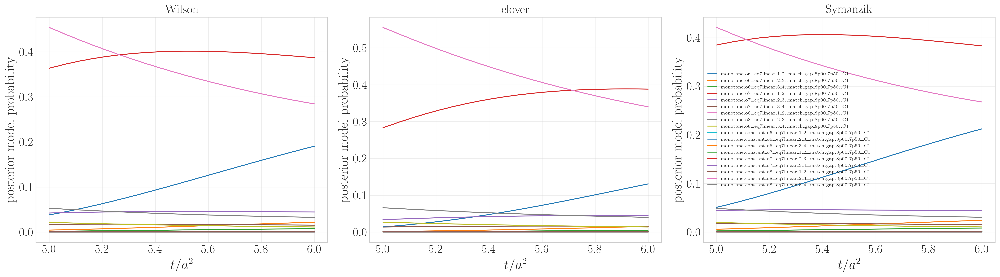

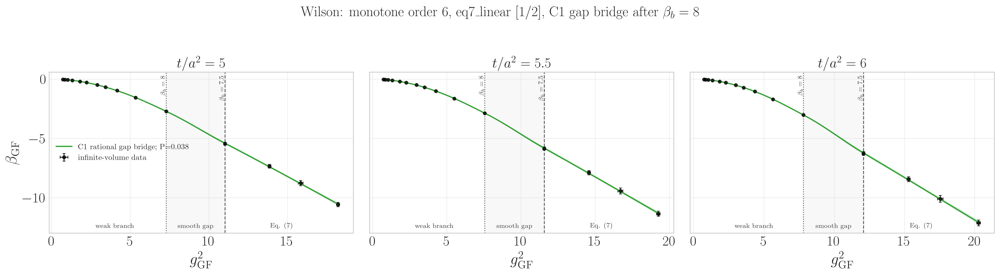

[candidate plot 1/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_1_2_match_gap_8p00_7p50_p


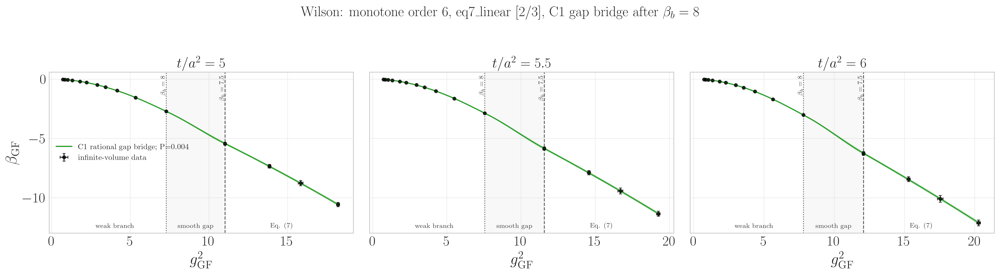

[candidate plot 2/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_2_3_match_gap_8p00_7p50_p


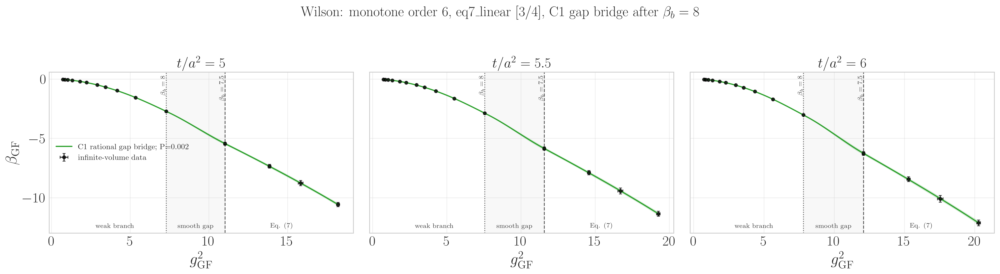

[candidate plot 3/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_3_4_match_gap_8p00_7p50_p


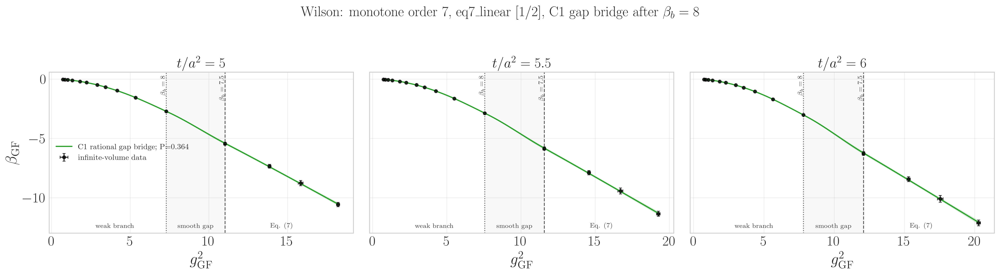

[candidate plot 4/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_1_2_match_gap_8p00_7p50_p


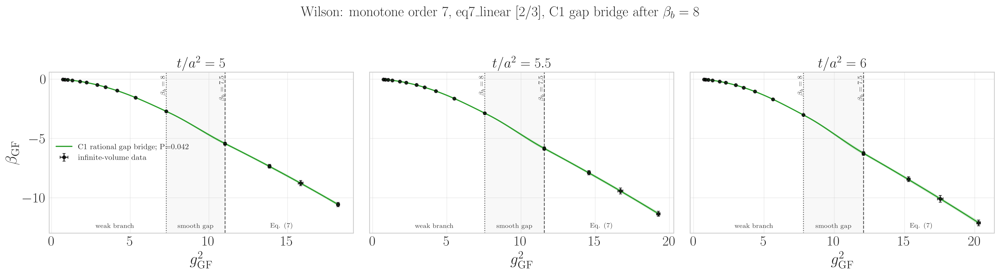

[candidate plot 5/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_2_3_match_gap_8p00_7p50_p


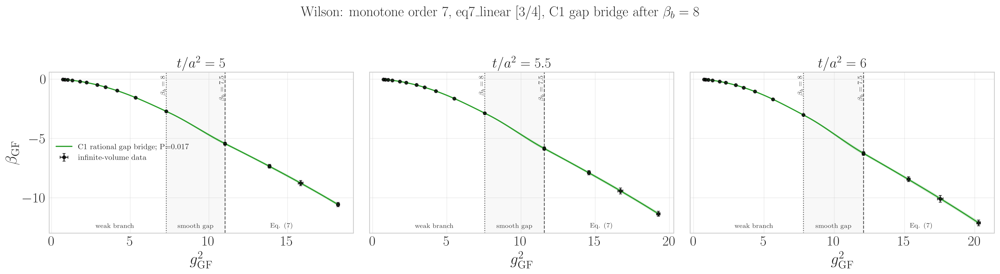

[candidate plot 6/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_3_4_match_gap_8p00_7p50_p


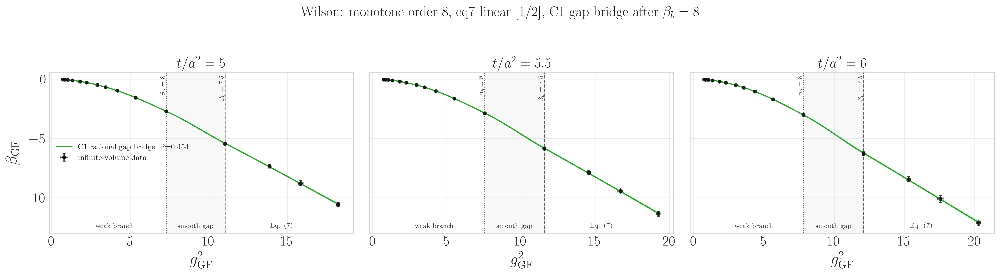

[candidate plot 7/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_1_2_match_gap_8p00_7p50_p


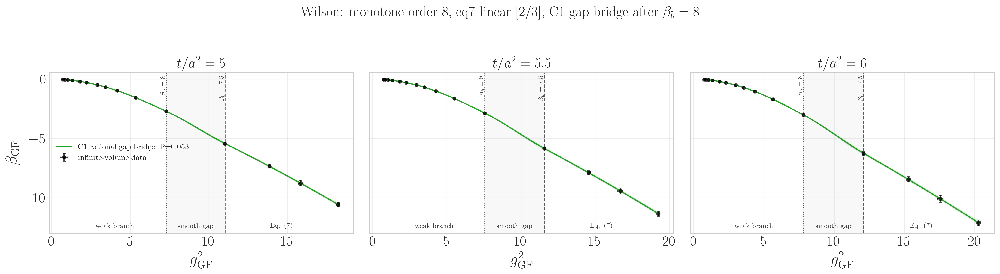

[candidate plot 8/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_2_3_match_gap_8p00_7p50_p


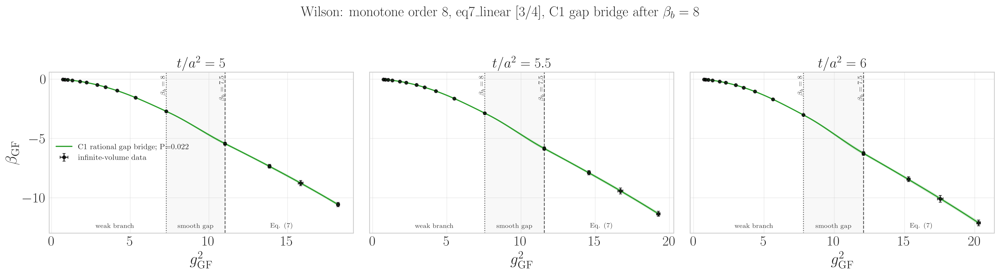

[candidate plot 9/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_3_4_match_gap_8p00_7p50_p


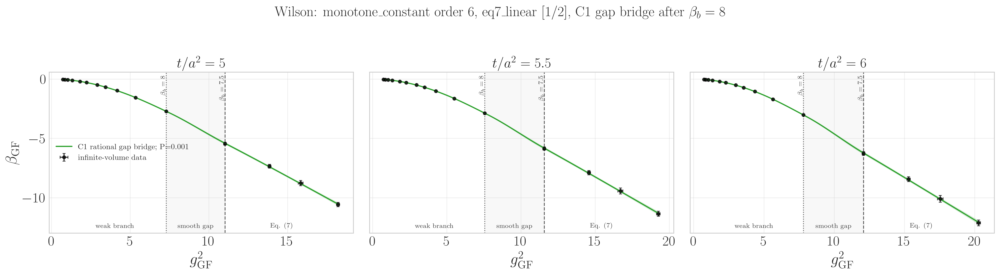

[candidate plot 10/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_1_2_match_gap_8p00_7p50_p


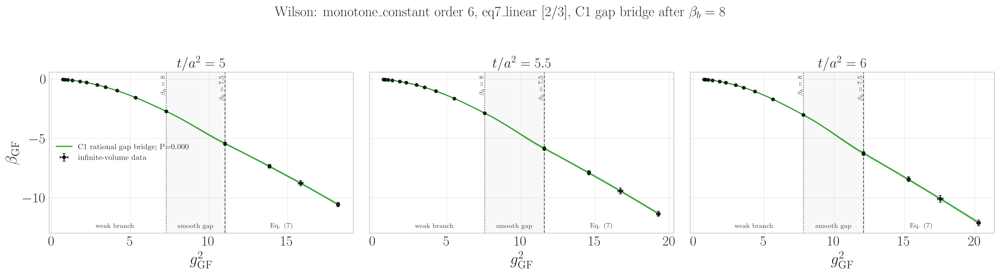

[candidate plot 11/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_2_3_match_gap_8p00_7p50_p


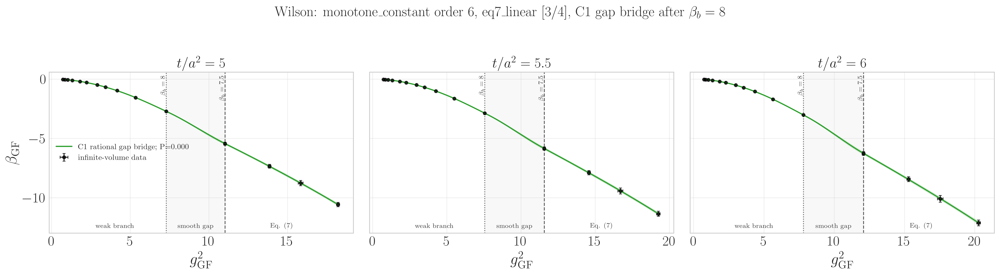

[candidate plot 12/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_3_4_match_gap_8p00_7p50_p


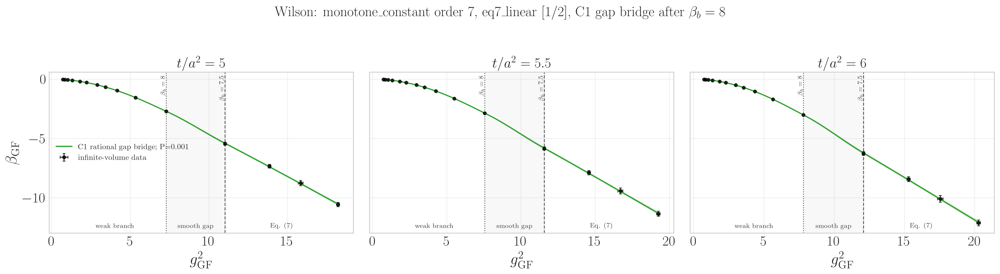

[candidate plot 13/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_1_2_match_gap_8p00_7p50_p


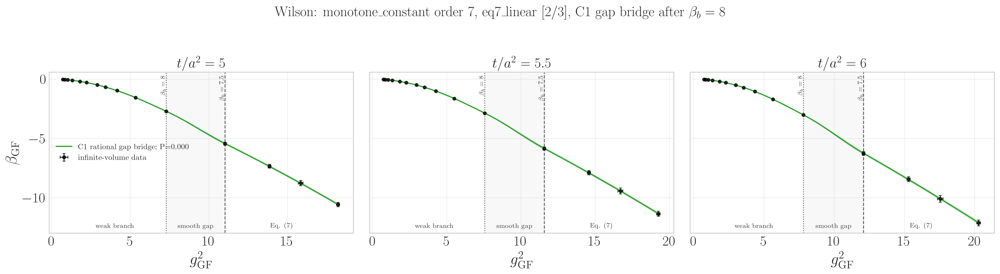

[candidate plot 14/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_2_3_match_gap_8p00_7p50_p


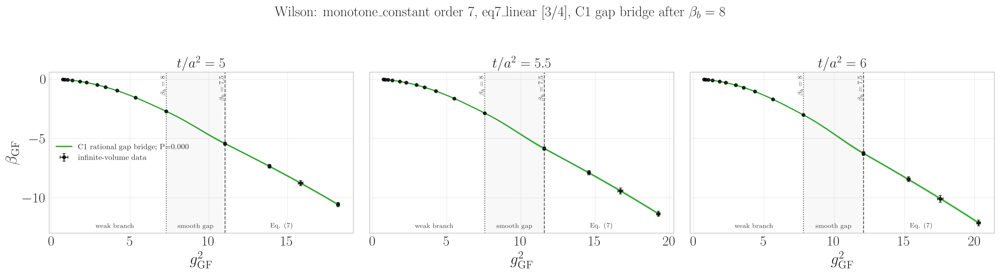

[candidate plot 15/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_3_4_match_gap_8p00_7p50_p


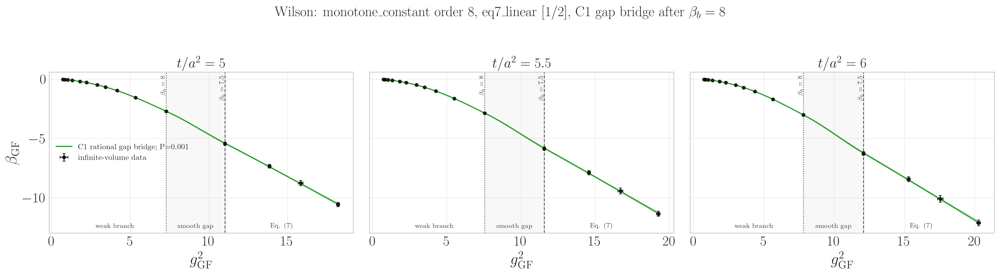

[candidate plot 16/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_1_2_match_gap_8p00_7p50_p


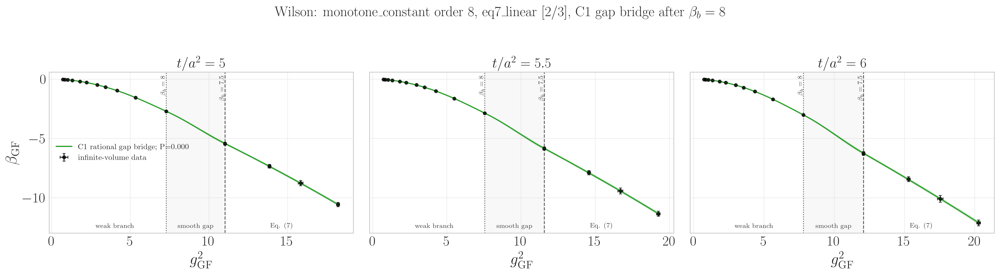

[candidate plot 17/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_2_3_match_gap_8p00_7p50_p


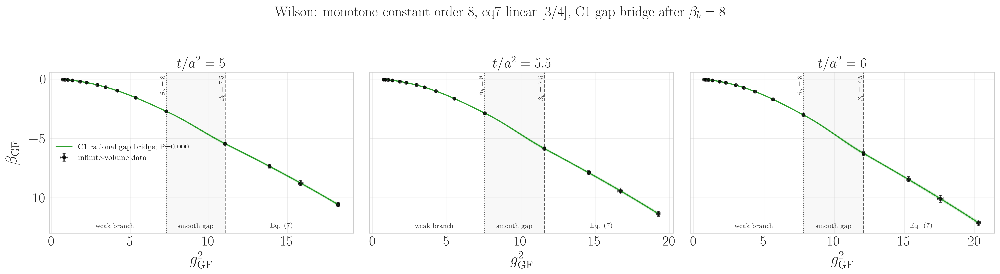

[candidate plot 18/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_3_4_match_gap_8p00_7p50_p


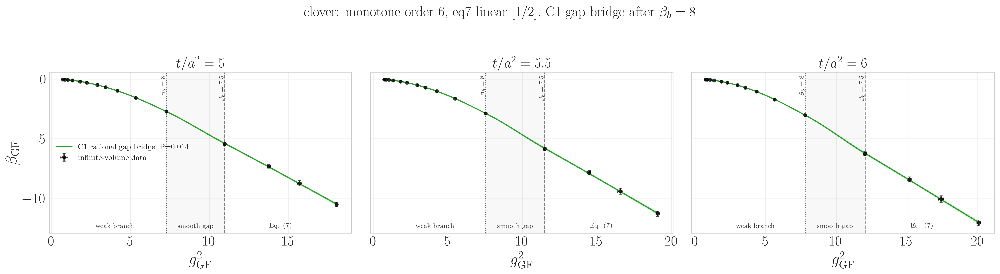

[candidate plot 19/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_1_2_match_gap_8p00_7p50_c


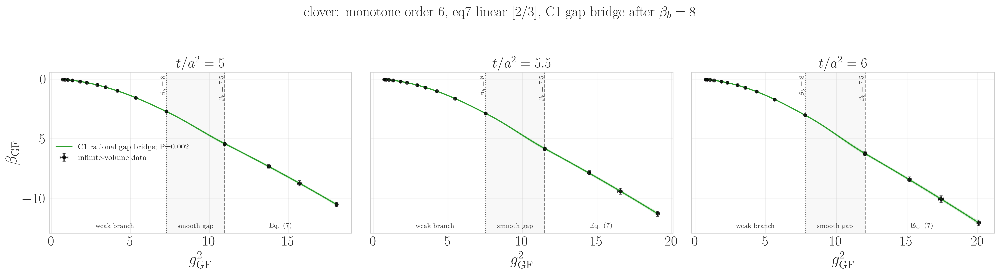

[candidate plot 20/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_2_3_match_gap_8p00_7p50_c


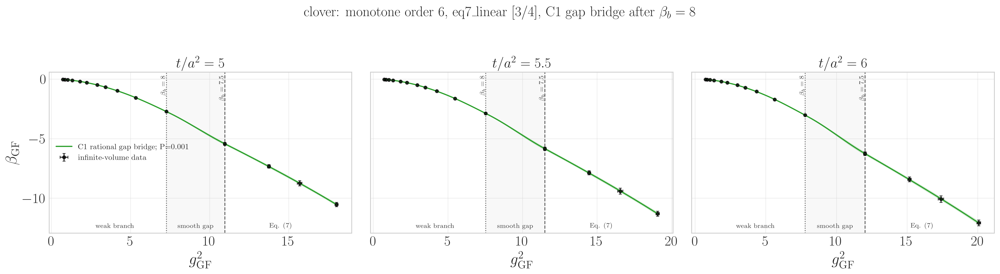

[candidate plot 21/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_3_4_match_gap_8p00_7p50_c


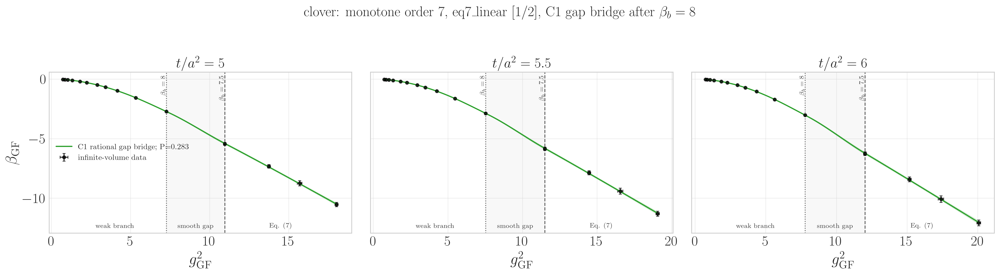

[candidate plot 22/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_1_2_match_gap_8p00_7p50_c


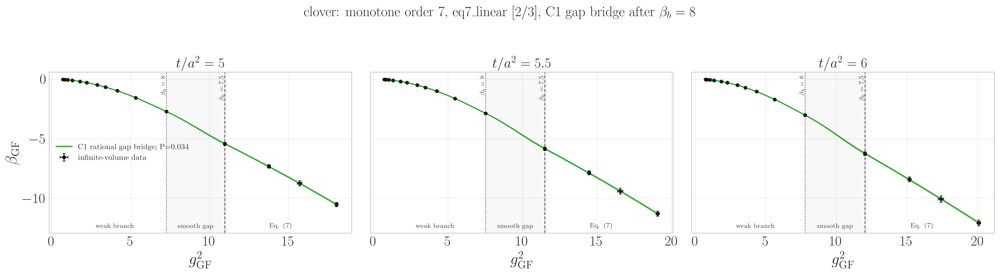

[candidate plot 23/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_2_3_match_gap_8p00_7p50_c


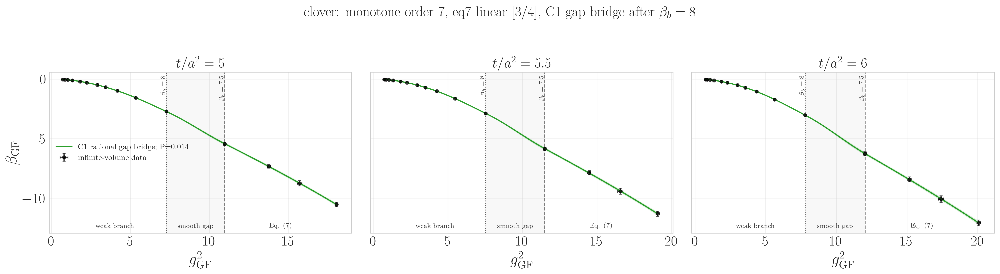

[candidate plot 24/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_3_4_match_gap_8p00_7p50_c


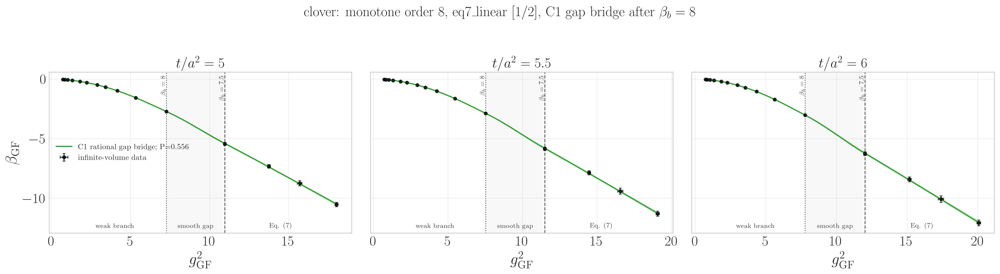

[candidate plot 25/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_1_2_match_gap_8p00_7p50_c


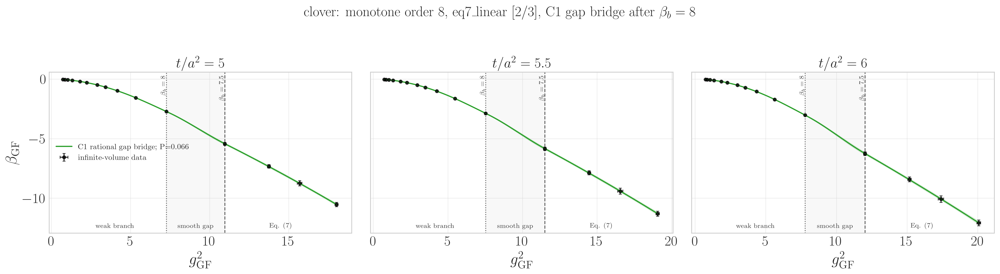

[candidate plot 26/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_2_3_match_gap_8p00_7p50_c


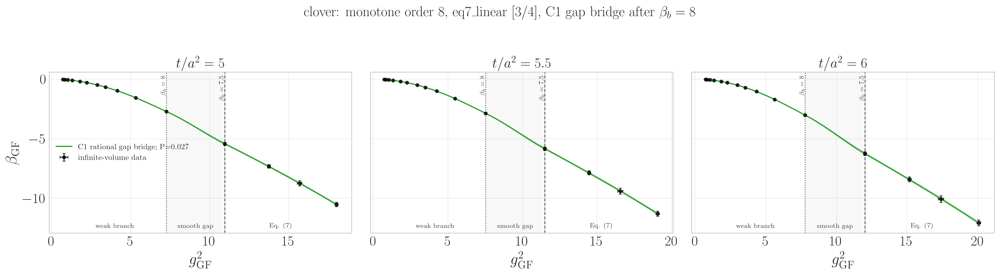

[candidate plot 27/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_3_4_match_gap_8p00_7p50_c


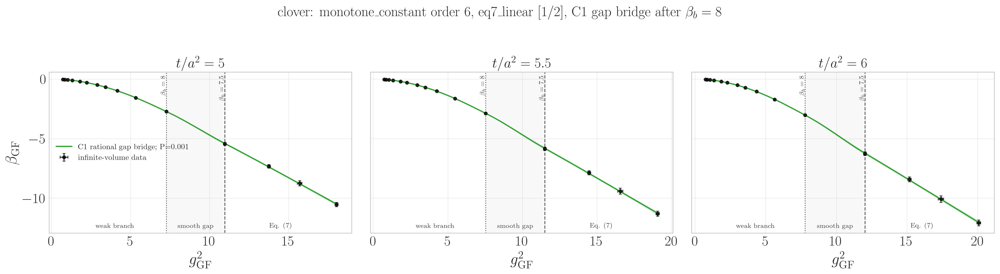

[candidate plot 28/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_1_2_match_gap_8p00_7p50_c


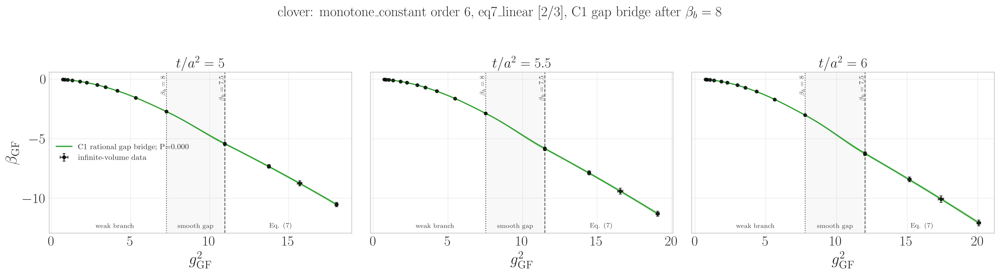

[candidate plot 29/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_2_3_match_gap_8p00_7p50_c


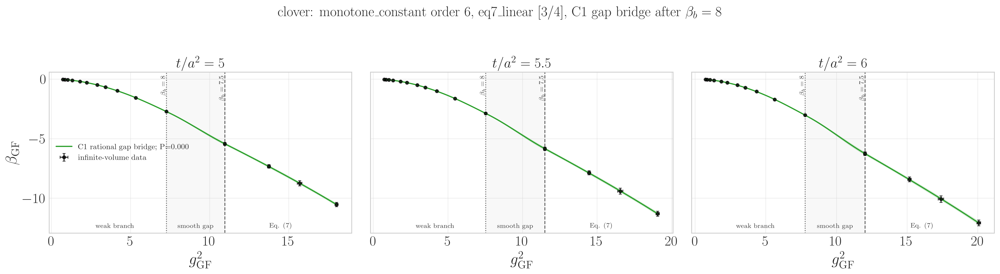

[candidate plot 30/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_3_4_match_gap_8p00_7p50_c


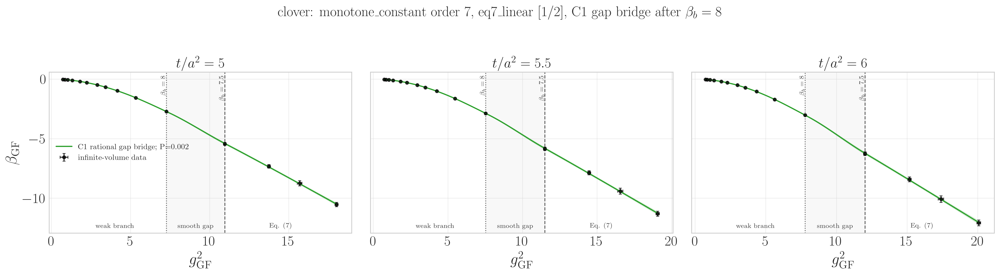

[candidate plot 31/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_1_2_match_gap_8p00_7p50_c


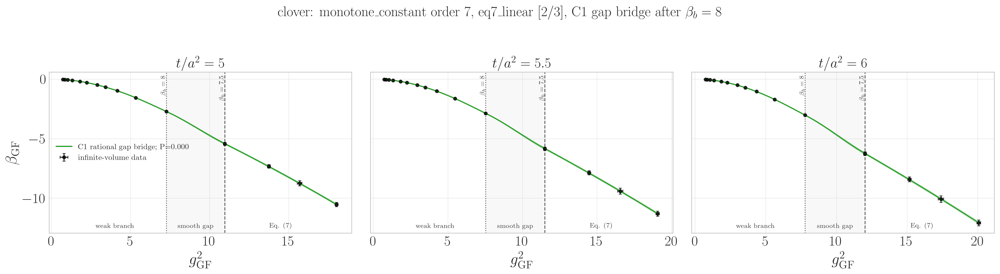

[candidate plot 32/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_2_3_match_gap_8p00_7p50_c


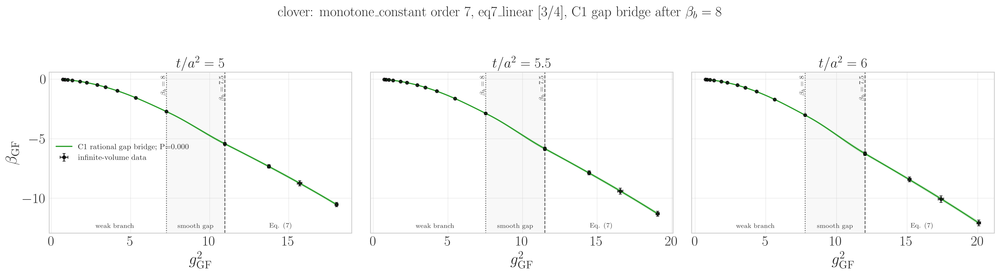

[candidate plot 33/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_3_4_match_gap_8p00_7p50_c


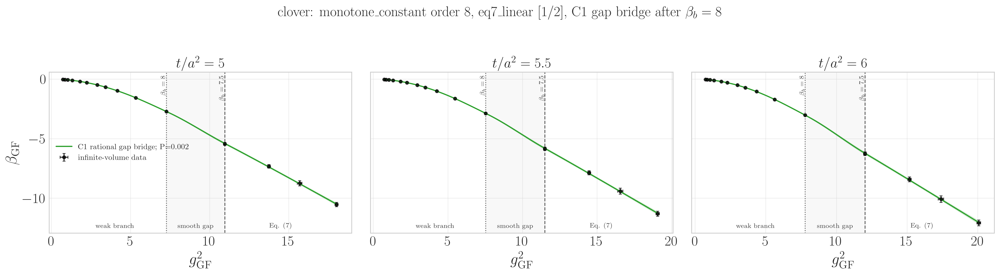

[candidate plot 34/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_1_2_match_gap_8p00_7p50_c


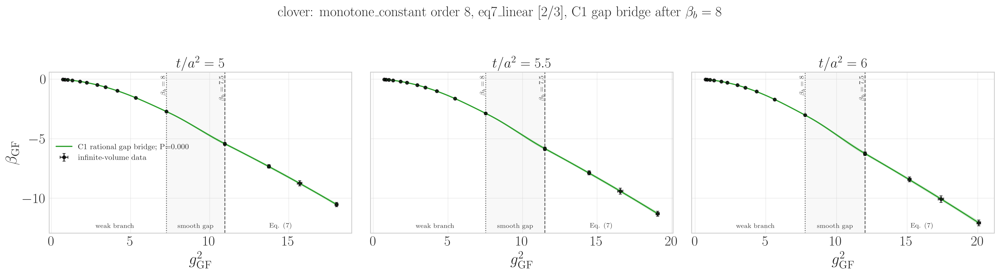

[candidate plot 35/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_2_3_match_gap_8p00_7p50_c


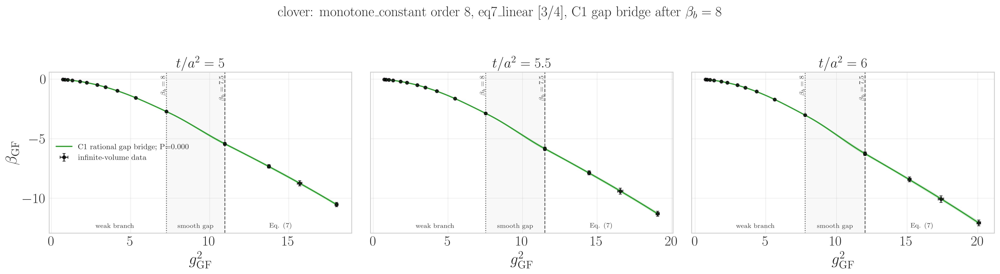

[candidate plot 36/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_3_4_match_gap_8p00_7p50_c


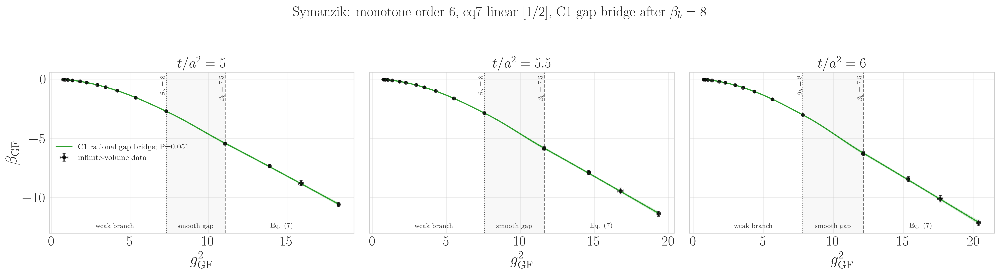

[candidate plot 37/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_1_2_match_gap_8p00_7p50_s


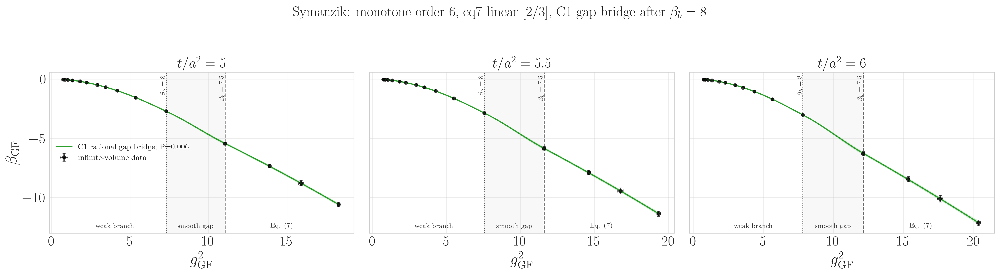

[candidate plot 38/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_2_3_match_gap_8p00_7p50_s


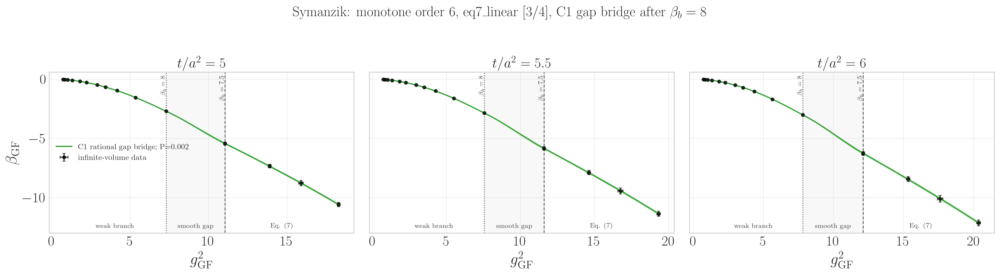

[candidate plot 39/54] hybrid_candidate_interpolation_monotone_o6_eq7_linear_3_4_match_gap_8p00_7p50_s


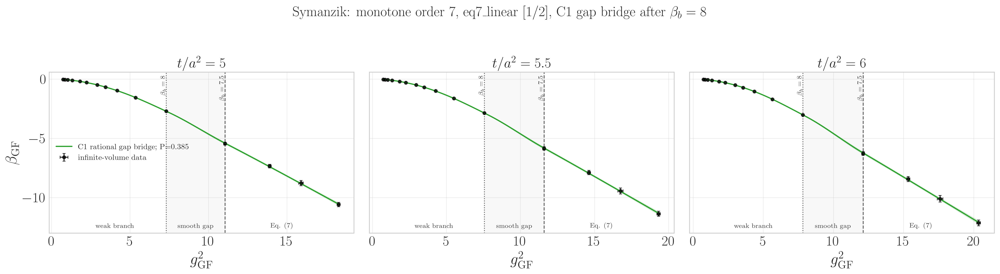

[candidate plot 40/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_1_2_match_gap_8p00_7p50_s


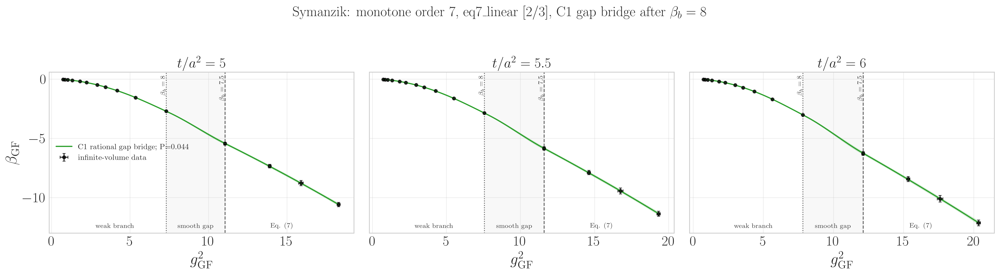

[candidate plot 41/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_2_3_match_gap_8p00_7p50_s


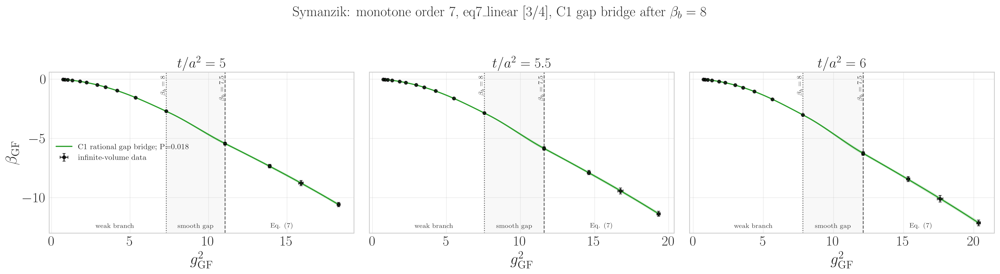

[candidate plot 42/54] hybrid_candidate_interpolation_monotone_o7_eq7_linear_3_4_match_gap_8p00_7p50_s


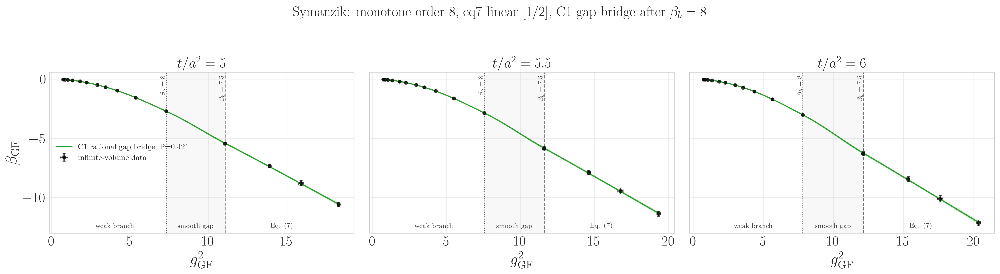

[candidate plot 43/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_1_2_match_gap_8p00_7p50_s


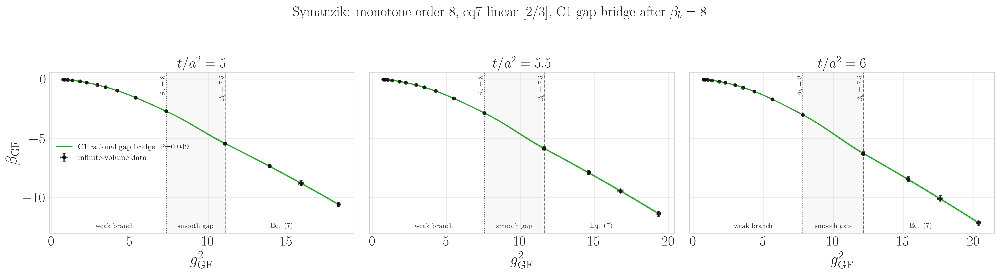

[candidate plot 44/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_2_3_match_gap_8p00_7p50_s


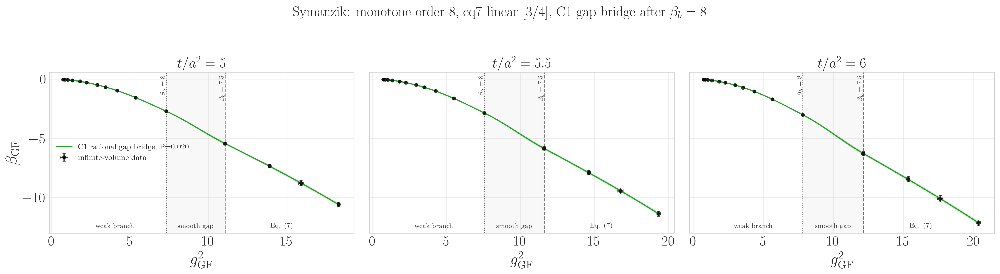

[candidate plot 45/54] hybrid_candidate_interpolation_monotone_o8_eq7_linear_3_4_match_gap_8p00_7p50_s


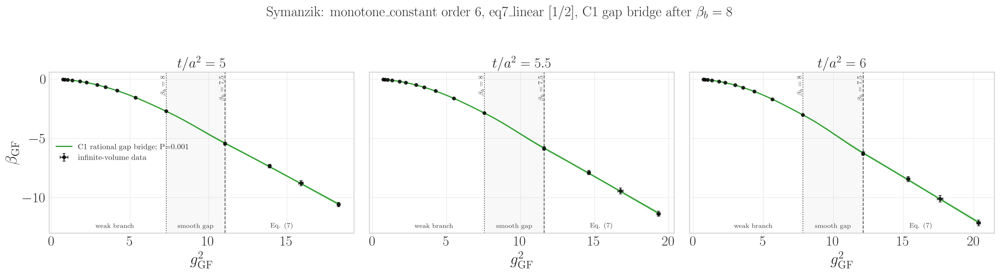

[candidate plot 46/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_1_2_match_gap_8p00_7p50_s


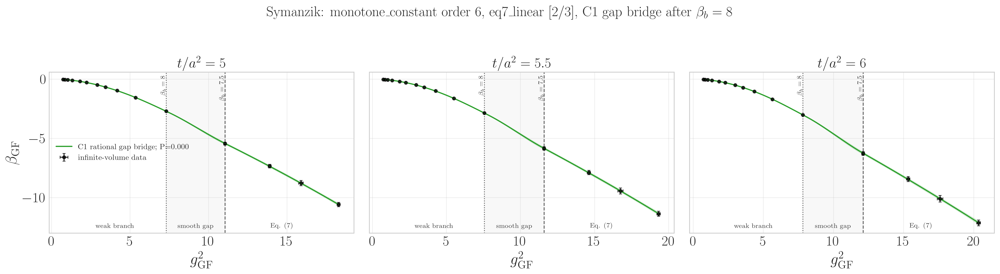

[candidate plot 47/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_2_3_match_gap_8p00_7p50_s


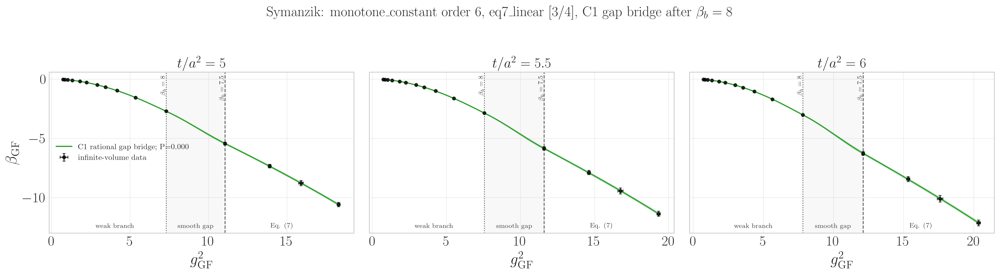

[candidate plot 48/54] hybrid_candidate_interpolation_monotone_constant_o6_eq7_linear_3_4_match_gap_8p00_7p50_s


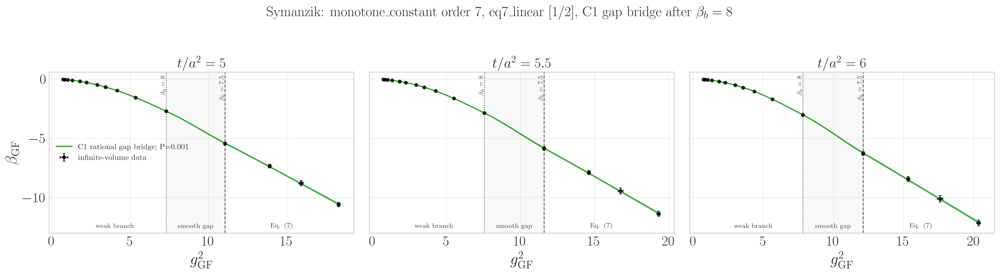

[candidate plot 49/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_1_2_match_gap_8p00_7p50_s


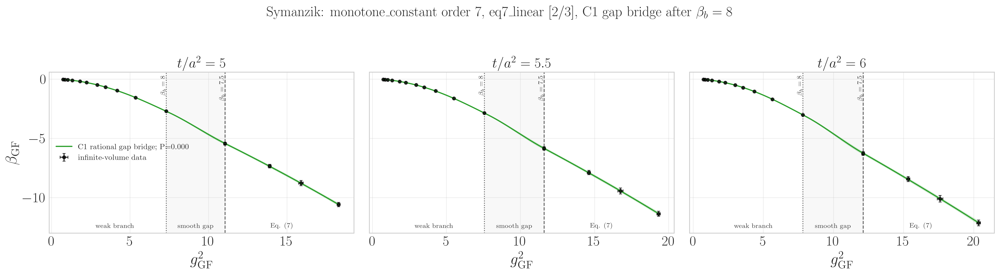

[candidate plot 50/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_2_3_match_gap_8p00_7p50_s


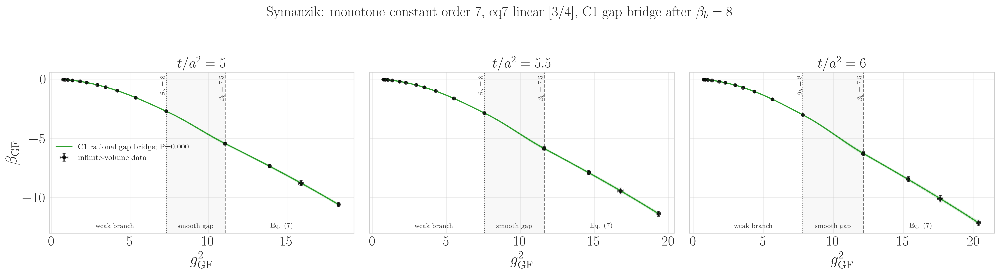

[candidate plot 51/54] hybrid_candidate_interpolation_monotone_constant_o7_eq7_linear_3_4_match_gap_8p00_7p50_s


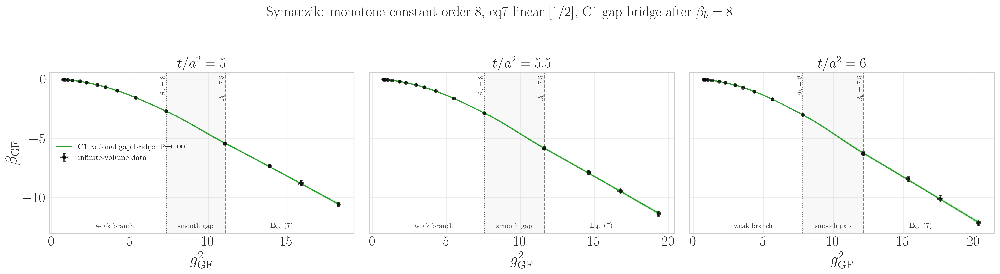

[candidate plot 52/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_1_2_match_gap_8p00_7p50_s


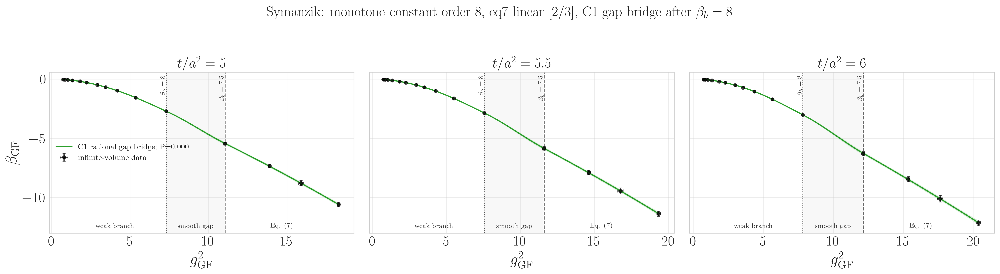

[candidate plot 53/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_2_3_match_gap_8p00_7p50_s


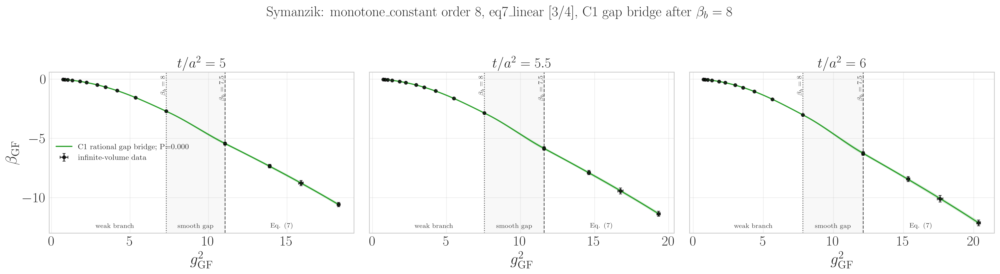

[candidate plot 54/54] hybrid_candidate_interpolation_monotone_constant_o8_eq7_linear_3_4_match_gap_8p00_7p50_s


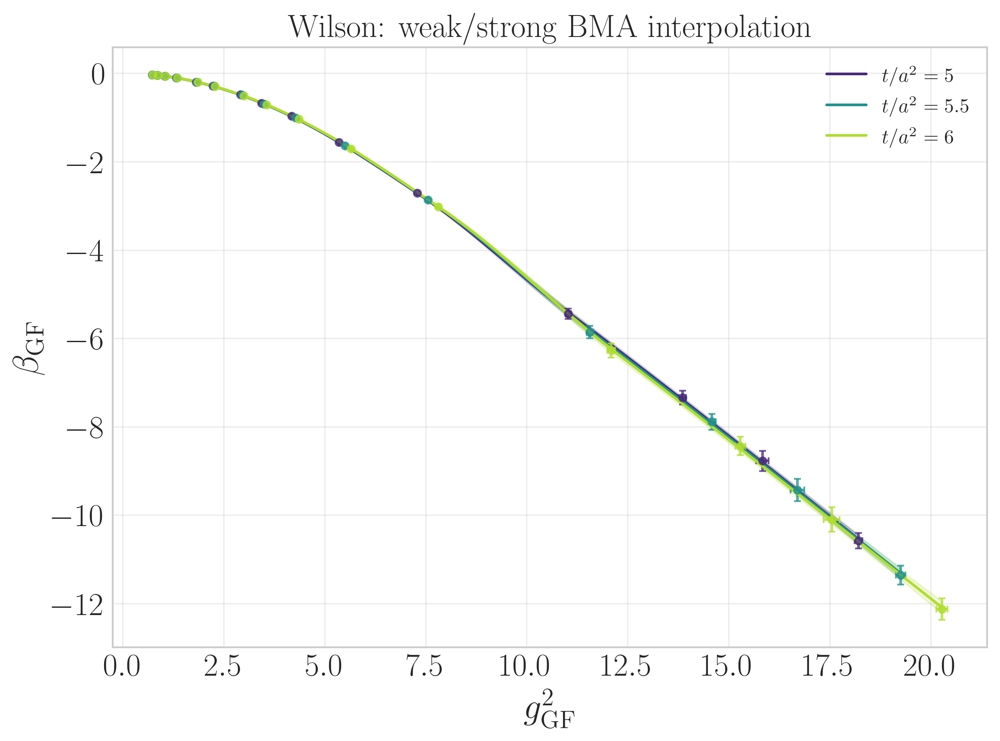

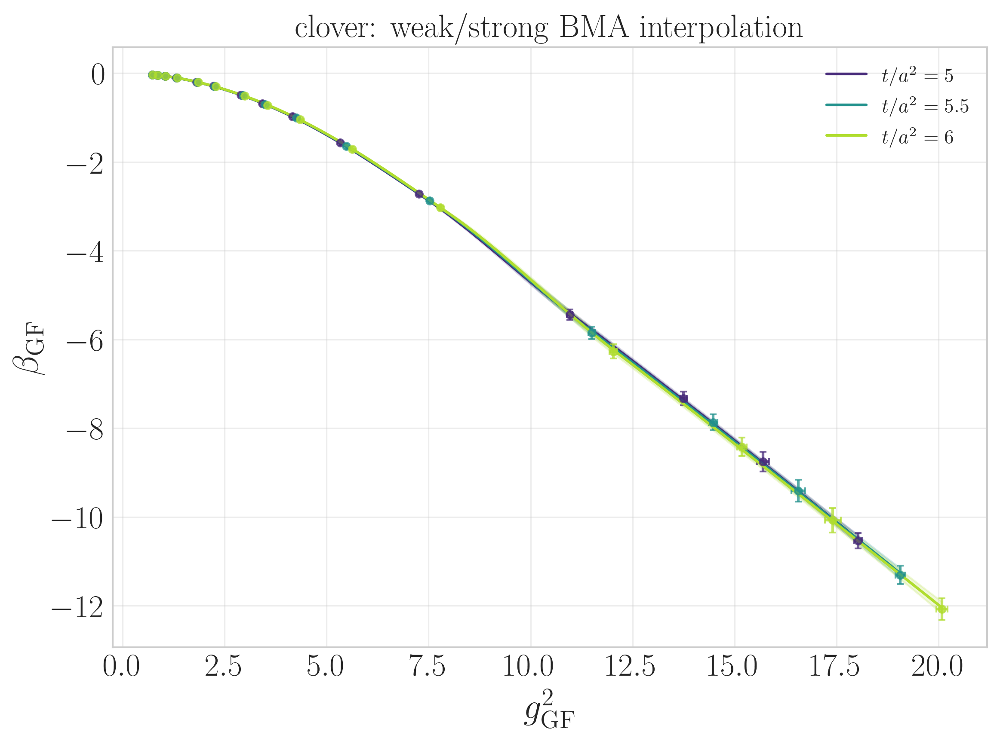

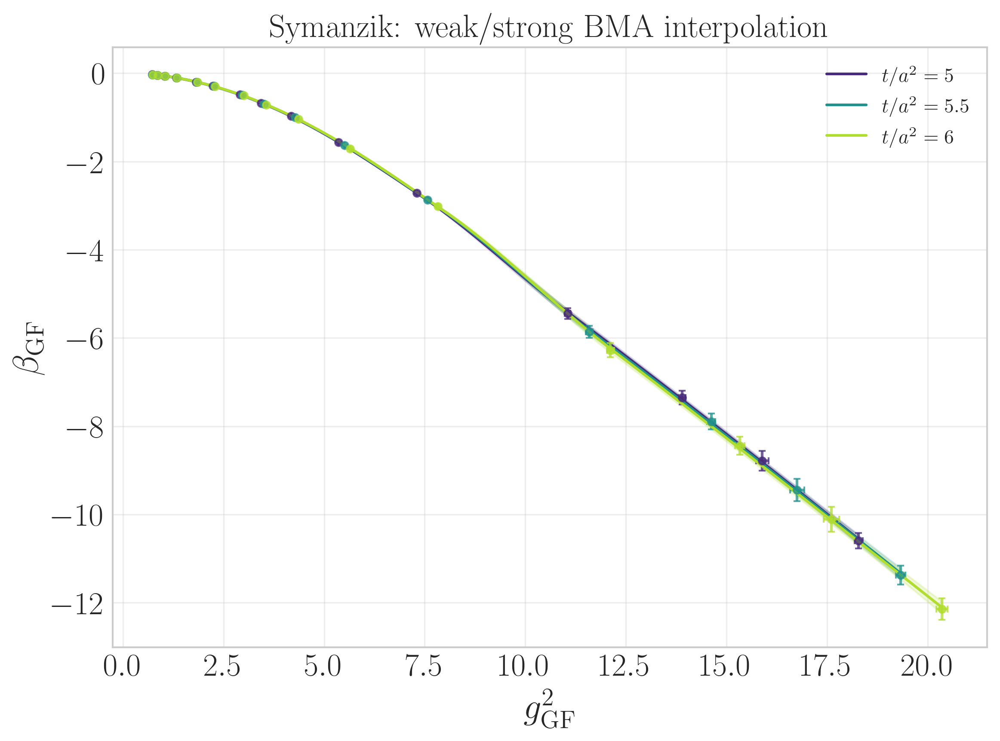

[DONE] candidate and model-averaged interpolation plots (0.8 min)


In [54]:
progress_start('candidate and model-averaged interpolation plots')
central_interpolations = hybrid_interpolations[CENTRAL_WINDOW]

# Evidence weights are specific to one operator and one flow time.
fig, axes = plt.subplots(
    1, len(OBSERVABLES), figsize=(7 * len(OBSERVABLES), 6), squeeze=False,
)
for ax, operator in zip(axes.ravel(), OBSERVABLES):
    keys = sorted(
        [key for key in central_interpolations if key[1] == operator],
        key=lambda key: float(key[2]),
    )
    for model in central_interpolations[keys[0]].weights:
        ax.plot(
            [float(key[2]) for key in keys],
            [central_interpolations[key].weights[model] for key in keys],
            lw=1.4, label=model,
        )
    ax.set_xlabel(r'$t/a^2$')
    ax.set_ylabel('posterior model probability')
    ax.set_title(OP_LABELS[operator])
axes.ravel()[-1].legend(frameon=False, fontsize=7)
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_model_weights'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)

continuity_colors = {0: 'tab:blue', 1: 'tab:green', 2: 'tab:orange'}
continuity_styles = {0: '-', 1: '-', 2: '--'}
candidate_plot_jobs = []
candidate_group_keys = set()
for operator in OBSERVABLES:
    operator_keys = sorted(
        [key for key in central_interpolations if key[1] == operator],
        key=lambda key: float(key[2]),
    )
    selected_indices = sorted(set((0, len(operator_keys) // 2, len(operator_keys) - 1)))
    selected_keys = tuple(operator_keys[index] for index in selected_indices)
    interpolation_result = central_interpolations[selected_keys[0]]
    candidate_groups = {}
    for name, candidate_fit in interpolation_result.candidate_fits.items():
        candidate = candidate_fit.candidate
        group_key = (
            candidate.weak_family, candidate.weak_order,
            candidate.strong_form,
            candidate.numerator_order, candidate.denominator_order,
            candidate.match_fraction,
            candidate.match_lower, candidate.match_upper,
        )
        candidate_groups.setdefault(group_key, []).append(name)
        candidate_group_keys.add(group_key)
    candidate_plot_jobs.extend(
        (operator, selected_keys, group_key, names)
        for group_key, names in candidate_groups.items()
    )
for plot_index, (
    operator, selected_keys, group_key, variant_names
) in enumerate(
    candidate_plot_jobs, start=1
):
    fig, axes = plt.subplots(
        1, len(selected_keys), figsize=(6 * len(selected_keys), 5),
        squeeze=False, sharey=True,
    )
    for ax, key in zip(axes.ravel(), selected_keys):
        interpolation_result = central_interpolations[key]
        variants = sorted(
            [
                (name, interpolation_result.candidate_fits[name])
                for name in variant_names
            ],
            key=lambda item: item[1].candidate.continuity,
        )
        reference_candidate = variants[0][1]
        target = reference_candidate.targets[key]
        xmin, xmax = min(gv.mean(target.x)), max(gv.mean(target.x))
        xgrid = np.unique(np.r_[np.linspace(xmin, xmax, 240),
            target.match_low, target.match_high,
            target.match_low + .05*(target.match_high-target.match_low)])
        join_low = float(target.match_low)
        join_high = float(target.match_high)
        ax.axvspan(
            join_low, join_high, color='0.5', alpha=.055, zorder=0,
        )
        ax.axvline(
            join_low, color='0.35', ls=':', lw=1.1, zorder=1,
        )
        ax.axvline(
            join_high, color='0.35', ls='--', lw=1.1, zorder=1,
        )
        axis_transform = ax.get_xaxis_transform()
        ax.text(
            .5 * (xmin + join_low), .025, 'weak branch',
            transform=axis_transform, ha='center', va='bottom',
            fontsize=8.5, color='0.25',
        )
        ax.text(
            .5 * (join_low + join_high), .025, 'smooth gap',
            transform=axis_transform, ha='center', va='bottom',
            fontsize=8.5, color='0.25',
        )
        ax.text(
            .5 * (join_high + xmax), .025, 'Eq. (7)',
            transform=axis_transform, ha='center', va='bottom',
            fontsize=8.5, color='0.25',
        )
        ax.text(
            join_low, .98, r'$\beta_b=8$',
            transform=axis_transform, ha='right', va='top',
            fontsize=8.5, color='0.25', rotation=90,
        )
        ax.text(
            join_high, .98, r'$\beta_b=7.5$',
            transform=axis_transform, ha='right', va='top',
            fontsize=8.5, color='0.25', rotation=90,
        )
        ax.errorbar(
            gv.mean(target.x), gv.mean(target.y),
            xerr=gv.sdev(target.x), yerr=gv.sdev(target.y),
            fmt='o', ms=4, capsize=2, color='black', alpha=.70,
            label='infinite-volume data',
        )
        for name, candidate_fit in variants:
            continuity = candidate_fit.candidate.continuity
            prediction = np.asarray(
                betafn.fitting.hybrid.evaluate_hybrid_target(
                    candidate_fit, bf, key, xgrid
                ), dtype=object,
            )
            mean, sdev = gv.mean(prediction), gv.sdev(prediction)
            color = continuity_colors.get(continuity, f'C{continuity % 10}')
            if candidate_fit.candidate.strong_form in ('eq7_blend', 'eq7_hermite', 'eq7_linear'):
                label = (
                    (
                        'C1 Hermite bridge; '
                        if candidate_fit.candidate.strong_form == 'eq7_hermite'
                        else (
                            'C1 rational gap bridge; '
                            if candidate_fit.candidate.strong_form == 'eq7_linear'
                            else 'C2 gap blend; '
                        )
                    )
                    +
                    f'P={interpolation_result.weights[name]:.3f}'
                )
            else:
                fitted_fraction = hybrid_match_fraction(candidate_fit)
                label = (
                    f'C{continuity}; '
                    f'f={gv.mean(fitted_fraction):.3f}({gv.sdev(fitted_fraction):.3f}); '
                    f'P={interpolation_result.weights[name]:.3f}'
                )
            ax.plot(
                xgrid, mean, color=color,
                ls=continuity_styles.get(continuity, '-'), label=label,
            )
            ax.fill_between(
                xgrid, mean-sdev, mean+sdev, color=color, alpha=.14,
            )
        ax.set_title(rf'$t/a^2={float(key[2]):g}$')
        ax.set_xlabel(r'$g^2_{\rm GF}$')
    axes.ravel()[0].set_ylabel(r'$\beta_{\rm GF}$')
    axes.ravel()[0].legend(frameon=False, fontsize=10)
    (family, order, strong_form, numerator, denominator, fraction,
     match_lower, match_upper) = group_key
    if strong_form == 'eq7_linear':
        transition_description = (
            r'C1 gap bridge after $\beta_b=8$'
        )
    elif strong_form == 'eq7_hermite':
        transition_description = (
            r'C1 Hermite bridge across $\beta_b=8\to7.5$ gap'
        )
    elif strong_form == 'eq7_blend':
        transition_description = (
            r'C2 blend across $\beta_b=8\to7.5$ gap'
        )
    elif fraction is None:
        transition_description = (
            f'match fitted in [{match_lower:.2f}, {match_upper:.2f}]'
        )
    else:
        transition_description = f'match={fraction:.2f}'
    fig.suptitle(
        f'{OP_LABELS[operator]}: {family} order {order}, '
        f'{strong_form} [{numerator}/{denominator}], '
        + transition_description
    )
    fig.tight_layout(rect=(0, 0, 1, .94))
    fraction_tag = (
        'gap_8p00_7p50'
        if strong_form in ('eq7_blend', 'eq7_hermite', 'eq7_linear')
        else (
            (f'fitted_{match_lower:.2f}_{match_upper:.2f}'.replace('.', 'p'))
            if fraction is None
            else f'{fraction:.2f}'.replace('.', 'p')
        )
    )
    base = HYBRID_OUTPUT_ROOT / (
        f'hybrid_candidate_interpolation_{family}_o{order}_'
        f'{strong_form}_{numerator}_{denominator}_match_{fraction_tag}_{operator}'
    )
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
    print(
        f'[candidate plot {plot_index}/{len(candidate_plot_jobs)}] '
        f'{base.name}',
        flush=True,
    )

for operator in OBSERVABLES:
    keys = sorted(
        [key for key in central_interpolations if key[1] == operator],
        key=lambda key: float(key[2]),
    )
    selected_indices = sorted(set((0, len(keys) // 2, len(keys) - 1)))
    fig, ax = plt.subplots(figsize=(8, 6))
    colors = plt.cm.viridis(np.linspace(.12, .88, len(selected_indices)))
    for color, selected_index in zip(colors, selected_indices):
        key = keys[selected_index]
        interpolation_result = central_interpolations[key]
        reference_fit = next(iter(interpolation_result.candidate_fits.values()))
        target = reference_fit.targets[key]
        xmin, xmax = min(gv.mean(target.x)), max(gv.mean(target.x))
        xgrid = np.unique(np.r_[np.linspace(xmin, xmax, 240),
            target.match_low, target.match_high,
            target.match_low + .05*(target.match_high-target.match_low)])
        predictions = {
            name: np.asarray(
                betafn.fitting.hybrid.evaluate_hybrid_target(
                    fit, bf, key, xgrid
                ), dtype=object,
            )
            for name, fit in interpolation_result.candidate_fits.items()
        }
        average = model_average_predictions(
            predictions, interpolation_result.weights
        )
        ax.plot(xgrid, average.mean, color=color, label=rf'$t/a^2={float(key[2]):g}$')
        sigma = np.sqrt(np.clip(np.diag(average.covariance), 0.0, None))
        ax.fill_between(xgrid, average.mean - sigma, average.mean + sigma, color=color, alpha=.18)
        ax.errorbar(
            gv.mean(target.x), gv.mean(target.y),
            xerr=gv.sdev(target.x), yerr=gv.sdev(target.y),
            fmt='o', ms=4, capsize=2, color=color, alpha=.75,
        )
    ax.set_xlabel(r'$g^2_{\rm GF}$'); ax.set_ylabel(r'$\beta_{\rm GF}$')
    ax.set_title(f'{OP_LABELS[operator]}: weak/strong BMA interpolation')
    ax.legend(frameon=False)
    fig.tight_layout()
    base = HYBRID_OUTPUT_ROOT / f'hybrid_bma_interpolation_{operator}'
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)

progress_done('candidate and model-averaged interpolation plots')


[START] candidate and model-averaged beta/g^4 interpolation plots


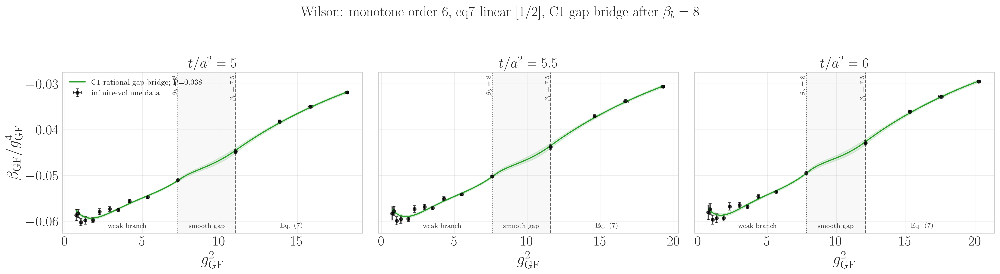

[beta/g^4 candidate plot 1/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_1_2_match_gap_8p00_7p50_p


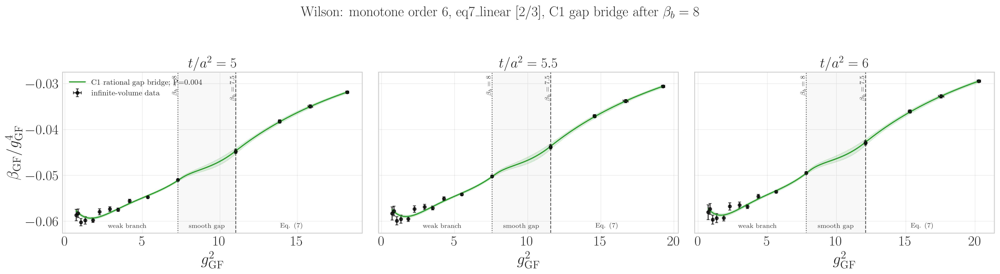

[beta/g^4 candidate plot 2/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_2_3_match_gap_8p00_7p50_p


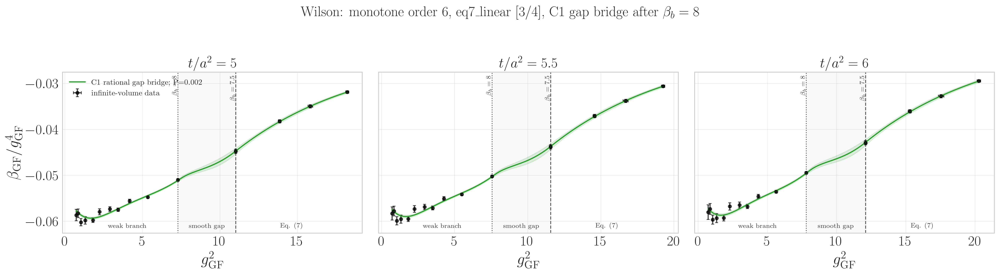

[beta/g^4 candidate plot 3/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_3_4_match_gap_8p00_7p50_p


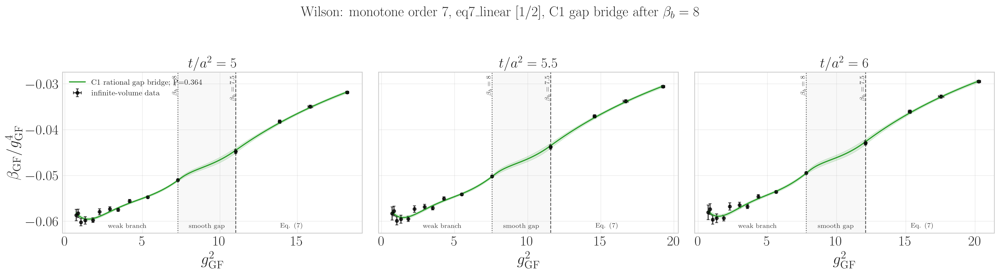

[beta/g^4 candidate plot 4/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_1_2_match_gap_8p00_7p50_p


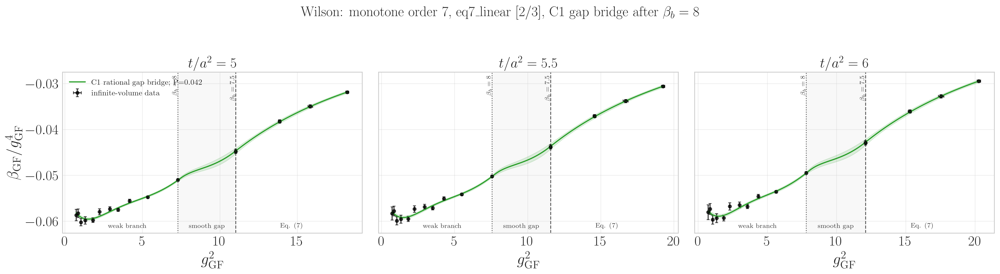

[beta/g^4 candidate plot 5/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_2_3_match_gap_8p00_7p50_p


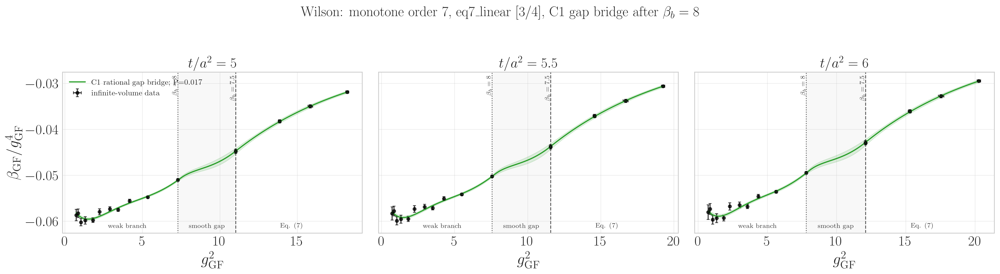

[beta/g^4 candidate plot 6/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_3_4_match_gap_8p00_7p50_p


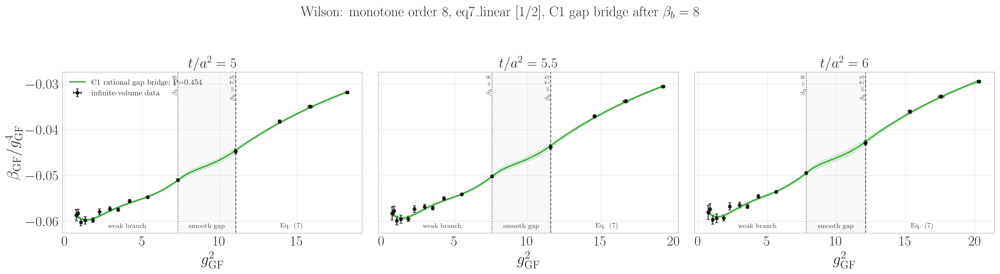

[beta/g^4 candidate plot 7/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_1_2_match_gap_8p00_7p50_p


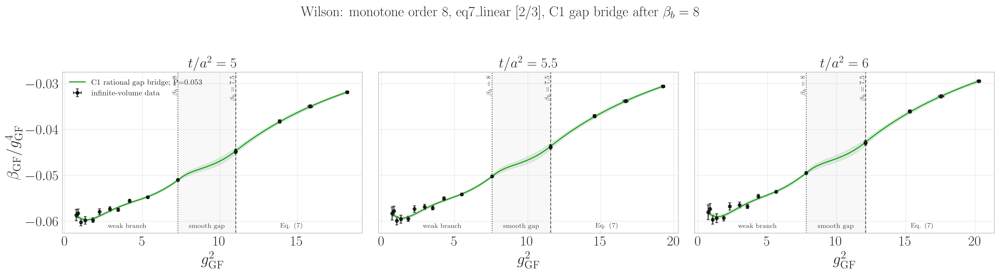

[beta/g^4 candidate plot 8/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_2_3_match_gap_8p00_7p50_p


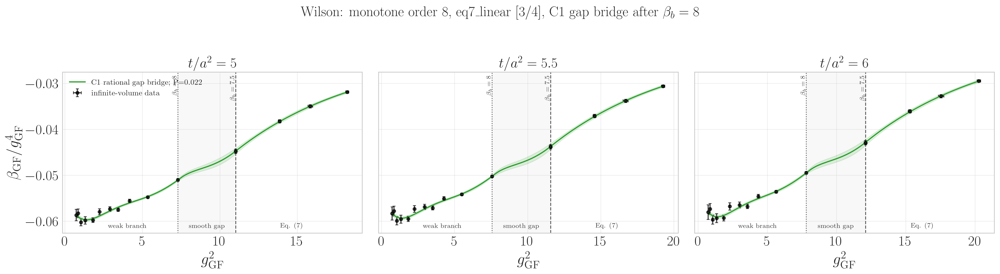

[beta/g^4 candidate plot 9/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_3_4_match_gap_8p00_7p50_p


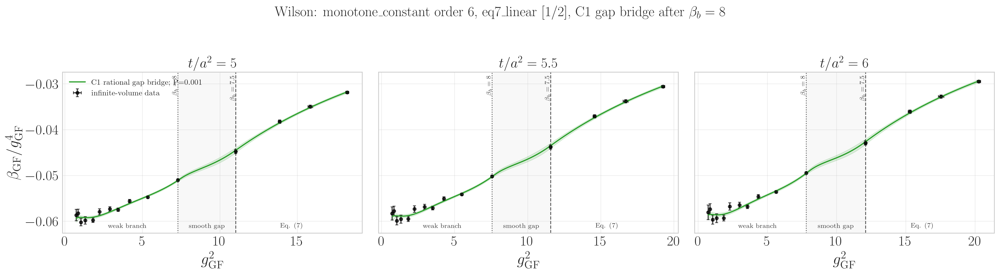

[beta/g^4 candidate plot 10/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_1_2_match_gap_8p00_7p50_p


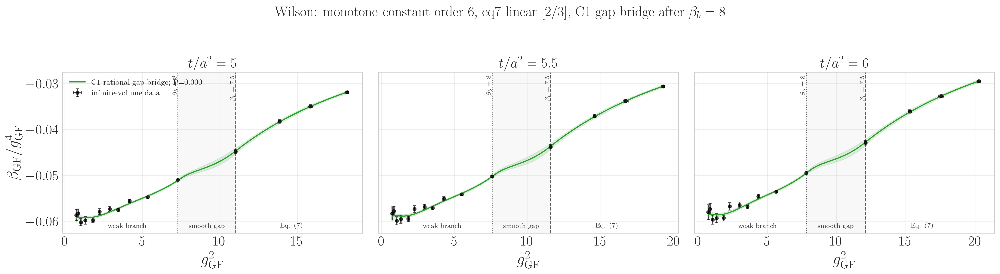

[beta/g^4 candidate plot 11/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_2_3_match_gap_8p00_7p50_p


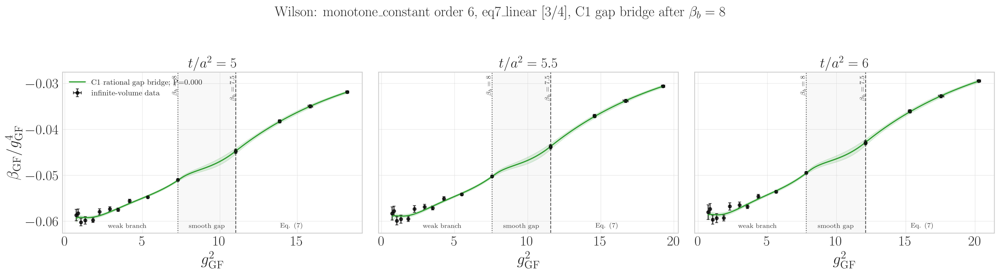

[beta/g^4 candidate plot 12/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_3_4_match_gap_8p00_7p50_p


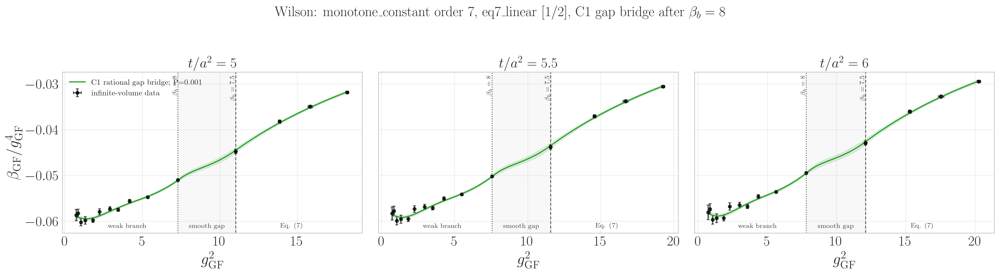

[beta/g^4 candidate plot 13/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_1_2_match_gap_8p00_7p50_p


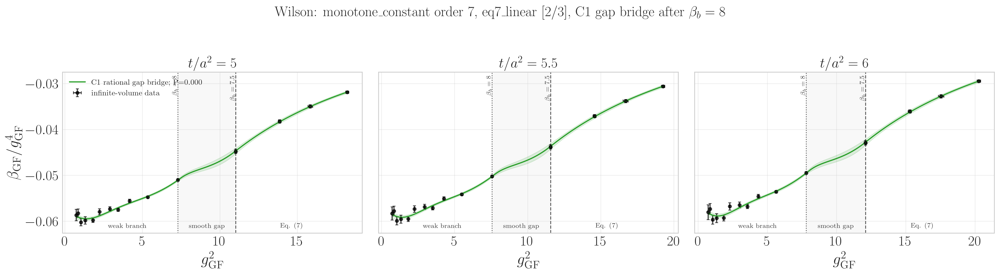

[beta/g^4 candidate plot 14/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_2_3_match_gap_8p00_7p50_p


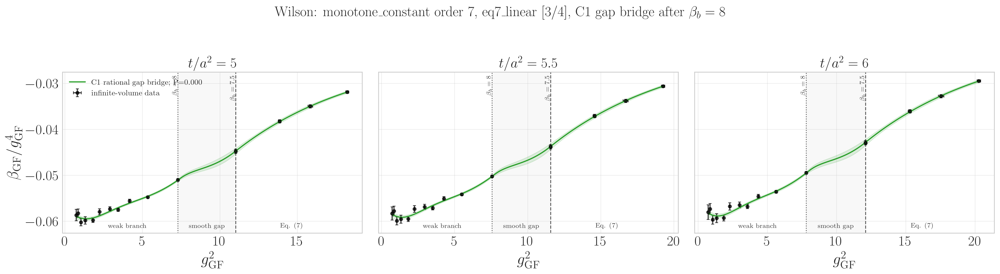

[beta/g^4 candidate plot 15/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_3_4_match_gap_8p00_7p50_p


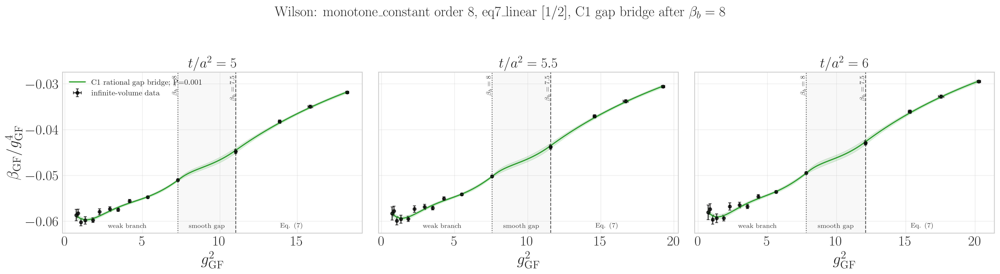

[beta/g^4 candidate plot 16/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_1_2_match_gap_8p00_7p50_p


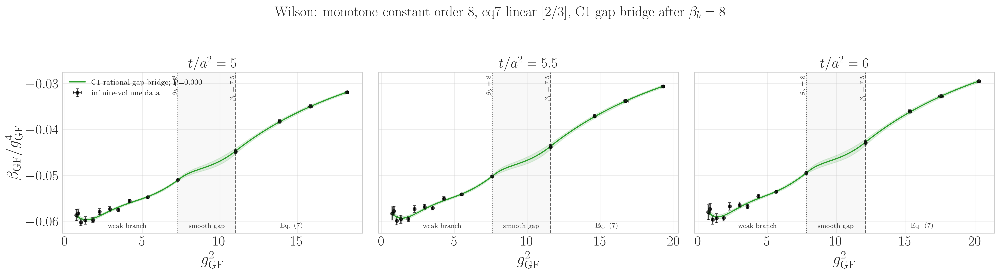

[beta/g^4 candidate plot 17/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_2_3_match_gap_8p00_7p50_p


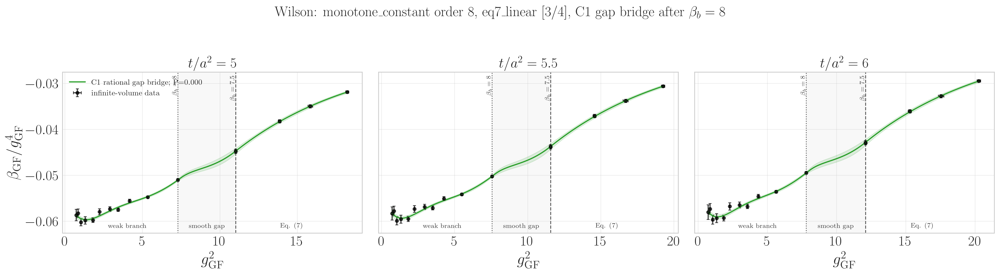

[beta/g^4 candidate plot 18/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_3_4_match_gap_8p00_7p50_p


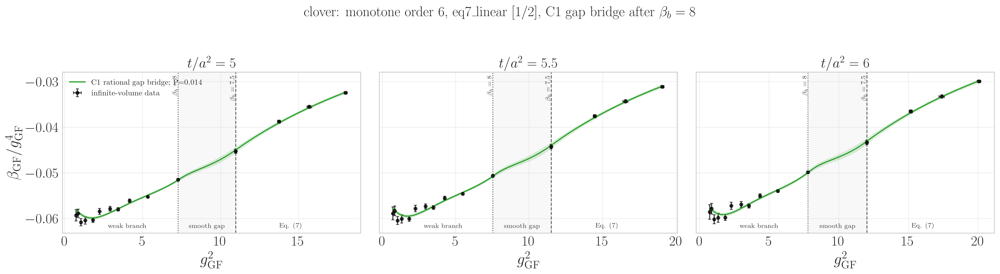

[beta/g^4 candidate plot 19/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_1_2_match_gap_8p00_7p50_c


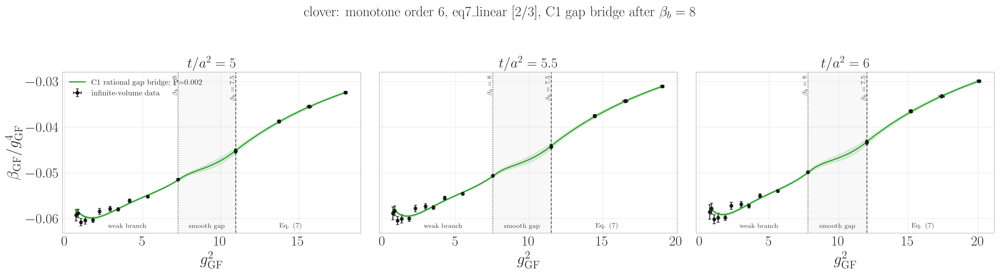

[beta/g^4 candidate plot 20/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_2_3_match_gap_8p00_7p50_c


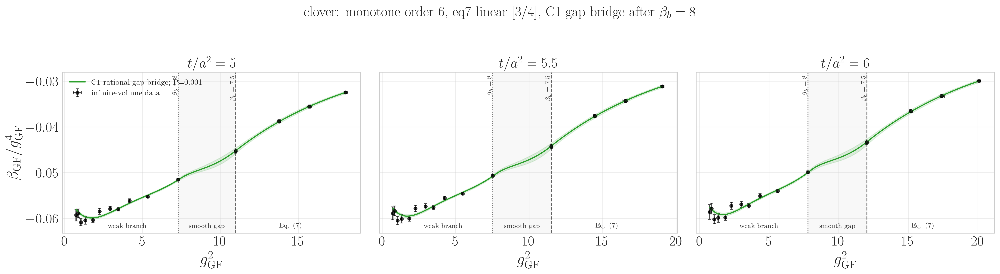

[beta/g^4 candidate plot 21/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_3_4_match_gap_8p00_7p50_c


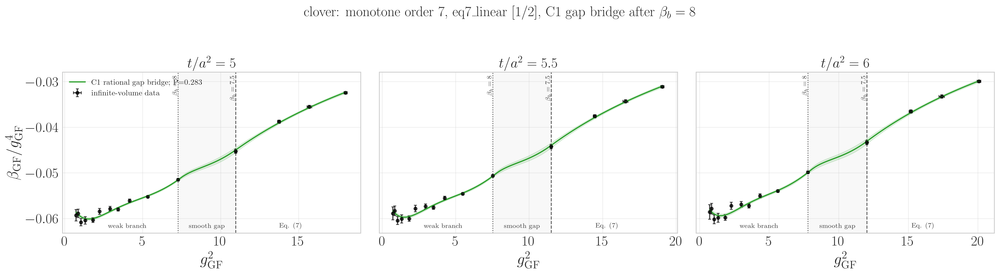

[beta/g^4 candidate plot 22/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_1_2_match_gap_8p00_7p50_c


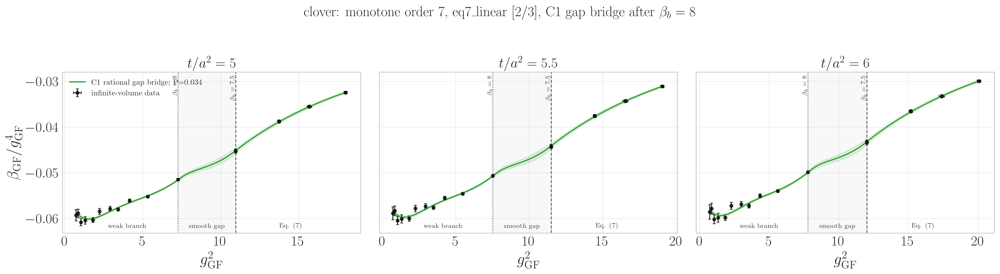

[beta/g^4 candidate plot 23/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_2_3_match_gap_8p00_7p50_c


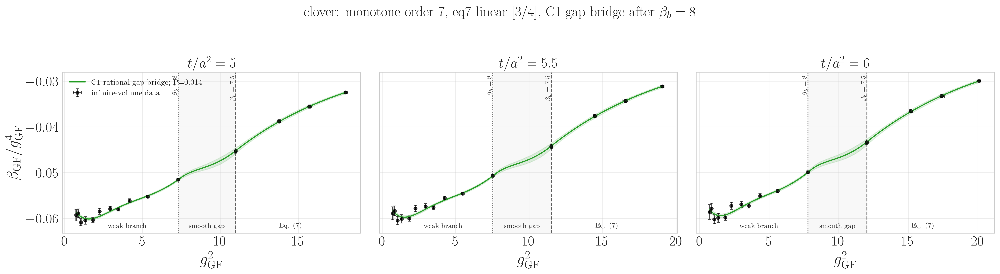

[beta/g^4 candidate plot 24/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_3_4_match_gap_8p00_7p50_c


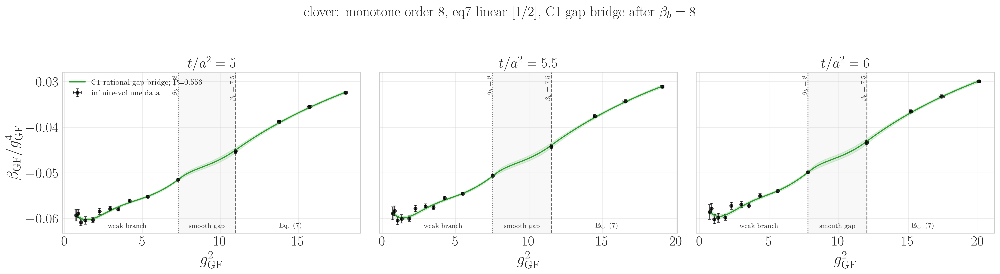

[beta/g^4 candidate plot 25/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_1_2_match_gap_8p00_7p50_c


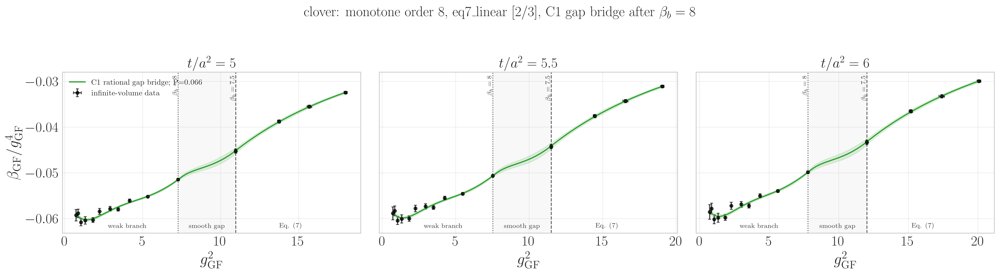

[beta/g^4 candidate plot 26/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_2_3_match_gap_8p00_7p50_c


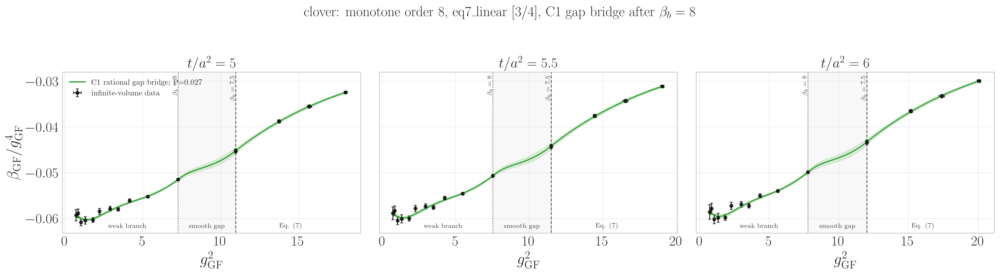

[beta/g^4 candidate plot 27/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_3_4_match_gap_8p00_7p50_c


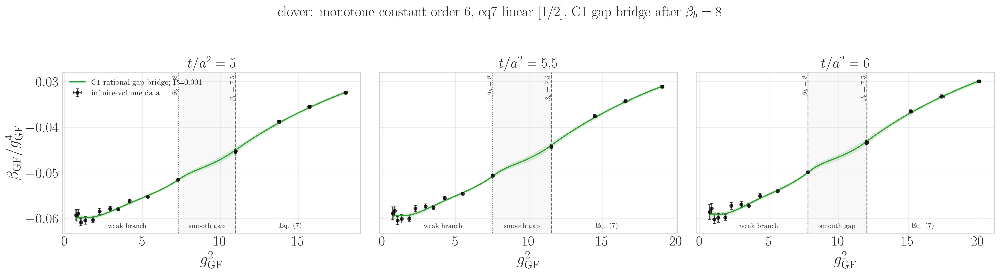

[beta/g^4 candidate plot 28/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_1_2_match_gap_8p00_7p50_c


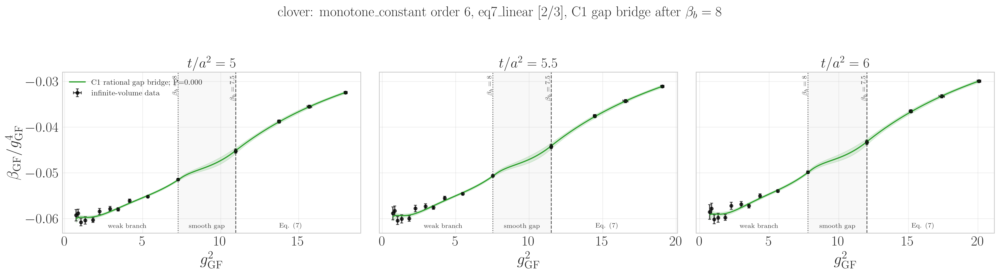

[beta/g^4 candidate plot 29/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_2_3_match_gap_8p00_7p50_c


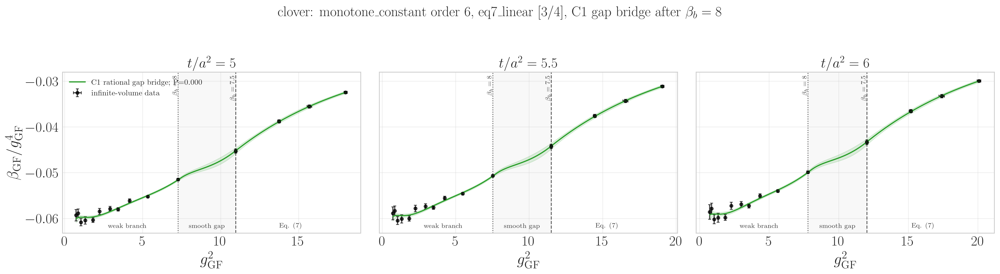

[beta/g^4 candidate plot 30/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_3_4_match_gap_8p00_7p50_c


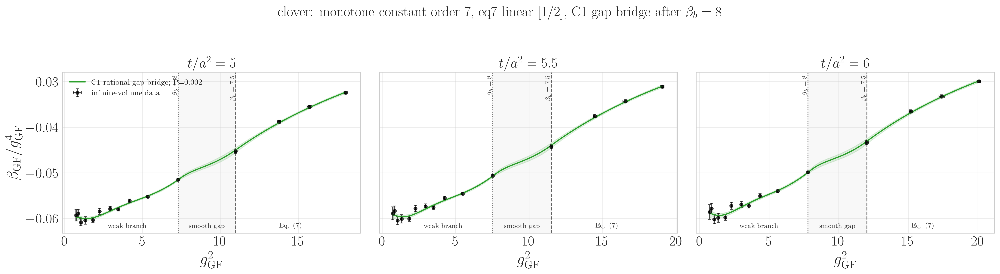

[beta/g^4 candidate plot 31/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_1_2_match_gap_8p00_7p50_c


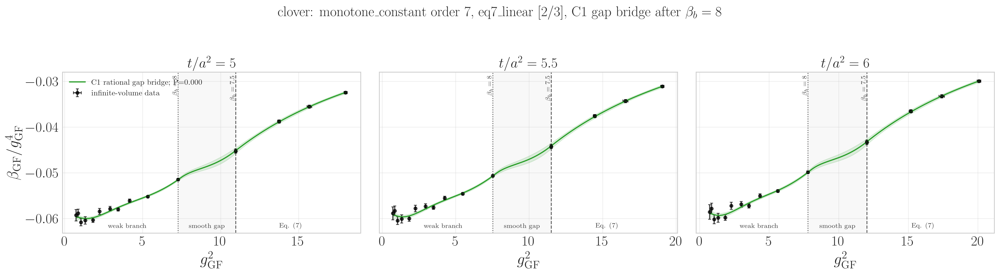

[beta/g^4 candidate plot 32/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_2_3_match_gap_8p00_7p50_c


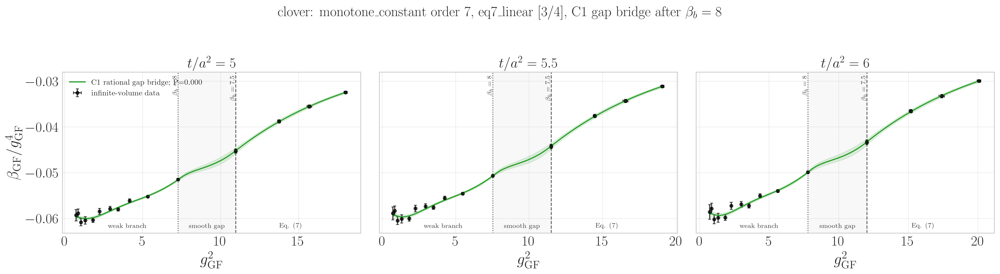

[beta/g^4 candidate plot 33/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_3_4_match_gap_8p00_7p50_c


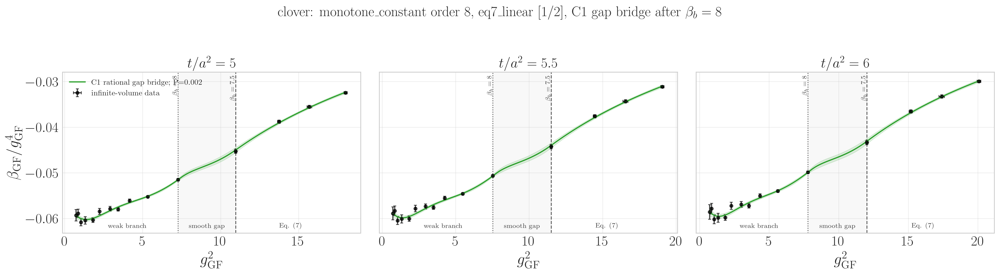

[beta/g^4 candidate plot 34/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_1_2_match_gap_8p00_7p50_c


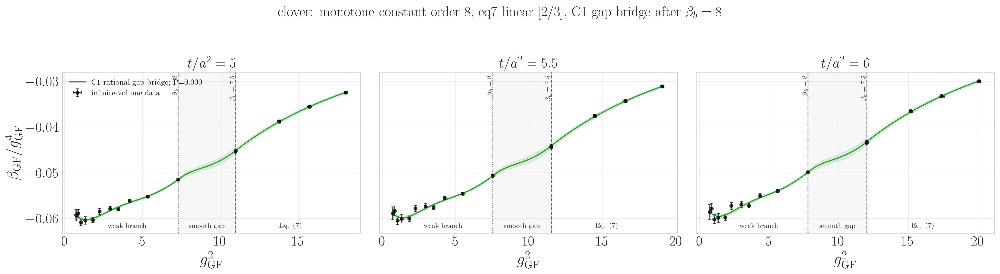

[beta/g^4 candidate plot 35/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_2_3_match_gap_8p00_7p50_c


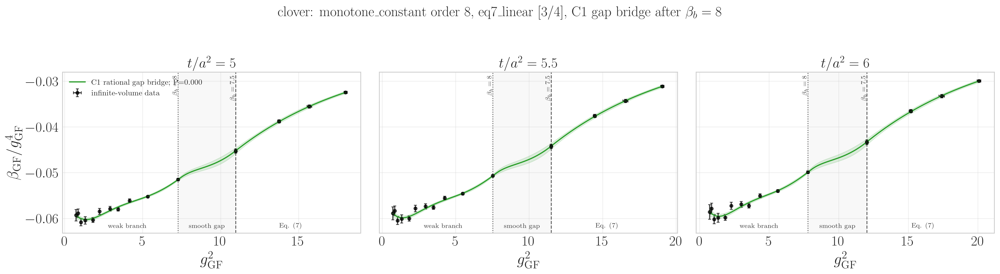

[beta/g^4 candidate plot 36/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_3_4_match_gap_8p00_7p50_c


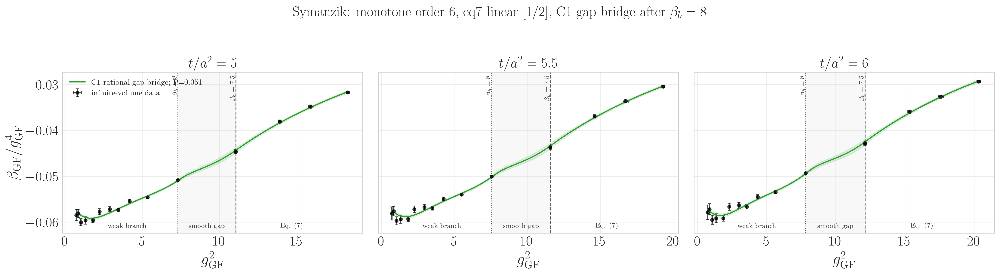

[beta/g^4 candidate plot 37/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_1_2_match_gap_8p00_7p50_s


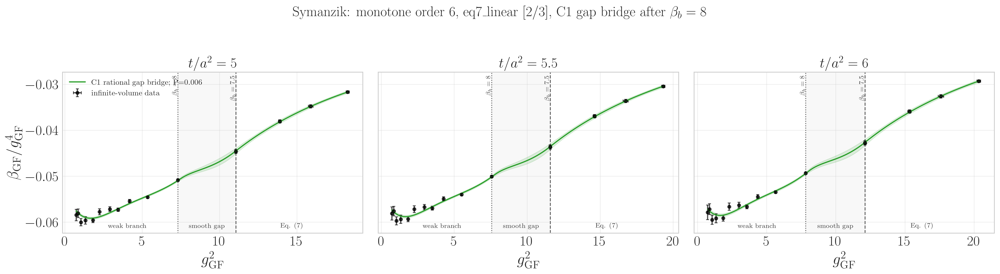

[beta/g^4 candidate plot 38/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_2_3_match_gap_8p00_7p50_s


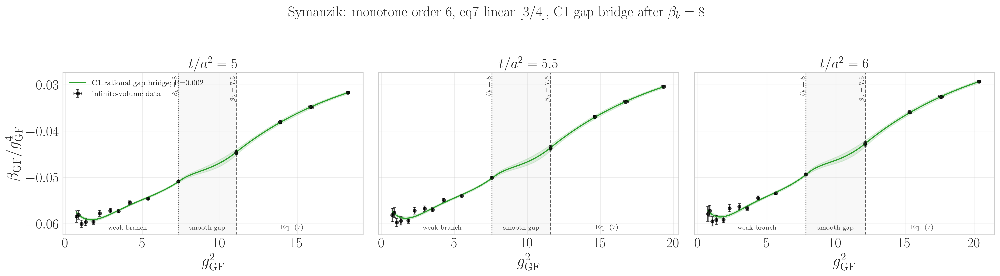

[beta/g^4 candidate plot 39/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o6_eq7_linear_3_4_match_gap_8p00_7p50_s


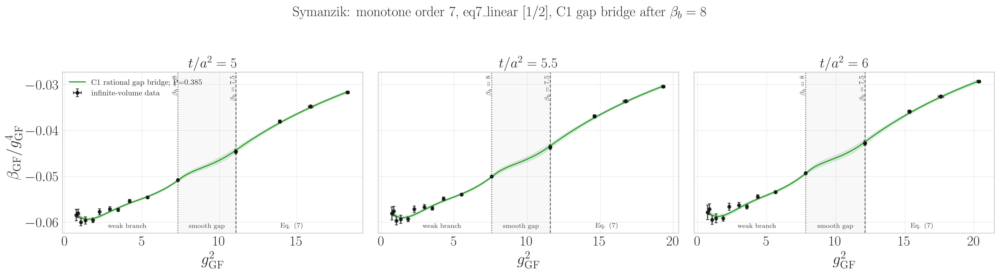

[beta/g^4 candidate plot 40/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_1_2_match_gap_8p00_7p50_s


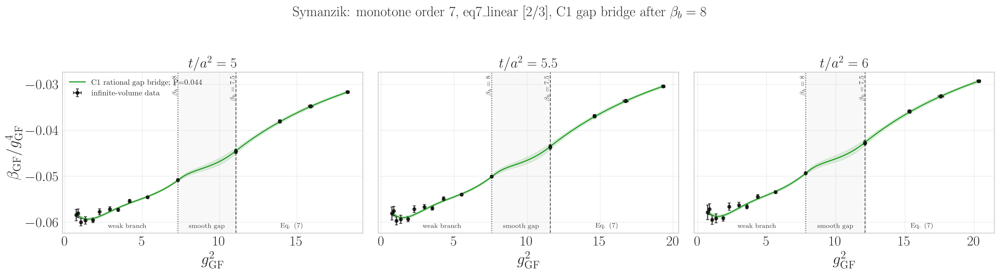

[beta/g^4 candidate plot 41/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_2_3_match_gap_8p00_7p50_s


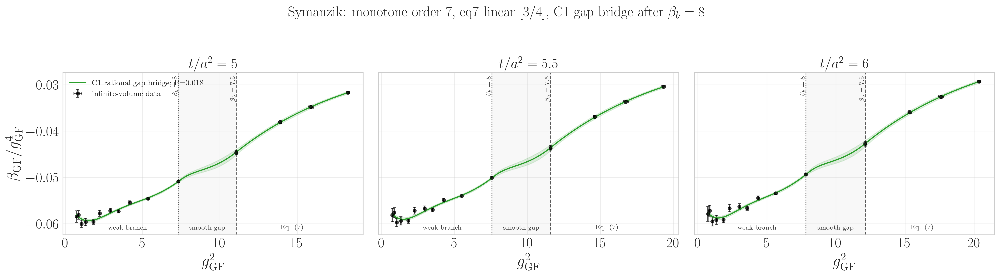

[beta/g^4 candidate plot 42/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o7_eq7_linear_3_4_match_gap_8p00_7p50_s


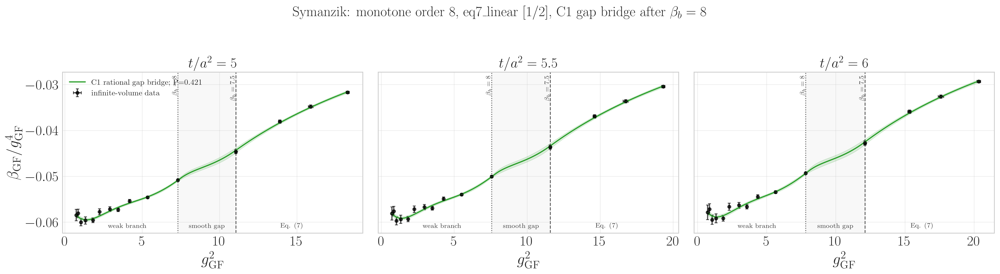

[beta/g^4 candidate plot 43/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_1_2_match_gap_8p00_7p50_s


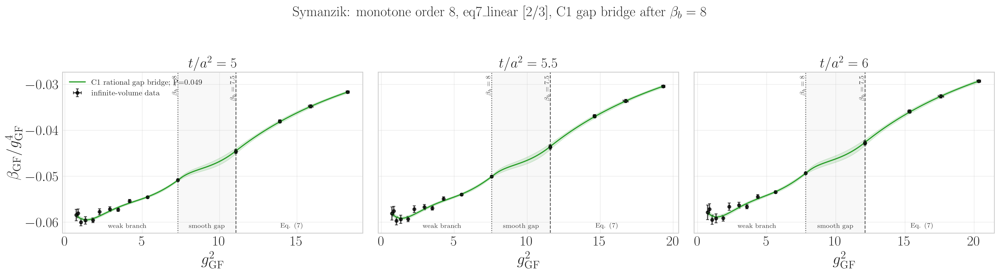

[beta/g^4 candidate plot 44/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_2_3_match_gap_8p00_7p50_s


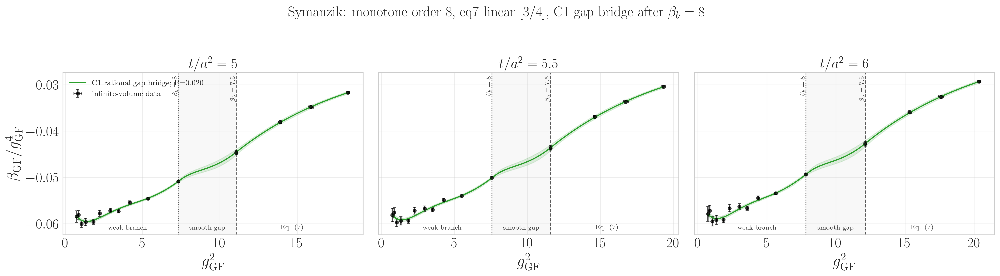

[beta/g^4 candidate plot 45/54] hybrid_candidate_interpolation_beta_over_g4_monotone_o8_eq7_linear_3_4_match_gap_8p00_7p50_s


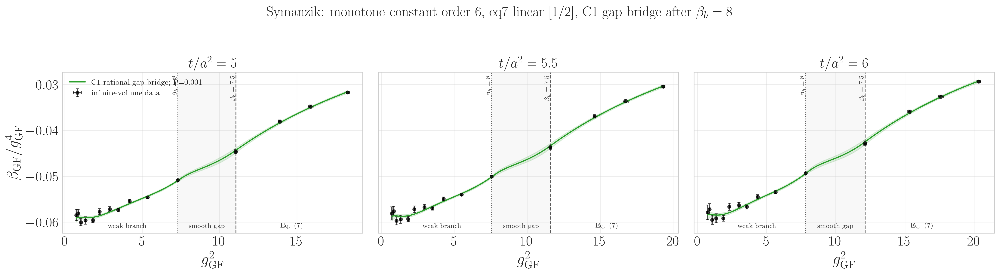

[beta/g^4 candidate plot 46/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_1_2_match_gap_8p00_7p50_s


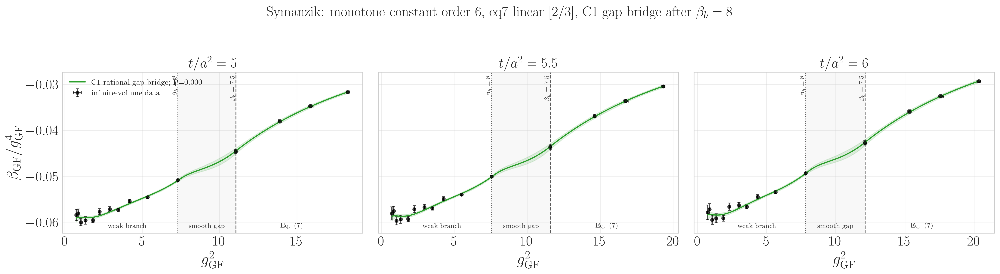

[beta/g^4 candidate plot 47/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_2_3_match_gap_8p00_7p50_s


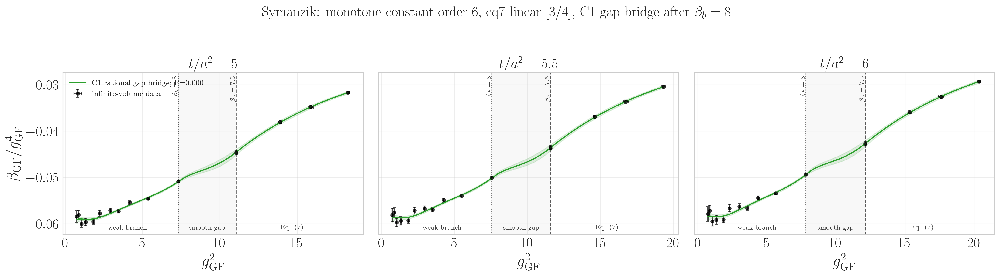

[beta/g^4 candidate plot 48/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o6_eq7_linear_3_4_match_gap_8p00_7p50_s


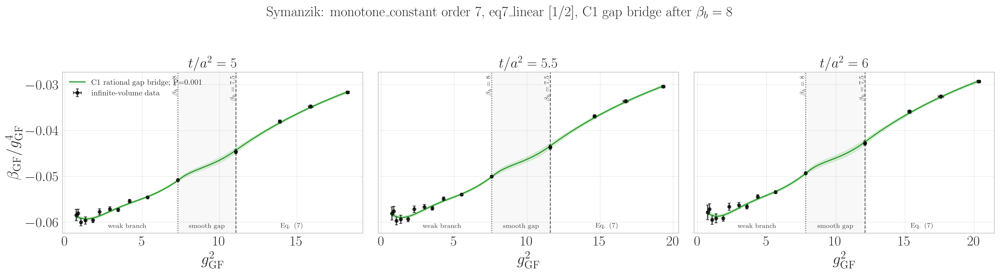

[beta/g^4 candidate plot 49/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_1_2_match_gap_8p00_7p50_s


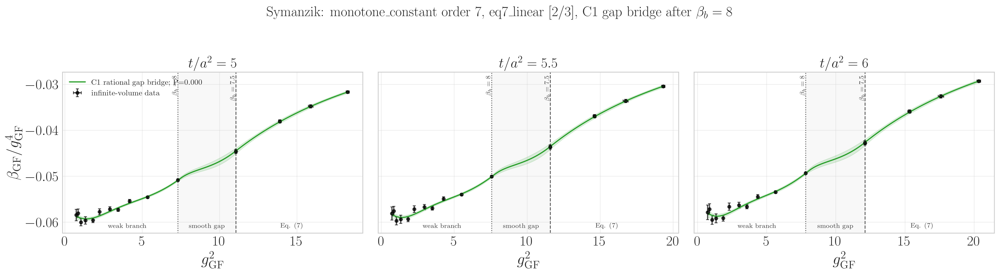

[beta/g^4 candidate plot 50/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_2_3_match_gap_8p00_7p50_s


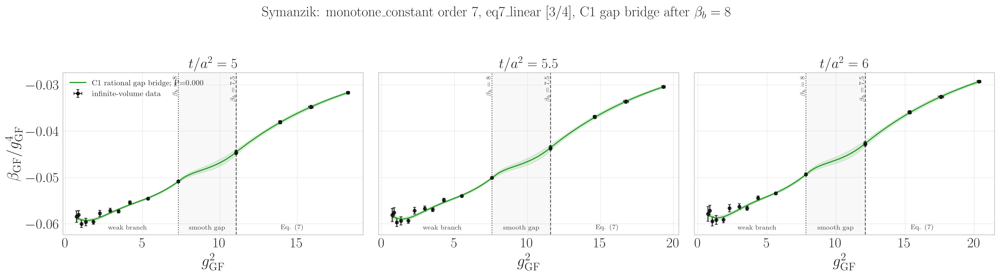

[beta/g^4 candidate plot 51/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o7_eq7_linear_3_4_match_gap_8p00_7p50_s


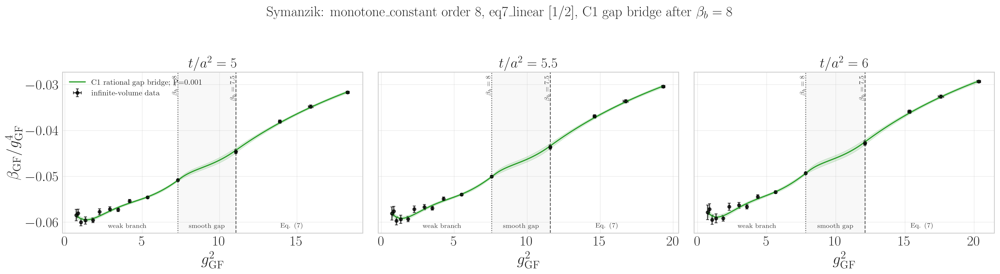

[beta/g^4 candidate plot 52/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_1_2_match_gap_8p00_7p50_s


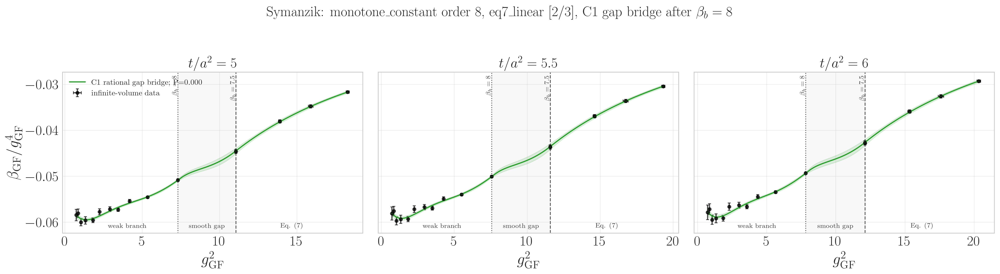

[beta/g^4 candidate plot 53/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_2_3_match_gap_8p00_7p50_s


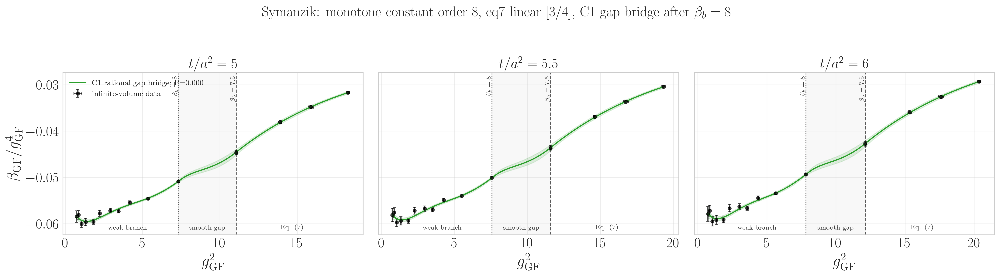

[beta/g^4 candidate plot 54/54] hybrid_candidate_interpolation_beta_over_g4_monotone_constant_o8_eq7_linear_3_4_match_gap_8p00_7p50_s


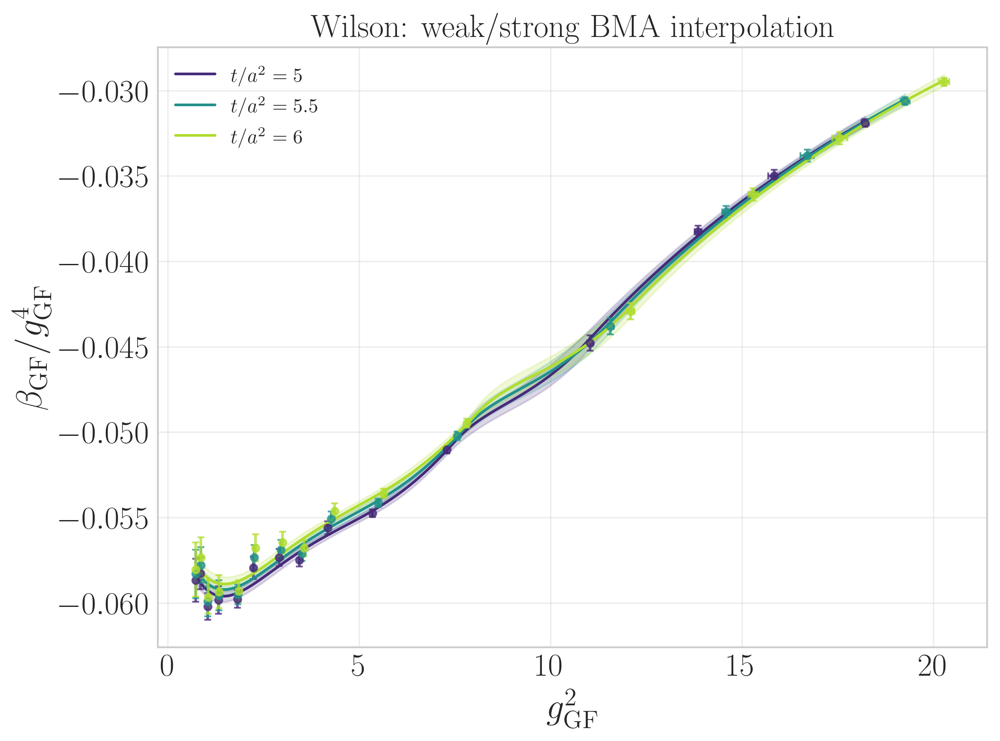

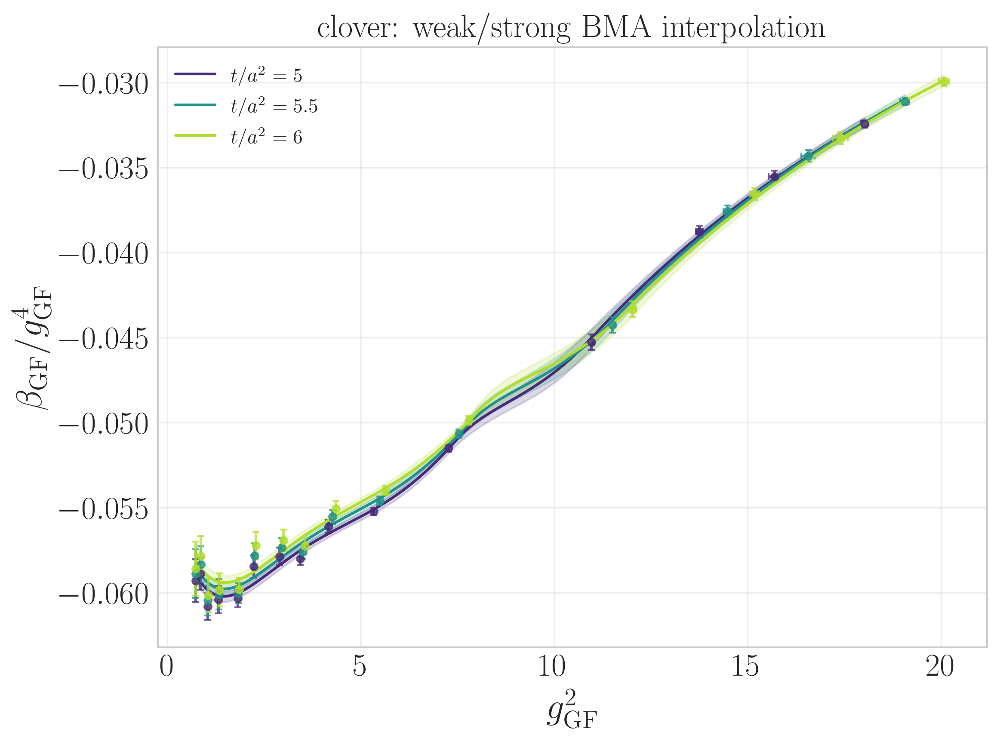

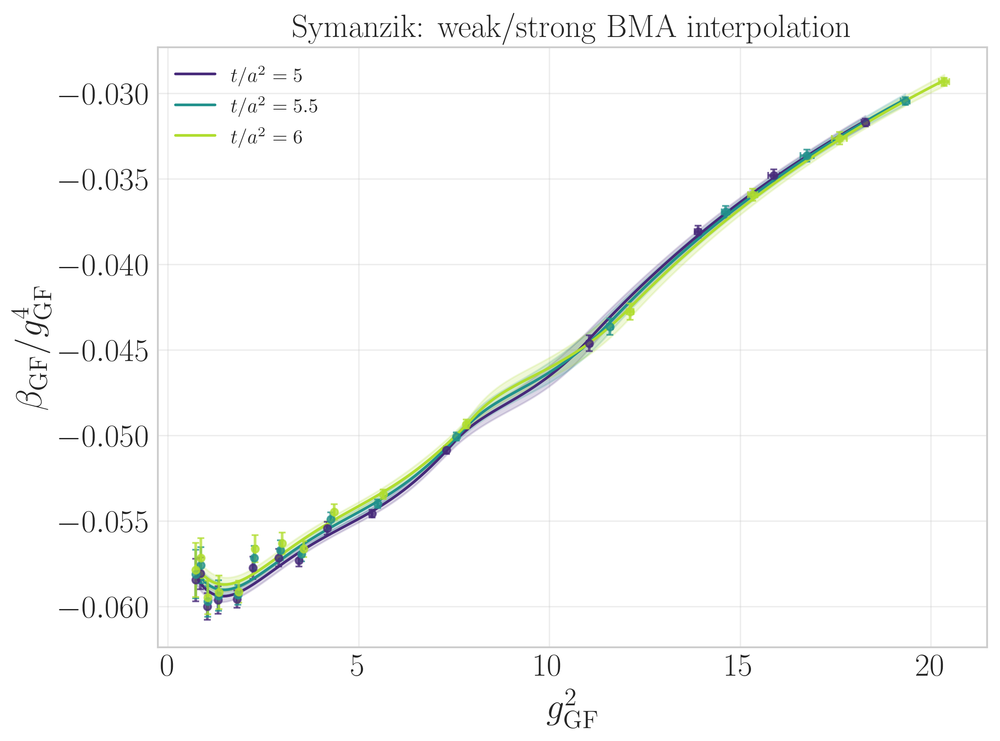

[DONE] candidate and model-averaged beta/g^4 interpolation plots (0.8 min)


In [55]:
# Companion interpolation plots for beta_GF / g_GF^4.
# Run directly after the beta_GF interpolation-curve cell above.
progress_start('candidate and model-averaged beta/g^4 interpolation plots')

def add_hybrid_region_guides(ax, target, xmin, xmax):
    join_low = float(target.match_low)
    join_high = float(target.match_high)
    ax.axvspan(join_low, join_high, color='0.5', alpha=.055, zorder=0)
    ax.axvline(join_low, color='0.35', ls=':', lw=1.1, zorder=1)
    ax.axvline(join_high, color='0.35', ls='--', lw=1.1, zorder=1)
    transform = ax.get_xaxis_transform()
    for x_position, label in (
        (.5 * (xmin + join_low), 'weak branch'),
        (.5 * (join_low + join_high), 'smooth gap'),
        (.5 * (join_high + xmax), 'Eq. (7)'),
    ):
        ax.text(
            x_position, .025, label, transform=transform,
            ha='center', va='bottom', fontsize=8.5, color='0.25',
        )
    ax.text(
        join_low, .98, r'$\beta_b=8$', transform=transform,
        ha='right', va='top', fontsize=8.5, color='0.25', rotation=90,
    )
    ax.text(
        join_high, .98, r'$\beta_b=7.5$', transform=transform,
        ha='right', va='top', fontsize=8.5, color='0.25', rotation=90,
    )


def hybrid_variant_label(candidate_fit, interpolation_result, name):
    candidate = candidate_fit.candidate
    if candidate.strong_form == 'eq7_linear':
        prefix = 'C1 rational gap bridge'
    elif candidate.strong_form == 'eq7_hermite':
        prefix = 'C1 Hermite bridge'
    elif candidate.strong_form == 'eq7_blend':
        prefix = 'C2 gap blend'
    else:
        fraction = hybrid_match_fraction(candidate_fit)
        prefix = (
            f'C{candidate.continuity}; '
            f'f={gv.mean(fraction):.3f}({gv.sdev(fraction):.3f})'
        )
    return prefix + f'; P={interpolation_result.weights[name]:.3f}'


for plot_index, (
    operator, selected_keys, group_key, variant_names
) in enumerate(candidate_plot_jobs, start=1):
    fig, axes = plt.subplots(
        1, len(selected_keys), figsize=(6 * len(selected_keys), 5),
        squeeze=False, sharey=True,
    )
    for ax, key in zip(axes.ravel(), selected_keys):
        interpolation_result = central_interpolations[key]
        variants = sorted(
            [
                (name, interpolation_result.candidate_fits[name])
                for name in variant_names
            ],
            key=lambda item: item[1].candidate.continuity,
        )
        reference_fit = variants[0][1]
        target = reference_fit.targets[key]
        target_x = np.asarray(target.x, dtype=object)
        target_ratio = np.asarray(target.y, dtype=object) / target_x**2
        xmin, xmax = min(gv.mean(target_x)), max(gv.mean(target_x))
        xgrid = np.unique(np.r_[np.linspace(xmin, xmax, 240),
            target.match_low, target.match_high,
            target.match_low + .05*(target.match_high-target.match_low)])
        add_hybrid_region_guides(ax, target, xmin, xmax)
        ax.errorbar(
            gv.mean(target_x), gv.mean(target_ratio),
            xerr=gv.sdev(target_x), yerr=gv.sdev(target_ratio),
            fmt='o', ms=4, capsize=2, color='black', alpha=.70,
            label='infinite-volume data',
        )
        for name, candidate_fit in variants:
            continuity = candidate_fit.candidate.continuity
            prediction = np.asarray(
                betafn.fitting.hybrid.evaluate_hybrid_target(
                    candidate_fit, bf, key, xgrid
                ), dtype=object,
            ) / xgrid**2
            mean, sdev = gv.mean(prediction), gv.sdev(prediction)
            color = continuity_colors.get(
                continuity, f'C{continuity % 10}'
            )
            ax.plot(
                xgrid, mean, color=color,
                ls=continuity_styles.get(continuity, '-'),
                label=hybrid_variant_label(
                    candidate_fit, interpolation_result, name
                ),
            )
            ax.fill_between(
                xgrid, mean-sdev, mean+sdev, color=color, alpha=.14,
            )
        ax.set_title(rf'$t/a^2={float(key[2]):g}$')
        ax.set_xlabel(r'$g^2_{\rm GF}$')
    axes.ravel()[0].set_ylabel(
        r'$\beta_{\rm GF}/g_{\rm GF}^4$'
    )
    axes.ravel()[0].legend(frameon=False, fontsize=10)
    (family, order, strong_form, numerator, denominator, fraction,
     match_lower, match_upper) = group_key
    if strong_form == 'eq7_linear':
        transition = r'C1 gap bridge after $\beta_b=8$'
    elif strong_form == 'eq7_hermite':
        transition = r'C1 Hermite $\beta_b=8\to7.5$ bridge'
    elif strong_form == 'eq7_blend':
        transition = r'C2 $\beta_b=8\to7.5$ blend'
    elif fraction is None:
        transition = f'match fitted in [{match_lower:.2f}, {match_upper:.2f}]'
    else:
        transition = f'match={fraction:.2f}'
    fig.suptitle(
        f'{OP_LABELS[operator]}: {family} order {order}, '
        f'{strong_form} [{numerator}/{denominator}], ' + transition
    )
    fig.tight_layout(rect=(0, 0, 1, .94))
    fraction_tag = (
        'gap_8p00_7p50'
        if strong_form in ('eq7_blend', 'eq7_hermite', 'eq7_linear')
        else (
            f'fitted_{match_lower:.2f}_{match_upper:.2f}'.replace('.', 'p')
            if fraction is None else f'{fraction:.2f}'.replace('.', 'p')
        )
    )
    base = HYBRID_OUTPUT_ROOT / (
        f'hybrid_candidate_interpolation_beta_over_g4_{family}_o{order}_'
        f'{strong_form}_{numerator}_{denominator}_match_{fraction_tag}_'
        f'{operator}'
    )
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
    print(
        f'[beta/g^4 candidate plot {plot_index}/'
        f'{len(candidate_plot_jobs)}] {base.name}', flush=True,
    )


for operator in OBSERVABLES:
    keys = sorted(
        [key for key in central_interpolations if key[1] == operator],
        key=lambda key: float(key[2]),
    )
    selected_indices = sorted(set((0, len(keys) // 2, len(keys) - 1)))
    fig, ax = plt.subplots(figsize=(8, 6))
    colors = plt.cm.viridis(np.linspace(.12, .88, len(selected_indices)))
    for color, selected_index in zip(colors, selected_indices):
        key = keys[selected_index]
        interpolation_result = central_interpolations[key]
        reference_fit = next(iter(interpolation_result.candidate_fits.values()))
        target = reference_fit.targets[key]
        target_x = np.asarray(target.x, dtype=object)
        target_ratio = np.asarray(target.y, dtype=object) / target_x**2
        xmin, xmax = min(gv.mean(target_x)), max(gv.mean(target_x))
        xgrid = np.unique(np.r_[np.linspace(xmin, xmax, 240),
            target.match_low, target.match_high,
            target.match_low + .05*(target.match_high-target.match_low)])
        predictions = {
            name: np.asarray(
                betafn.fitting.hybrid.evaluate_hybrid_target(
                    fit, bf, key, xgrid
                ), dtype=object,
            ) / xgrid**2
            for name, fit in interpolation_result.candidate_fits.items()
        }
        average = model_average_predictions(
            predictions, interpolation_result.weights
        )
        ax.plot(
            xgrid, average.mean, color=color,
            label=rf'$t/a^2={float(key[2]):g}$',
        )
        sigma = np.sqrt(
            np.clip(np.diag(average.covariance), 0.0, None)
        )
        ax.fill_between(
            xgrid, average.mean-sigma, average.mean+sigma,
            color=color, alpha=.18,
        )
        ax.errorbar(
            gv.mean(target_x), gv.mean(target_ratio),
            xerr=gv.sdev(target_x), yerr=gv.sdev(target_ratio),
            fmt='o', ms=4, capsize=2, color=color, alpha=.75,
        )
    ax.set_xlabel(r'$g^2_{\rm GF}$')
    ax.set_ylabel(r'$\beta_{\rm GF}/g_{\rm GF}^4$')
    ax.set_title(
        f'{OP_LABELS[operator]}: weak/strong BMA interpolation'
    )
    ax.legend(frameon=False)
    fig.tight_layout()
    base = (
        HYBRID_OUTPUT_ROOT
        / f'hybrid_bma_interpolation_beta_over_g4_{operator}'
    )
    fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
    fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)

progress_done('candidate and model-averaged beta/g^4 interpolation plots')


[START] hybrid interpolation quality-of-fit plots


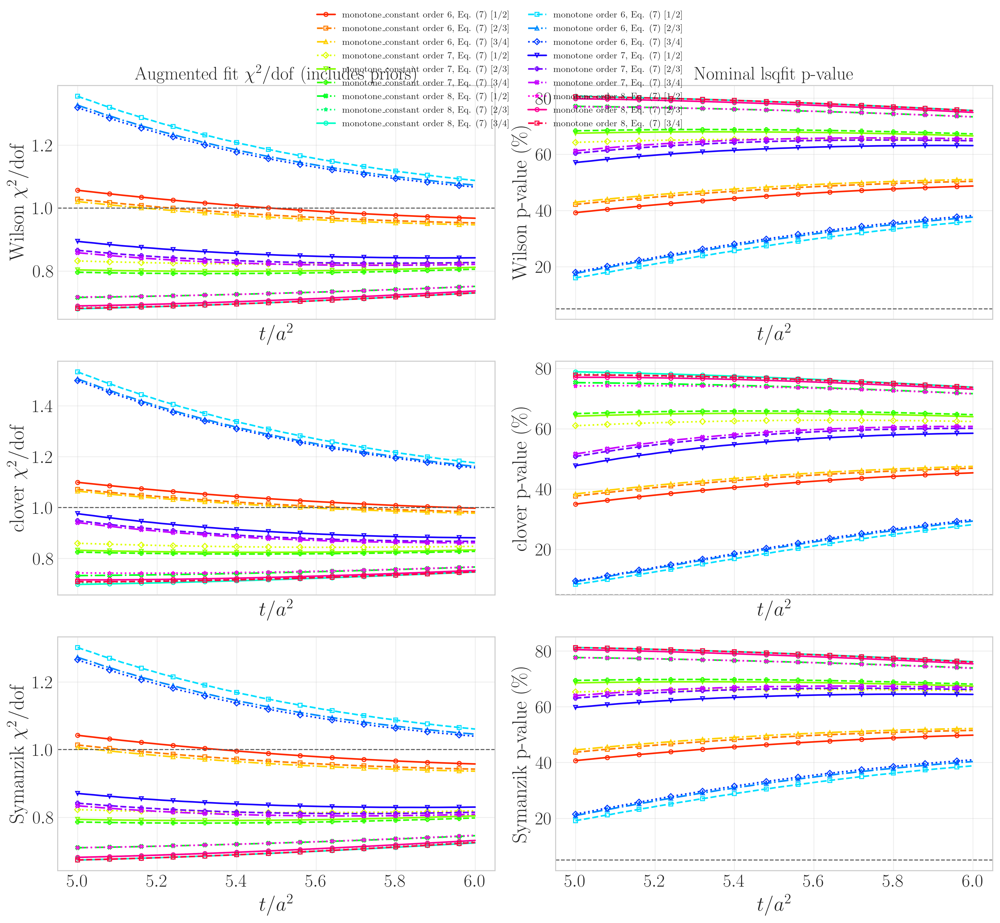

,window,operator,flow_time,model,model_label,chi2,dof,chi2_per_dof,p_value,p_value_percent,log_evidence,model_probability
9,t_5_6,c,5.00,monotone_constant_o6__eq7linear_1_2__match_gap...,"monotone_constant order 6, Eq. (7) [1/2]",16.490046,15,1.099336,0.350251,35.025105,25.521958,0.000630
27,t_5_6,c,5.01,monotone_constant_o6__eq7linear_1_2__match_gap...,"monotone_constant order 6, Eq. (7) [1/2]",16.464179,15,1.097612,0.351890,35.189034,25.497014,0.000635
45,t_5_6,c,5.02,monotone_constant_o6__eq7linear_1_2__match_gap...,"monotone_constant order 6, Eq. (7) [1/2]",16.439618,15,1.095975,0.353451,35.345102,25.471515,0.000641
63,t_5_6,c,5.03,monotone_constant_o6__eq7linear_1_2__match_gap...,"monotone_constant order 6, Eq. (7) [1/2]",16.415715,15,1.094381,0.354974,35.497367,25.445757,0.000647
81,t_5_6,c,5.04,monotone_constant_o6__eq7linear_1_2__match_gap...,"monotone_constant order 6, Eq. (7) [1/2]",16.391572,15,1.092771,0.356516,35.651552,25.420171,0.000652
...,...,...,...,...,...,...,...,...,...,...,...,...
5372,t_5_6,s,5.96,monotone_o8__eq7linear_3_4__match_gap_8p00_7p5...,"monotone order 8, Eq. (7) [3/4]",10.846350,15,0.723090,0.763408,76.340835,25.367450,0.010794
5390,t_5_6,s,5.97,monotone_o8__eq7linear_3_4__match_gap_8p00_7p5...,"monotone order 8, Eq. (7) [3/4]",10.856577,15,0.723772,0.762694,76.269352,25.328726,0.010744
5408,t_5_6,s,5.98,monotone_o8__eq7linear_3_4__match_gap_8p00_7p5...,"monotone order 8, Eq. (7) [3/4]",10.866849,15,0.724457,0.761975,76.197487,25.290090,0.010697
5426,t_5_6,s,5.99,monotone_o8__eq7linear_3_4__match_gap_8p00_7p5...,"monotone order 8, Eq. (7) [3/4]",10.877141,15,0.725143,0.761254,76.125401,25.251449,0.010648


[DONE] hybrid interpolation quality-of-fit plots (0.0 min)


In [56]:
# Interpolation goodness of fit belongs to each candidate fit.
# These are nominal lsqfit statistics including prior residuals;
# they are not a calibrated data-only test or averaged across the BMA mixture.
progress_start('hybrid interpolation quality-of-fit plots')

quality_rows = []
for window, target_results in hybrid_interpolations.items():
    for key, interpolation_result in target_results.items():
        _, operator, flow_time = key
        for name, candidate_fit in interpolation_result.candidate_fits.items():
            fit = candidate_fit.fit
            dof = int(fit.dof)
            candidate = candidate_fit.candidate
            quality_rows.append({
                'window': window_tag(window),
                'operator': operator,
                'flow_time': float(flow_time),
                'model': name,
                'model_label': (
                    f'{candidate.weak_family} order {candidate.weak_order}, '
                    f'Eq. (7) [{candidate.numerator_order}/'
                    f'{candidate.denominator_order}]'
                ),
                'chi2': float(fit.chi2),
                'dof': dof,
                'chi2_per_dof': (
                    float(fit.chi2) / dof if dof > 0 else np.nan
                ),
                'p_value': float(fit.Q),
                'p_value_percent': 100.0 * float(fit.Q),
                'log_evidence': float(candidate_fit.log_evidence),
                'model_probability': float(
                    interpolation_result.weights[name]
                ),
            })

hybrid_interpolation_quality = pd.DataFrame(quality_rows).sort_values(
    ['window', 'operator', 'model', 'flow_time']
)
hybrid_interpolation_quality.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_interpolation_quality.csv', index=False
)

central_quality = hybrid_interpolation_quality.query(
    'window == @window_name',
    local_dict={'window_name': window_tag(CENTRAL_WINDOW)},
)
model_names = list(dict.fromkeys(central_quality['model']))
# Contrasting colors and distinct symbols also distinguish nearly overlapping fits.
quality_palette = (
    '#0072B2', '#D55E00', '#009E73', '#CC79A7',
    '#56B4E9', '#8C564B', '#B8860B', '#000000',
)
model_colors = {
    model: (
        quality_palette[index] if len(model_names) <= len(quality_palette)
        else plt.cm.hsv((index + .5) / len(model_names))
    )
    for index, model in enumerate(model_names)
}
model_markers = {
    model: ('o', 's', '^', 'D', 'v', 'P', 'X', '*')[index % 8]
    for index, model in enumerate(model_names)
}
model_linestyles = {
    model: ('-', '--', '-.', ':')[index % 4]
    for index, model in enumerate(model_names)
}
model_labels = {
    row.model: row.model_label
    for row in central_quality[['model', 'model_label']].itertuples(
        index=False
    )
}

fig, axes = plt.subplots(
    len(OBSERVABLES), 2, figsize=(14, 4.2 * len(OBSERVABLES)),
    sharex=True, squeeze=False,
)
for row_index, operator in enumerate(OBSERVABLES):
    chi_ax, p_ax = axes[row_index]
    operator_quality = central_quality.query('operator == @operator')
    for model in model_names:
        values = operator_quality.query('model == @model').sort_values(
            'flow_time'
        )
        if values.empty:
            continue
        color = model_colors[model]
        label = model_labels[model]
        chi_ax.plot(
            values.flow_time, values.chi2_per_dof,
            marker=model_markers[model], ms=4, markevery=max(1, len(values)//12),
            markerfacecolor='none', linestyle=model_linestyles[model],
            lw=1.6, color=color, label=label,
        )
        p_ax.plot(
            values.flow_time, values.p_value_percent,
            marker=model_markers[model], ms=4, markevery=max(1, len(values)//12),
            markerfacecolor='none', linestyle=model_linestyles[model],
            lw=1.6, color=color, label=label,
        )
    chi_ax.axhline(1.0, color='0.35', ls='--', lw=1.0)
    p_ax.axhline(5.0, color='0.35', ls='--', lw=1.0)
    positive_p = operator_quality.loc[
        operator_quality.p_value_percent > 0.0, 'p_value_percent'
    ]
    if not positive_p.empty and positive_p.max() / positive_p.min() > 100.0:
        p_ax.set_yscale('log')
    chi_ax.set_ylabel(
        OP_LABELS[operator] + r'  $\chi^2/\mathrm{dof}$'
    )
    p_ax.set_ylabel(OP_LABELS[operator] + r'  p-value ($\%$)')
    chi_ax.set_xlabel(r'$t/a^2$')
    p_ax.set_xlabel(r'$t/a^2$')
axes[0, 0].set_title(r'Augmented fit $\chi^2/\mathrm{dof}$ (includes priors)')
axes[0, 1].set_title('Nominal lsqfit p-value')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc='upper center', ncol=2, frameon=False,
    fontsize=9, bbox_to_anchor=(.5, 1.015),
)
fig.tight_layout(rect=(0, 0, 1, .965))
quality_base = HYBRID_OUTPUT_ROOT / 'hybrid_interpolation_quality'
fig.savefig(quality_base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(
    quality_base.with_suffix('.png'), dpi=300, bbox_inches='tight'
)
plt.show(); plt.close(fig)
display(hybrid_interpolation_quality)
progress_done('hybrid interpolation quality-of-fit plots')


### Continuum extrapolation of the local interpolation BMAs

This stage reuses the independently fitted interpolation posteriors and their local evidence weights. At each $g^2$, the flow-time-local BMA predictions become the points in the continuum extrapolation. Their data-induced cross-flow-time covariance is retained, so correlated and diagonal weighting remain genuinely distinct. Bartlett/lugsail input errors and Bruno--Sommer diagnostics remain unchanged.


In [ ]:
progress_start('continuum extrapolation of flow-time-local BMAs')
hybrid_results = {}
hybrid_grid = np.round(
    np.arange(G2_GRID[0], G2_GRID[1] + 0.5 * G2_GRID[2], G2_GRID[2]),
    10,
)
for window in WINDOWS:
    interpolation_results = hybrid_interpolations[window]
    print('continuum extrapolation:', window, 'correlated')
    hybrid_results[(window, 'correlated')] = run_hybrid_bma_by_target(
        bf, window, FLOW, OBSERVABLES,
        weak_couplings=WEAK_COUPLINGS,
        strong_couplings=STRONG_COUPLINGS,
        g2_grid=hybrid_grid,
        candidates=HYBRID_CANDIDATES,
        cov_mode='empirical', tau0=config.tau0,
        prefit_interpolations=interpolation_results,
        max_workers=HYBRID_CONTINUUM_WORKERS,
        **HYBRID_PRIOR_WIDTHS,
    )
    print('continuum extrapolation:', window, 'diagonal')
    hybrid_results[(window, 'diagonal')] = run_hybrid_bma_by_target(
        bf, window, FLOW, OBSERVABLES,
        weak_couplings=WEAK_COUPLINGS,
        strong_couplings=STRONG_COUPLINGS,
        g2_grid=hybrid_grid,
        candidates=HYBRID_CANDIDATES,
        cov_mode='diagonal', tau0=config.tau0,
        prefit_interpolations=interpolation_results,
        max_workers=HYBRID_CONTINUUM_WORKERS,
        **HYBRID_PRIOR_WIDTHS,
    )

progress_done('continuum extrapolation of flow-time-local BMAs')


[START] continuum extrapolation of flow-time-local BMAs
continuum extrapolation: (5.0, 6.0) correlated


In [ ]:
progress_start('model-averaged continuum summary plots')
correction_label = (
    'TLN'
    if config.correction in ('tln', 'tree-level-normalization')
    else 'No TLN'
)

for window in WINDOWS:
    for mode in ('correlated', 'diagonal'):
        result = hybrid_results[(window, mode)]
        mode_label = (
            'Correlated continuum'
            if mode == 'correlated' else 'Diagonal continuum'
        )
        for divide_by_g4, stem, ylabel in (
            (False, 'hybrid_bma_continuum_beta_vs_g2',
             r'$\beta_{\rm GF}$'),
            (True, 'hybrid_bma_continuum_beta_over_g4_vs_g2',
             r'$\beta_{\rm GF}/g_{\rm GF}^4$'),
        ):
            fig, ax = plt.subplots(figsize=(8, 6))
            for operator in OBSERVABLES:
                average = result.averages[operator]
                x = result.model_variance_by_choice[operator]['g2']
                y = (
                    average.prediction / x**2
                    if divide_by_g4 else average.prediction
                )
                order = np.argsort(x)
                x = x[order]
                y = y[order]
                ax.plot(
                    x, gv.mean(y), color=OP_COLORS[operator], lw=1.8,
                    label=OP_LABELS[operator], zorder=3,
                )
                ax.fill_between(
                    x, gv.mean(y)-gv.sdev(y), gv.mean(y)+gv.sdev(y),
                    color=OP_COLORS[operator], alpha=.18, linewidth=0,
                    zorder=2,
                )

            plot_xmax = max(G2_GRID[1], G2_T0) + .25
            xp = np.linspace(.001, plot_xmax, 900)
            for loops, linestyle, label in (
                (1, '-', '1-loop universal'),
                (2, '--', '2-loop universal'),
                (3, '-.', '3-loop gradient flow'),
            ):
                perturbative_ratio = pt_over_g4(xp, loops)
                perturbative_curve = (
                    perturbative_ratio
                    if divide_by_g4 else xp**2 * perturbative_ratio
                )
                ax.plot(
                    xp, perturbative_curve, color='gray', ls=linestyle,
                    lw=1.5, label=label, zorder=1,
                )

            ax.text(
                .50, .52, 'Preliminary', transform=ax.transAxes,
                fontsize=42, color='gray', alpha=.25, ha='center',
                va='center', rotation=30, zorder=20, clip_on=True,
            )
            ax.text(
                .58, .15,
                (
                    'hybridBMA' + '\n' + mode_label + '\n'
                    + rf'$t/a^2\in[{window[0]:g},{window[1]:g}]$'
                    + '\n' + correction_label + '\n' + ylabel
                ),
                transform=ax.transAxes, fontsize=10.5, color='gray',
                alpha=.82, ha='center', va='center',
                fontweight='bold', zorder=20, clip_on=True,
            )
            if not divide_by_g4:
                ax.axvline(
                    G2_T0, color='black', ls=':', lw=1.5,
                    label=(
                        rf'$g^2_{{\mathrm{{GF}}}}(t_0)'
                        rf'=\frac{{8}}{{5}}\pi^2={G2_T0:.9f}$'
                    ),
                    zorder=1,
                )
                ax.set_ylim(-13.0, .5)
            else:
                ax.set_ylim(-.065, -.035)
            ax.set(
                xlim=(0, plot_xmax),
                xlabel=r'$g^2_{\rm GF}$', ylabel=ylabel,
            )
            ax.legend(ncol=2, frameon=False, fontsize=10)
            if window == CENTRAL_WINDOW and mode == 'correlated':
                central_base = HYBRID_OUTPUT_ROOT / stem
                fig.savefig(
                    central_base.with_suffix('.pdf'), bbox_inches='tight',
                )
                fig.savefig(
                    central_base.with_suffix('.png'), dpi=300,
                    bbox_inches='tight',
                )
            save_figure(fig, window, stem, mode)

progress_done('model-averaged continuum summary plots')


### Full interpolation-model error budget for $\beta(g^2)$

The statistical component propagates the within-model covariance of every local BMA. Local between-model variance is allocated among weak family, weak order, Padé order, and matching smoothness with Shapley effects, then propagated through the continuum fit. Continuum-window and covariance-treatment sensitivities are reported separately. Chiral- and infinite-volume-model systematics still require explicit alternative models.


In [ ]:
progress_start('hybrid beta-function error budget')
central = hybrid_results[(CENTRAL_WINDOW, 'correlated')]
diagonal = hybrid_results[(CENTRAL_WINDOW, 'diagonal')]
error_rows = []
for operator in OBSERVABLES:
    average = central.averages[operator]
    x = central.model_variance_by_choice[operator]['g2']
    diagonal_average = diagonal.averages[operator]
    statistical_variance = np.diag(average.within_covariance)
    components = central.model_variance_by_choice[operator]
    covariance_variance = (diagonal_average.mean - average.mean) ** 2

    window_means = []
    for window in WINDOWS:
        result = hybrid_results[(window, 'correlated')]
        candidate_x = result.model_variance_by_choice[operator]['g2']
        mapping = {round(float(g), 12): value for g, value in zip(candidate_x, result.averages[operator].mean)}
        window_means.append(mapping)

    for index, g2 in enumerate(x):
        key = round(float(g2), 12)
        available_window_values = [values[key] for values in window_means if key in values]
        window_variance = (
            float(np.var(available_window_values, ddof=0))
            if len(available_window_values) > 1 else np.nan
        )
        model_component_variances = {
            axis: float(values[index])
            for axis, values in components.items() if axis != 'g2'
        }
        total_variance = float(statistical_variance[index]) + sum(model_component_variances.values())
        total_variance += float(covariance_variance[index])
        if np.isfinite(window_variance):
            total_variance += window_variance
        mean = float(average.mean[index])
        row = {
            'operator': operator, 'g2': float(g2), 'beta_mean': mean,
            'statistical_percent': float(relative_partial_uncertainty_percent(statistical_variance[index], mean)),
            'continuum_covariance_percent': float(relative_partial_uncertainty_percent(covariance_variance[index], mean)),
            'continuum_window_percent': (
                float(relative_partial_uncertainty_percent(window_variance, mean))
                if np.isfinite(window_variance) else np.nan
            ),
            'chiral_model_percent': np.nan,
            'infinite_volume_model_percent': np.nan,
            'total_available_percent': float(relative_partial_uncertainty_percent(total_variance, mean)),
        }
        for axis, variance in model_component_variances.items():
            row[f'interpolation_{axis}_percent'] = float(
                relative_partial_uncertainty_percent(variance, mean)
            )
        error_rows.append(row)

hybrid_beta_error_budget = pd.DataFrame(error_rows)
hybrid_beta_error_budget.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_beta_error_budget.csv', index=False
)
component_columns = [
    column for column in hybrid_beta_error_budget
    if column.endswith('_percent')
    and column not in ('total_available_percent',)
    and hybrid_beta_error_budget[column].notna().any()
]
fig, axes = plt.subplots(1, len(OBSERVABLES), figsize=(17, 5), sharey=True)
for ax, operator in zip(np.atleast_1d(axes), OBSERVABLES):
    rows = hybrid_beta_error_budget.query('operator == @operator')
    for column in component_columns:
        ax.plot(rows.g2, rows[column], lw=1.2, label=column.replace('_percent', '').replace('_', ' '))
    ax.plot(rows.g2, rows.total_available_percent, color='black', lw=2.2, label='total available')
    ax.set_title(OP_LABELS[operator]); ax.set_xlabel(r'$g^2_{\rm GF}$'); ax.set_yscale('log')
axes[0].set_ylabel(r'partial relative uncertainty [\%]')
axes[-1].legend(frameon=False, fontsize=8)
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_beta_error_budget'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
print(hybrid_beta_error_budget)

progress_done('hybrid beta-function error budget')


### Bruno--Sommer continuum goodness of fit

The ordinary continuum-fit statistic and generalized Bruno--Sommer expectation and $p$-value are computed from the actual covariance $C$ and covariance used for weighting. With model Jacobian $J$, weight square root $W$, and $P=WJ(J^T W^2J)^{-1}J^TW$,

$$
\chi^2 \sim \sum_k \lambda_k z_k^2,
\qquad
\{\lambda_k\}=\operatorname{eig}\!\left[C^{1/2}W(1-P)WC^{1/2}\right].
$$

This diagnostic is unchanged by making the preceding interpolation fits independent.


In [ ]:
progress_start('generalized continuum goodness of fit')
gof_rows = []
for (window, mode), result in hybrid_results.items():
    for operator in OBSERVABLES:
        for g2, entry in zip(result.g2, result.continuum_quality[operator]):
            if entry is None:
                continue
            gof_rows.append({
                'window': window_tag(window), 'mode': mode,
                'interpolation': 'flow_time_local_bma',
                'operator': operator, 'g2': float(g2), **entry,
            })
hybrid_continuum_gof = pd.DataFrame(gof_rows)
hybrid_continuum_gof.to_csv(
    HYBRID_OUTPUT_ROOT / 'hybrid_continuum_generalized_gof.csv', index=False
)
print(hybrid_continuum_gof.head())

progress_done('generalized continuum goodness of fit')


### Continuum extrapolation panels

Filled points are the independently model-averaged interpolation values entering the continuum fit. The line and band are obtained from those points with the selected continuum covariance treatment.


In [ ]:
progress_start('continuum extrapolation diagnostic plots')
correction_label = (
    'TLN'
    if config.correction in ('tln', 'tree-level-normalization')
    else 'No TLN'
)

for window in WINDOWS:
    for mode in ('correlated', 'diagonal'):
        result = hybrid_results[(window, mode)]
        mode_label = (
            'Correlated continuum'
            if mode == 'correlated' else 'Diagonal continuum'
        )
        targets_to_plot = tuple(
            g for g in TARGET_G2
            if result.g2[0] <= g <= result.g2[-1]
        )
        for divide_by_g4, stem, ylabel in (
            (False, 'hybrid_bma_continuum_a2_over_t_beta',
             r'$\beta_{\rm GF}$'),
            (True, 'hybrid_bma_continuum_a2_over_t_beta_over_g4',
             r'$\beta_{\rm GF}/g_{\rm GF}^4$'),
        ):
            fig, axes = plt.subplots(
                2, 4, figsize=(18, 9), squeeze=False,
            )
            for ax, requested_g2 in zip(
                axes.ravel(), targets_to_plot,
            ):
                panel_g2 = None
                for operator in OBSERVABLES:
                    grid_index = int(np.argmin(
                        np.abs(result.g2-requested_g2)
                    ))
                    g2 = float(result.g2[grid_index])
                    params = (
                        result.continuum_parameters[operator][grid_index]
                    )
                    points = (
                        result.continuum_points[operator][grid_index]
                    )
                    if params is None or points is None:
                        continue
                    panel_g2 = g2
                    normalization = (
                        g2**2 if divide_by_g4 else 1.0
                    )
                    xdata = points['x']
                    ydata = points['y'] / normalization
                    xline = np.linspace(
                        0.0, 1.05*max(xdata), 200,
                    )
                    line = (
                        params['beta'][0]
                        + params['slope'][0]*xline
                    ) / normalization
                    ax.plot(
                        xline, gv.mean(line),
                        color=OP_COLORS[operator], lw=1.5, zorder=2,
                    )
                    ax.fill_between(
                        xline, gv.mean(line)-gv.sdev(line),
                        gv.mean(line)+gv.sdev(line),
                        color=OP_COLORS[operator], alpha=.15, zorder=1,
                    )
                    ax.errorbar(
                        xdata, gv.mean(ydata), yerr=gv.sdev(ydata),
                        fmt='o', ms=5, capsize=3,
                        color=OP_COLORS[operator],
                        markerfacecolor=OP_COLORS[operator],
                        markeredgecolor=OP_COLORS[operator],
                        label=OP_LABELS[operator], zorder=4,
                    )
                if panel_g2 is not None:
                    ax.text(
                        .04, .94,
                        rf'$g^2_{{\rm GF}}={panel_g2:g}$',
                        transform=ax.transAxes, ha='left', va='top',
                        fontsize=13, zorder=20,
                    )
                ax.set_xlabel(r'$a^2/t$')
            for ax in axes.ravel()[len(targets_to_plot):]:
                ax.set_visible(False)
            axes.ravel()[0].legend(frameon=False, fontsize=11)
            fig.supylabel(ylabel)
            fig.text(
                .50, .52, 'Preliminary', fontsize=58, color='gray',
                alpha=.18, ha='center', va='center', rotation=30,
                zorder=100,
            )
            fig.text(
                .50, .025,
                (
                    'hybridBMA; ' + mode_label + '; '
                    + rf'$t/a^2\in[{window[0]:g},{window[1]:g}]$'
                    + '; ' + correction_label
                    + '; filled points are included in the fit'
                ),
                fontsize=11, color='gray', alpha=.9, ha='center',
                va='bottom', fontweight='bold', zorder=100,
            )
            fig.tight_layout(rect=(.025, .075, 1, 1))
            if window == CENTRAL_WINDOW and mode == 'correlated':
                central_base = HYBRID_OUTPUT_ROOT / stem
                fig.savefig(
                    central_base.with_suffix('.pdf'), bbox_inches='tight',
                )
                fig.savefig(
                    central_base.with_suffix('.png'), dpi=300,
                    bbox_inches='tight',
                )
            save_figure(fig, window, stem, mode)

progress_done('continuum extrapolation diagnostic plots')


### Blinded $\Lambda$ parameter from the continuum beta function

The blinded $\Lambda$ integral uses the continuum beta-function posterior obtained from the flow-time-local interpolation BMAs. The within-model contribution is propagated separately; the remaining variance is reported as the local interpolation-model contribution.


In [ ]:
progress_start('blinded Lambda analysis')
from betafn.blinding import add_blinded_watermark, blind_lambda_estimate
from betafn.weak_coupling import constrained_smooth_match, lambda_parameter_from_smooth_beta

central = hybrid_results[(CENTRAL_WINDOW, 'correlated')]
hybrid_lambda_rows = []
for operator in OBSERVABLES:
    continuum_average = central.averages[operator]
    x = central.model_variance_by_choice[operator]['g2']
    beta = continuum_average.prediction
    if x[-1] < G2_T0 - 1e-10:
        raise RuntimeError(
            f'{operator}: continuum curve does not reach g^2(t0)'
        )
    ratio = beta / x**2
    smooth = constrained_smooth_match(
        x, ratio, pt_over_g4,
        match_window=(max(float(x[0]), .9), 1.2),
        correction_powers=(3, 4),
    )
    estimate = lambda_parameter_from_smooth_beta(
        x, ratio, smooth, bf.perturbative_beta_function,
        reference_g2=G2_T0,
    )
    lambda_gf = estimate['lambda_gf_over_mu']

    within_beta = np.asarray(gv.gvar(
        continuum_average.mean,
        continuum_average.within_covariance,
    ), dtype=object)
    within_smooth = constrained_smooth_match(
        x, within_beta / x**2, pt_over_g4,
        match_window=(max(float(x[0]), .9), 1.2),
        correction_powers=(3, 4),
    )
    within_estimate = lambda_parameter_from_smooth_beta(
        x, within_beta / x**2, within_smooth,
        bf.perturbative_beta_function, reference_g2=G2_T0,
    )['lambda_gf_over_mu']
    within_lambda_variance = float(gv.sdev(within_estimate) ** 2)
    total_lambda_variance = float(gv.sdev(lambda_gf) ** 2)
    between_lambda_variance = max(
        total_lambda_variance - within_lambda_variance, 0.0
    )
    report = {
        'lambda_gf_over_mu': {
            'central': float(gv.mean(lambda_gf)),
            'plus_sigma': float(gv.mean(lambda_gf) + gv.sdev(lambda_gf)),
            'minus_sigma': float(gv.mean(lambda_gf) - gv.sdev(lambda_gf)),
        },
        'lambda_msbar_over_mu': {},
        'lambda_msbar_over_lambda_gf': float(bf.perturbative_beta_function.lambda_msbar_over_lambda_gf),
    }
    report['lambda_msbar_over_mu'] = {
        label: report['lambda_msbar_over_lambda_gf'] * value
        for label, value in report['lambda_gf_over_mu'].items()
    }
    blinded = blind_lambda_estimate(report)
    values = blinded['lambda_gf_over_mu']
    hybrid_lambda_rows.append({
        'operator': operator, 'operator_label': OP_LABELS[operator],
        'g2_reference': G2_T0, 'lambda_values_blinded': True,
        'sqrt8t0_lambda_GF_central': values['central'],
        'sqrt8t0_lambda_GF_low': min(values['plus_sigma'], values['minus_sigma']),
        'sqrt8t0_lambda_GF_high': max(values['plus_sigma'], values['minus_sigma']),
        'within_model_variance': within_lambda_variance,
        'between_model_variance': between_lambda_variance,
    })

hybrid_lambda_table = pd.DataFrame(hybrid_lambda_rows)
hybrid_lambda_table.to_csv(HYBRID_OUTPUT_ROOT / 'hybrid_bma_lambda_blinded.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
for index, row in hybrid_lambda_table.iterrows():
    center = row.sqrt8t0_lambda_GF_central
    ax.errorbar(
        index, center,
        yerr=[[center-row.sqrt8t0_lambda_GF_low], [row.sqrt8t0_lambda_GF_high-center]],
        fmt='o', capsize=4, color=OP_COLORS[row.operator], label=row.operator_label,
    )
ax.set_xticks(range(len(hybrid_lambda_table)), hybrid_lambda_table.operator_label)
ax.set_ylabel(r'$\sqrt{8t_0}\,\Lambda_{\rm GF}$')
ax.set_title('BLINDED hybrid-BMA result')
add_blinded_watermark(fig)
fig.tight_layout()
base = HYBRID_OUTPUT_ROOT / 'hybrid_bma_lambda_blinded'
fig.savefig(base.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(base.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show(); plt.close(fig)
print(hybrid_lambda_table)

progress_done('blinded Lambda analysis')


### Optional hybrid flow-time thinning study

This repeats the independent operator/flow-time interpolation fits, local evidence calculations, and continuum extrapolation on a boundary-anchored flow-time grid. It is disabled by default. Set `RUN_HYBRID_THINNING = True` to run spacings $\Delta(t/a^2)=0.1,0.2,0.3$.


In [ ]:
progress_start('optional hybrid thinning study')
hybrid_thinning_results = {}
if RUN_HYBRID_THINNING:
    hybrid_grid = np.round(
        np.arange(G2_GRID[0], G2_GRID[1] + 0.5 * G2_GRID[2], G2_GRID[2]), 10
    )
    for spacing in HYBRID_THINNING_SPACINGS:
        for window in WINDOWS:
            key = (float(spacing), window)
            print('hybrid thinning:', spacing, window)
            hybrid_thinning_results[key] = run_hybrid_bma_by_target(
                bf, window, FLOW, OBSERVABLES,
                weak_couplings=WEAK_COUPLINGS,
                strong_couplings=STRONG_COUPLINGS,
                g2_grid=hybrid_grid,
                candidates=HYBRID_CANDIDATES,
                cov_mode='empirical', tau0=config.tau0,
                flow_time_spacing=spacing,
                max_workers=HYBRID_MAX_WORKERS,
                checkpoint_dir=(
                    HYBRID_CHECKPOINT_ROOT
                    / f'dt_{float(spacing):.2f}'.replace('.', 'p')
                    / window_tag(window)
                ),
                **HYBRID_PRIOR_WIDTHS,
            )
    thinning_rows = []
    for (spacing, window), result in hybrid_thinning_results.items():
        for operator in OBSERVABLES:
            average = result.averages[operator]
            x = result.model_variance_by_choice[operator]['g2']
            for g2, mean, variance in zip(x, average.mean, np.diag(average.covariance)):
                thinning_rows.append({
                    'spacing': spacing, 'window': window_tag(window),
                    'operator': operator, 'g2': float(g2),
                    'beta_mean': float(mean), 'beta_sdev': float(np.sqrt(max(variance, 0.0))),
                })
    pd.DataFrame(thinning_rows).to_csv(
        HYBRID_OUTPUT_ROOT / 'hybrid_thinning_continuum.csv', index=False
    )
else:
    print('Hybrid thinning disabled.')

progress_done('optional hybrid thinning study')
